<html>
  <body>
    <header></header>
        <CENTER>
          <img src="https://professor.uvv.br/Content/img/logo-uvv.png" alt="UVV-LOGO" style = width="100px"; height="100px">
        </CENTER>
        <CENTER><b>DATA SCIENCE PROJECT</b></CENTER><br/>
        <CENTER><b>WORKFLOW PARTE 2 DO PROJETO</b></CENTER><br/>

NOME COMPLETO: ícaro Peroba Soares

LINK PARA SEU PRÓPRIO COLAB: [https://colab.research.google.com/drive/1XWieIpJzbHpIA8eyBDx12M7rhqGAQOaW?usp=sharing](https://)

**LINK PARA SEU GITHUB DO PROJETO COMPLETO - OBRIGATÓRIO (0.5 ponto)**: [Aqui](https://)

**LINK PARA SEU PRÓPRIO VÍDEO NO YOUTUBE - OBRIGATÓRIO (0.5 ponto):** [Aqui](https://)

# **Cenário Fictício**:

Prezados(as) alunos(as),

É ótimo que você como **Consultor** ( ***Data Science Consultant*** ) do **Projeto Data Science** tenha chegado no **Workflow - Parte 2: Aprendizado de Máquina** (*Machine Learnning*). A *Incrível Biblioteca*:

<center>

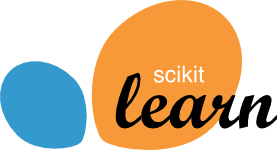

<center>

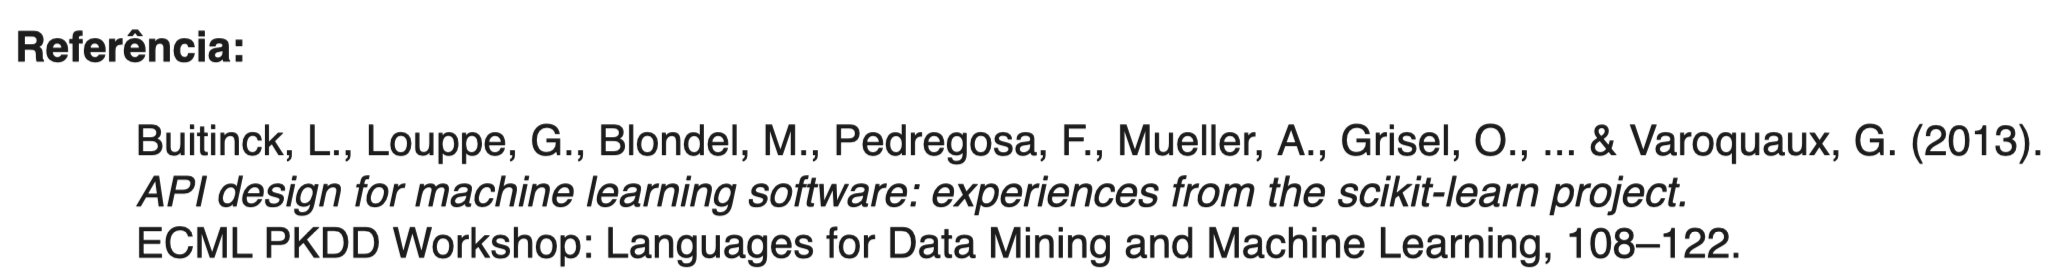

Neste etapa, você irá usar conjuntos (vários) que virão do **Workflow - Parte1**, a saber:

*   Conjunto de Treinamento: ***train***
*   Conjunto de Validação: ***validation***
*   Conjunto de Teste: ***test***

<center>

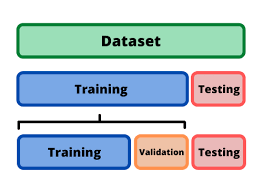

Ou seja:

<center>

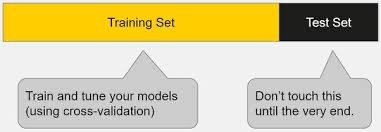


Com todas as Análises e *Insights* (**Estatistica Descritiva,** **Testes de Hipóteses** e os **Métodos Quantitativos**) que irão garatir que temos conjuntos com Qualidade (***Best Quality Analytics***) e que são ótimas amostras em relação a população ratificando justamente a importância da Parte 1 do projeto.

<center>

**EXCELENTE!!! Agora podemos ir mais longe no Universo Python!** 🚀🚀🚀

</center>

Podemos praticar as técnicas mais avançadas do **Aprendizado de Máquina** (*Machine Learnning*) e criarmos aprendizes dos seguintes modelos, a saber:

*   REGRESSOR: Modelo de Regressão: [Regression](https://scikit-learn.org/stable/supervised_learning.html)
*   CLUSTERIZADOR: Modelo de Agrupamento: [Clustering](https://scikit-learn.org/stable/modules/clustering.html)
*   CLASSIFICADOR: Modelo de Classificação:  [Classification](https://scikit-learn.org/stable/supervised_learning.html)

Para garantir organização, profundidade técnica e coerência metodológica no desenvolvimento do projeto, adotaremos um **Fluxo de Projeto (Ciclo de Vida)** composto pela atividades estabelecidas no **Workflow - Parte 2**, conforme a seguir:

# BIBLIOTECAS E FUNÇÕES E CÓDIGOS

In [1]:
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_score, cross_val_predict, train_test_split
from sklearn.metrics import (r2_score, mean_absolute_error, mean_squared_error, accuracy_score, f1_score,
                             silhouette_score, adjusted_rand_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)
from sklearn.inspection import permutation_importance
# Regressores
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import (RandomForestRegressor, HistGradientBoostingRegressor,
                              RandomForestClassifier, AdaBoostClassifier)
# Clusterização
from sklearn.cluster import KMeans
# Classificadores (lista do enunciado)
from sklearn.svm import SVC
from sklearn.gaussian_process import GaussianProcessClassifier
from sklearn.gaussian_process.kernels import RBF
from sklearn.neural_network import MLPClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

SEED = 29          # mesma semente da Parte 1 (TABLE 29)
CONF = 0.95
B = 2000           # reamostragens bootstrap
ORDEM_CONTAS = ["ESSENTIAL", "VIP", "PRIME"]
CONJUNTOS = ["train", "validation", "test"]

def brl(v, casas=2):
    s = f"{v:,.{casas}f}"
    return s.replace(",", "X").replace(".", ",").replace("X", ".")

def pct(v, casas=2):
    return brl(100 * v, casas) + "%"


### Funções auxiliares (usadas pelos três modelos)

In [2]:
def ic_validacao_cruzada(scores, conf=CONF):
    """IC t-Student para a média dos scores da validação cruzada."""
    scores = np.asarray(scores); k = len(scores)
    h = stats.t.ppf((1 + conf) / 2, k - 1) * scores.std(ddof=1) / np.sqrt(k)
    return scores.mean(), scores.mean() - h, scores.mean() + h


def bootstrap_metrica(y_true, y_pred, metrica, B=B, seed=SEED):
    """Bootstrap do score: reamostra pares (y, ŷ) com reposição e recalcula a métrica."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    rng = np.random.default_rng(seed)
    n = len(y_true)
    return np.array([metrica(y_true[i], y_pred[i]) for i in (rng.integers(0, n, n) for _ in range(B))])


def grafico_ic(boot, titulo, xlabel, ax=None, extra=None):
    """Histograma bootstrap com estimativa e IC 95%."""
    lo, hi = np.quantile(boot, [(1 - CONF) / 2, (1 + CONF) / 2])
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 4))
    sns.histplot(boot, bins=40, kde=True, ax=ax, color="#7b2c3a", alpha=.45)
    ax.axvline(boot.mean(), color="black", lw=2, label=f"Média = {brl(boot.mean(), 4)}")
    ax.axvline(lo, color="tab:blue", ls="--", label=f"IC95% inf = {brl(lo, 4)}")
    ax.axvline(hi, color="tab:blue", ls="--", label=f"IC95% sup = {brl(hi, 4)}")
    if extra:
        for v, lab in extra:
            ax.axvline(v, color="tab:green", ls=":", lw=2, label=lab)
    ax.set_title(titulo); ax.set_xlabel(xlabel); ax.set_ylabel("Frequência"); ax.legend(fontsize=8)
    return {"media": boot.mean(), "ep": boot.std(ddof=1), "ic_inf": lo, "ic_sup": hi}


## Load dos Datasets:

*Load* dos dataset aqui, a saber:

*   Conjunto de Treinamento do **TAMANHO IDEAL**: ***train***
*   Conjunto de Validação do **TAMANHO IDEAL**: ***validation***
*   Conjunto de Teste do **TAMANHO IDEAL**: ***test***

In [3]:
# Conjuntos gerados no final da A1.1 da Parte 1 (estratificados por TIPO DA CONTA, disjuntos, semente 29)
train      = pd.read_csv("train.csv", index_col=0)
validation = pd.read_csv("validation.csv", index_col=0)
test       = pd.read_csv("test.csv", index_col=0)

# População (TABLE 29) -> usada apenas para sortear a "amostra aleatória (Sample)" dos passos finais
populacao = pd.read_csv("table29.csv", index_col=0)
N_IDEAL = len(train)
usados = train.index.union(validation.index).union(test.index)
sample = populacao.drop(usados).sample(n=N_IDEAL, random_state=SEED)   # amostra aleatória simples, inédita

bases = {"train": train, "validation": validation, "test": test, "sample (população)": sample}
resumo = pd.DataFrame({k: {"n": len(v),
                           "% ESSENTIAL": 100 * (v["TIPO DA CONTA"] == "ESSENTIAL").mean(),
                           "% VIP": 100 * (v["TIPO DA CONTA"] == "VIP").mean(),
                           "% PRIME": 100 * (v["TIPO DA CONTA"] == "PRIME").mean(),
                           "Média TOTAL (R$)": v["TOTAL (R$)"].mean()} for k, v in bases.items()}).T
resumo["n"] = resumo["n"].astype(int)
print("População:", brl(len(populacao), 0), "| Linhas em comum entre os 4 conjuntos:",
      len(usados) + len(sample) - len(usados.union(sample.index)))
resumo

População: 1.120.000 | Linhas em comum entre os 4 conjuntos: 0


,n,% ESSENTIAL,% VIP,% PRIME,Média TOTAL (R$)
train,5300,63.9623,21.1321,14.9057,777.9232
validation,5300,63.9623,21.1321,14.9057,767.3439
test,5300,63.9623,21.1321,14.9057,770.7340
sample (população),5300,65.7547,19.8868,14.3585,743.5783


Qual o "TAMANHO IDEAL" do conjunto:

*   Conjunto de Treinamento: **5.300**
*   Conjunto de Validação: **5.300**
*   Conjunto de Teste: **5.300**

O tamanho ideal (**n = 5.300**) vem da Parte 1: estabilização marginal do erro-padrão estratificado com otimização de Neyman sobre TOTAL (R$).

* Cada conjunto mantém a composição da população por tipo de conta (64% ESSENTIAL, 21% VIP, 15% PRIME).
* Os conjuntos não têm nenhuma nota fiscal em comum.
* Nos testes de hipótese da Parte 1, train e validation não mostraram diferença de distribuição nem de média.

A **sample** é uma amostra aleatória simples de mais 5.300 notas da população, que nenhum modelo viu. Ela simula as ~5.000 notas novas que entram no sistema por dia.

In [4]:
# Teste rápido de coerência entre os conjuntos (KS de TOTAL contra o train)
tab_ks = pd.DataFrame({k: {"KS vs train": stats.ks_2samp(train["TOTAL (R$)"], v["TOTAL (R$)"]).statistic,
                           "p-valor": stats.ks_2samp(train["TOTAL (R$)"], v["TOTAL (R$)"]).pvalue}
                       for k, v in bases.items() if k != "train"}).T
display(tab_ks)
pe_pop = (populacao["TIPO DA CONTA"] == "ESSENTIAL").mean(); pe_s = (sample["TIPO DA CONTA"] == "ESSENTIAL").mean()
z = (pe_s - pe_pop) / np.sqrt(pe_pop * (1 - pe_pop) / len(sample))
display(Markdown(f"""
* **validation e test** não diferem do train (KS p = {brl(tab_ks.loc['validation','p-valor'], 4)} e {brl(tab_ks.loc['test','p-valor'], 4)}).
  Isso era esperado: os três são estratificados com a mesma composição de contas.
* A **sample** é uma amostra aleatória **simples**, sem estratificação. Por acaso, ela saiu com {pct(pe_s, 1)} de ESSENTIAL contra {pct(pe_pop, 1)} na população (z = {brl(z, 2)}),
  o que explica a média de TOTAL um pouco menor e o KS p = {brl(tab_ks.loc['sample (população)','p-valor'], 4)}.
  Isso **não é um problema**: é exatamente a variação que as notas novas do dia a dia podem ter. Os modelos são testados nessa amostra justamente para ver se continuam bons sob essa variação.
"""))

,KS vs train,p-valor
validation,0.0142,0.6635
test,0.0204,0.2212
sample (população),0.0289,0.0241



* **validation e test** não diferem do train (KS p = 0,6635 e 0,2212).
  Isso era esperado: os três são estratificados com a mesma composição de contas.
* A **sample** é uma amostra aleatória **simples**, sem estratificação. Por acaso, ela saiu com 65,8% de ESSENTIAL contra 64,0% na população (z = 2,71),
  o que explica a média de TOTAL um pouco menor e o KS p = 0,0241.
  Isso **não é um problema**: é exatamente a variação que as notas novas do dia a dia podem ter. Os modelos são testados nessa amostra justamente para ver se continuam bons sob essa variação.


### Pré-processamento comum: Normalizar, Mapear e Discretizar

Esta função aplica as decisões da Parte 1 a qualquer conjunto (train, validation, test ou sample):

* **Mapear:** a OPINIÃO DO CLIENTE vira uma satisfação ordinal de 1 a 5 (mesmo mapa da A3.1 da Parte 1, com as 25 frases). TIPO DA CONTA, REGIÃO, SEXO e ESTADO CIVIL viram variáveis indicadoras (one-hot) com categorias fixas.
* **Limpar:** as variáveis químicas com valor negativo, fisicamente impossível (A2.1 da Parte 1), são truncadas em zero.
* **Descartar:** NOTA FISCAL é um identificador, e a NOTA DE SATISFAÇÃO (%) é quase constante (68,68 em ~93% dos registros), então nenhuma das duas entra nos modelos.
* **Normalizar:** a padronização (StandardScaler) fica **dentro do pipeline de cada modelo** e é ajustada **apenas no train**. Assim, validation, test e sample nunca vazam informação para o ajuste.

In [5]:
NIVEIS = ["Muito Insatisfeito", "Insatisfeito", "Indiferente", "Satisfeito", "Muito Satisfeito"]
mapa_satisfacao = {
    "Serviço impecável, adorei o clube: UVVine": 5, "Excelente experiência, recomendo muito a UVVine": 5,
    "Produto perfeito, chegou antes do prazo de previsão. Top demais a UVVine": 5,
    "Ótimo! Tudo ocorreu maravilhosamente bem com a UVVine": 5, "Superou expectativas o atendimento na UVVine": 5,
    "Entrega foi boa e rápida na UVVine": 4, "Serviço eficiente, recomendo o clube: UVVine": 4,
    "Gostei do atendimento prestado pela UVVine": 4, "Funcionou bem e me atendeu no prazo certo a UVVine": 4,
    "Fiquei satisfeito com o serviço da UVVine": 4,
    "Não tenho muito a dizer sobre a UVVine": 3, "Nada digno de nota com a UVVine": 3,
    "Sem opinião formada sobre a UVVine": 3, "Compro exponenciamente, opinião neutra sobre UVVine": 3,
    "Foi indiferente minha experiência com a UVVine": 3,
    "Experiência regular, não atendeu a política de cashback da UVVine": 2, "Nada demais, serviço regular na UVVine": 2,
    "Foi aceitável, esperava mais da UVVine": 2, "Razoável, com margem de melhora no preço médio da UVVine": 2,
    "Atendimento comum, poderia melhorar em cordialidade a UVVine": 2,
    "Não gostei do atendimento na UVVine": 1, "Produto chegou atrasado na UVVine": 1,
    "Serviço deixou a desejar na UVVine": 1, "Tive uma experiência ruim com a UVVine": 1,
    "Senti que faltou qualidade no atendimento da UVVine": 1,
}
QUIMICAS = [c for c in train.columns if c.startswith("MEAN:")]
CATEGORIAS = {"TIPO DA CONTA": ORDEM_CONTAS,
              "REGIÃO": ["SUDESTE", "SUL", "CENTRO-OESTE", "NORDESTE", "NORTE"],
              "SEXO": ["MASCULINO", "FEMININO"],
              "ESTADO CIVIL": ["CASADO", "SOLTEIRO", "DESQUITADO(A) / VIÚVO(A)"]}

def preparar(base):
    """Normalizar - Mapear - Discretizar: devolve um DataFrame 100% numérico."""
    out = pd.DataFrame(index=base.index)
    out["RENDA BRUTO (R$)"] = base["RENDA BRUTO (R$)"]
    out["DEPENDENTES"] = base["DEPENDENTES"]
    opiniao = base["OPINIÃO DO CLIENTE"].str.replace(r"\s+", " ", regex=True).str.strip()
    out["SATISFACAO (1-5)"] = opiniao.map(mapa_satisfacao)
    assert out["SATISFACAO (1-5)"].notna().all(), "Há opinião sem mapeamento"
    for c in QUIMICAS:
        out[c] = base[c].clip(lower=0)
    for col, cats in CATEGORIAS.items():
        for cat in cats[1:]:                       # one-hot sem a 1ª categoria (referência)
            out[f"{col}={cat}"] = (base[col] == cat).astype(int)
    out["TOTAL (R$)"] = base["TOTAL (R$)"]
    out["CONTA_COD"] = base["TIPO DA CONTA"].map({c: i for i, c in enumerate(ORDEM_CONTAS)})
    return out

prep = {k: preparar(v) for k, v in bases.items()}
print("Negativos químicos truncados no train:", int((train[QUIMICAS] < 0).sum().sum()))
prep["train"].head().T

Negativos químicos truncados no train: 347


,920251,1115896,988532,1074520,34992
RENDA BRUTO (R$),"7,610.0300","3,232.2000","3,202.0800","3,398.9800","3,207.9100"
DEPENDENTES,1.0000,0.0000,2.0000,0.0000,1.0000
SATISFACAO (1-5),4.0000,4.0000,4.0000,4.0000,3.0000
MEAN: alcohol,12.5647,14.6752,13.6130,11.1976,12.3874
MEAN: malic_acid,1.4427,2.4533,1.1693,2.4048,2.3044
MEAN: ash,2.4106,2.4693,2.7155,2.7661,2.7986
MEAN: alcalinity_of_ash,19.4118,17.1692,22.8230,19.5395,21.0150
MEAN: magnesium,88.1494,105.6367,83.7495,89.2456,106.4585
MEAN: total_phenols,2.3623,1.4216,3.8622,1.5984,1.9759
MEAN: flavanoids,1.9416,2.0221,2.0392,0.7620,2.5865


# Workflow: Detalhamento das Atividades

#Atividade A1: Modelo de Regressão

**Pergunta de negócio:** *quanto um cliente vai gastar (TOTAL em R$) a partir do seu perfil?*

* **Alvo:** TOTAL (R$), a variável-alvo da Parte 1.
* **Entradas:** renda, dependentes, satisfação, tipo de conta, região, sexo, estado civil e as 13 características químicas.

##Atividade A1.1 (1º Passo): Normalizar - Mapear - Discretizar

In [6]:
ALVO_REG = "TOTAL (R$)"
FEATURES_REG = [c for c in prep["train"].columns if c not in (ALVO_REG, "CONTA_COD")]
print(f"{len(FEATURES_REG)} variáveis de entrada:", FEATURES_REG)
prep["train"][FEATURES_REG + [ALVO_REG]].describe().T[["mean", "std", "min", "max"]]

25 variáveis de entrada: ['RENDA BRUTO (R$)', 'DEPENDENTES', 'SATISFACAO (1-5)', 'MEAN: alcohol', 'MEAN: malic_acid', 'MEAN: ash', 'MEAN: alcalinity_of_ash', 'MEAN: magnesium', 'MEAN: total_phenols', 'MEAN: flavanoids', 'MEAN: nonflavanoid_phenols', 'MEAN: proanthocyanins', 'MEAN: color_intensity', 'MEAN: hue', 'MEAN: od280/od315_of_diluted_wines', 'MEAN: proline', 'TIPO DA CONTA=VIP', 'TIPO DA CONTA=PRIME', 'REGIÃO=SUL', 'REGIÃO=CENTRO-OESTE', 'REGIÃO=NORDESTE', 'REGIÃO=NORTE', 'SEXO=FEMININO', 'ESTADO CIVIL=SOLTEIRO', 'ESTADO CIVIL=DESQUITADO(A) / VIÚVO(A)']


,mean,std,min,max
RENDA BRUTO (R$),"7,023.1367","6,442.7576","1,858.8700","29,096.6700"
DEPENDENTES,1.0683,0.9659,0.0000,4.0000
SATISFACAO (1-5),3.7702,0.6220,1.0000,5.0000
MEAN: alcohol,13.0152,0.8057,10.0101,15.9882
MEAN: malic_acid,2.3464,1.0906,0.0000,6.1239
MEAN: ash,2.3621,0.2695,1.4062,3.3028
MEAN: alcalinity_of_ash,19.5507,3.3173,8.5436,33.4957
MEAN: magnesium,99.6211,14.1340,53.0247,155.3831
MEAN: total_phenols,2.3049,0.6292,0.0000,4.5729
MEAN: flavanoids,2.0392,0.9710,0.0000,5.7385


##Atividade A1.2 (2º Passo) - ETL: Separar Entrada ($X$) da Saída ($y$)

In [7]:
# a partir daqui temos apenas: NDARRAY
# NDARRAY: train - validation - test
Xr = {k: prep[k][FEATURES_REG].to_numpy(dtype=float) for k in prep}
yr = {k: prep[k][ALVO_REG].to_numpy(dtype=float) for k in prep}
X_train, y_train = Xr["train"], yr["train"]
X_val,   y_val   = Xr["validation"], yr["validation"]
X_test,  y_test  = Xr["test"], yr["test"]
for k in Xr:
    print(f"{k:<20} X: {Xr[k].shape}  y: {yr[k].shape}  tipo: {type(Xr[k]).__name__}")

train                X: (5300, 25)  y: (5300,)  tipo: ndarray
validation           X: (5300, 25)  y: (5300,)  tipo: ndarray
test                 X: (5300, 25)  y: (5300,)  tipo: ndarray
sample (população)   X: (5300, 25)  y: (5300,)  tipo: ndarray


##Atividade A1.3 (3º Passo): Criar o Modelo: **Regressors**

Sete regressores são comparados, cada um num pipeline `StandardScaler → modelo`. Cada um passa por validação cruzada (5 folds) no **train** e é avaliado no **validation**. O escolhido é o de **maior R² no validation**. O **test** só é usado no final.

In [8]:
regressores = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=1.0, max_iter=10000),
    "KNN (k=15)": KNeighborsRegressor(n_neighbors=15),
    "Decision Tree": DecisionTreeRegressor(max_depth=6, random_state=SEED),
    "Random Forest": RandomForestRegressor(n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=SEED),
    "Gradient Boosting": HistGradientBoostingRegressor(random_state=SEED),
}
cv5 = KFold(n_splits=5, shuffle=True, random_state=SEED)
linhas = []
for nome, modelo in regressores.items():
    pipe = make_pipeline(StandardScaler(), modelo)
    t0 = time.time()
    cv = cross_val_score(pipe, X_train, y_train, cv=cv5, scoring="r2")
    pipe.fit(X_train, y_train)
    linhas.append({"Modelo": nome, "R² CV train (média)": cv.mean(), "R² CV (desvio)": cv.std(),
                   "R² validation": r2_score(y_val, pipe.predict(X_val)),
                   "RMSE validation (R$)": np.sqrt(mean_squared_error(y_val, pipe.predict(X_val))),
                   "Tempo (s)": time.time() - t0})
tab_reg = pd.DataFrame(linhas).set_index("Modelo").sort_values("R² validation", ascending=False)
MELHOR_REG = tab_reg.index[0]
reg = make_pipeline(StandardScaler(), regressores[MELHOR_REG]).fit(X_train, y_train)
print("Melhor regressor (maior R² no validation):", MELHOR_REG)
tab_reg

Melhor regressor (maior R² no validation): Lasso


,R² CV train (média),R² CV (desvio),R² validation,RMSE validation (R$),Tempo (s)
Modelo,,,,,
Lasso,0.7441,0.0185,0.7520,406.0583,0.0337
Ridge,0.7437,0.0185,0.7518,406.2417,0.0299
Linear Regression,0.7437,0.0185,0.7518,406.2452,0.0466
Random Forest,0.7334,0.0193,0.7417,414.4279,22.2357
Gradient Boosting,0.7105,0.0168,0.7150,435.3229,1.4043
Decision Tree,0.6720,0.0188,0.6970,448.8749,0.2089
KNN (k=15),0.6673,0.0323,0.6889,454.8225,0.2277


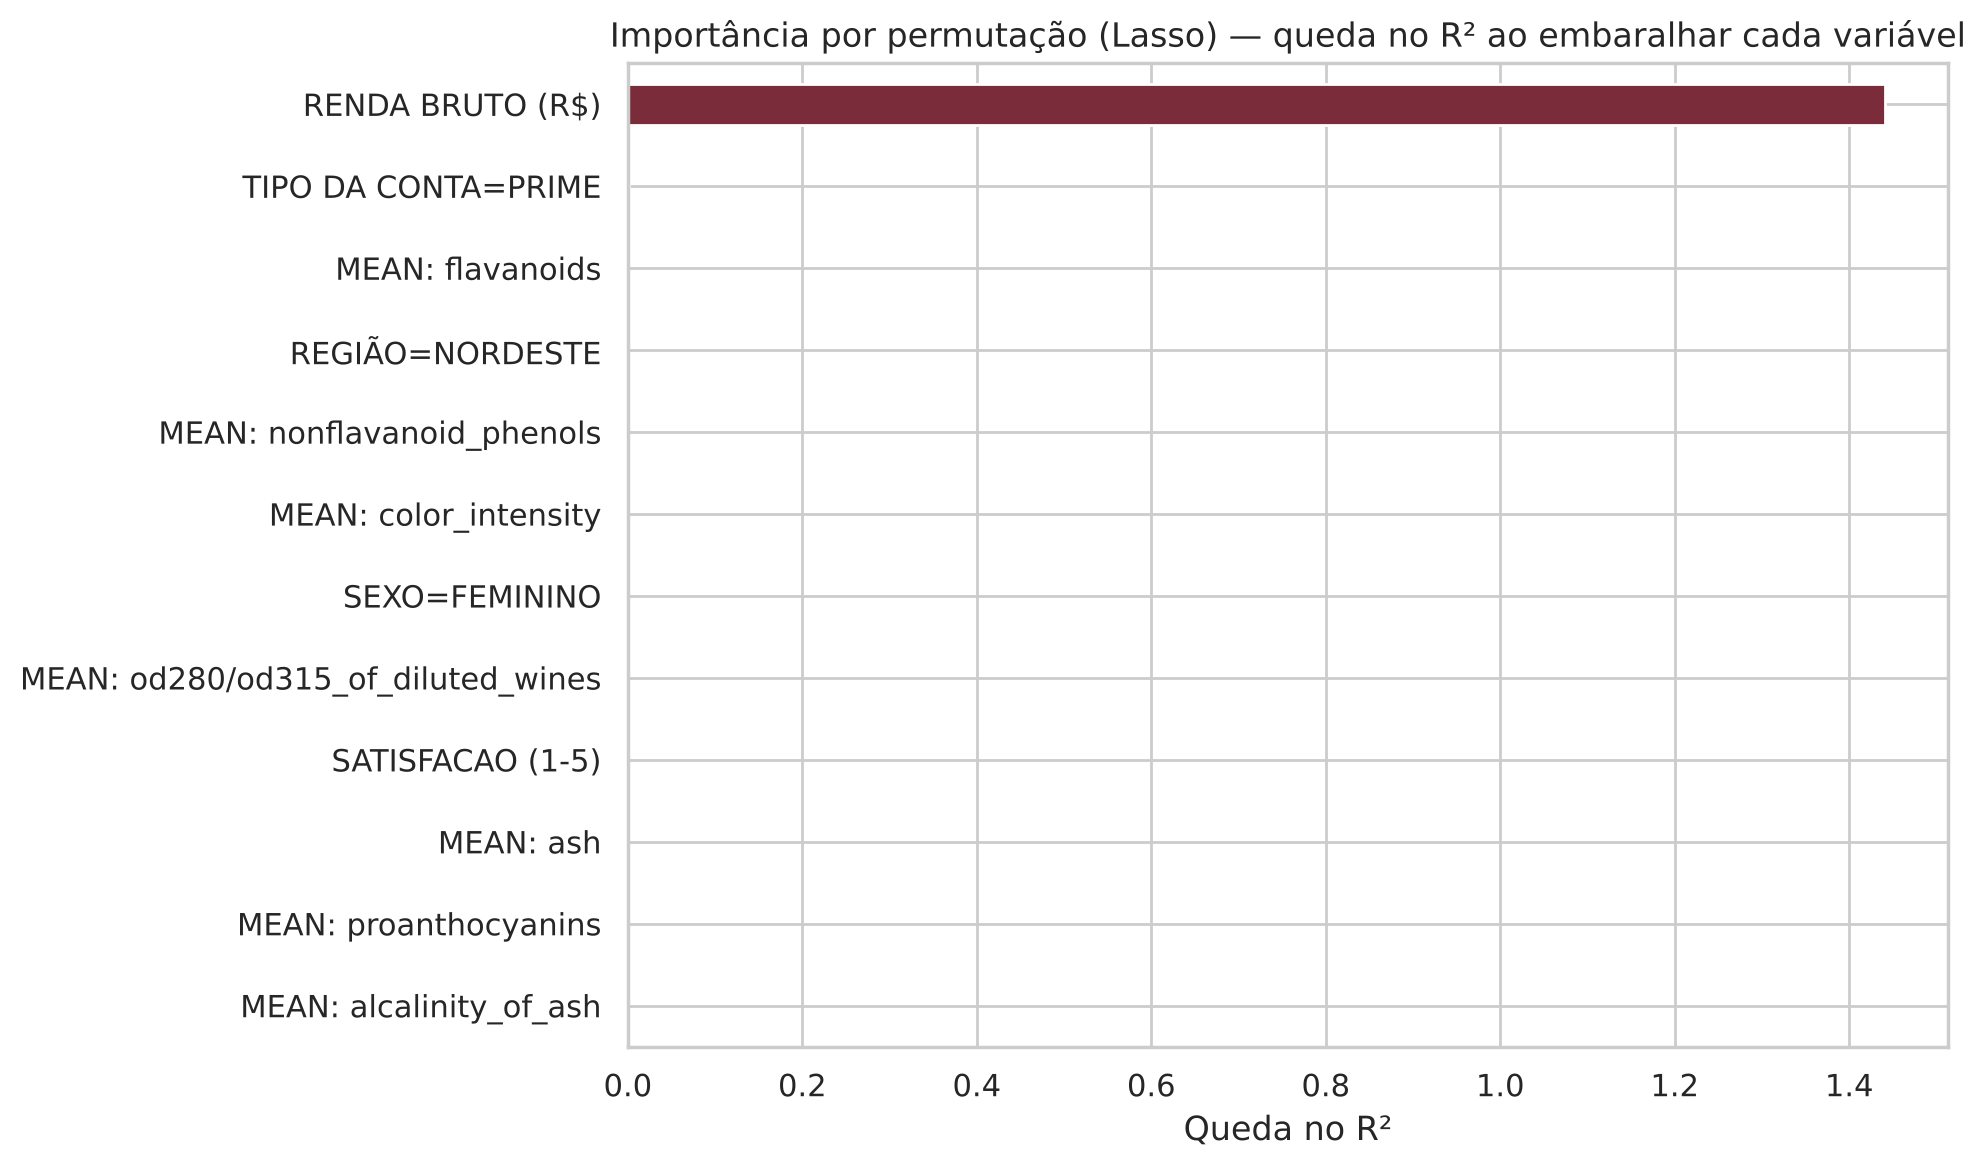

,Queda no R²
RENDA BRUTO (R$),1.4412
TIPO DA CONTA=PRIME,0.0011
MEAN: flavanoids,0.0001
REGIÃO=NORDESTE,0.0001
MEAN: nonflavanoid_phenols,0.0001
MEAN: color_intensity,0.0000
SEXO=FEMININO,0.0000
MEAN: od280/od315_of_diluted_wines,0.0000


In [9]:
# Quais variáveis o modelo realmente usa? (importância por permutação no VALIDATION)
imp = permutation_importance(reg, X_val, y_val, n_repeats=10, random_state=SEED, scoring="r2")
imp_reg = pd.Series(imp.importances_mean, index=FEATURES_REG).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(10, 6))
imp_reg.head(12)[::-1].plot.barh(ax=ax, color="#7b2c3a")
ax.set_title(f"Importância por permutação ({MELHOR_REG}) — queda no R² ao embaralhar cada variável")
ax.set_xlabel("Queda no R²"); plt.tight_layout(); plt.show()
imp_reg.head(8).to_frame("Queda no R²")

In [10]:
r2v = tab_reg["R² validation"]
display(Markdown(f"""
**Escolha do modelo:** o **{MELHOR_REG}** teve o maior R² no validation ({brl(r2v.iloc[0], 4)}).
A diferença para o segundo colocado ({tab_reg.index[1]}, {brl(r2v.iloc[1], 4)}) é pequena. Os modelos mais complexos (Random Forest, Gradient Boosting) não superam o linear.

Isso indica que a relação é essencialmente **linear**. A importância por permutação mostra que praticamente **toda a capacidade preditiva vem da RENDA BRUTO**: embaralhá-la derruba o R² em {brl(imp_reg.iloc[0], 3)}.
O tipo de conta, a satisfação, as variáveis demográficas e as 13 químicas têm importância próxima de zero. Isso é coerente com a Parte 1, onde as químicas e TOTAL tinham correlação ≈ 0.
"""))


**Escolha do modelo:** o **Lasso** teve o maior R² no validation (0,7520).
A diferença para o segundo colocado (Ridge, 0,7518) é pequena. Os modelos mais complexos (Random Forest, Gradient Boosting) não superam o linear.

Isso indica que a relação é essencialmente **linear**. A importância por permutação mostra que praticamente **toda a capacidade preditiva vem da RENDA BRUTO**: embaralhá-la derruba o R² em 1,441.
O tipo de conta, a satisfação, as variáveis demográficas e as 13 químicas têm importância próxima de zero. Isso é coerente com a Parte 1, onde as químicas e TOTAL tinham correlação ≈ 0.


### A1.3.1: Intervalo de confiança: Train

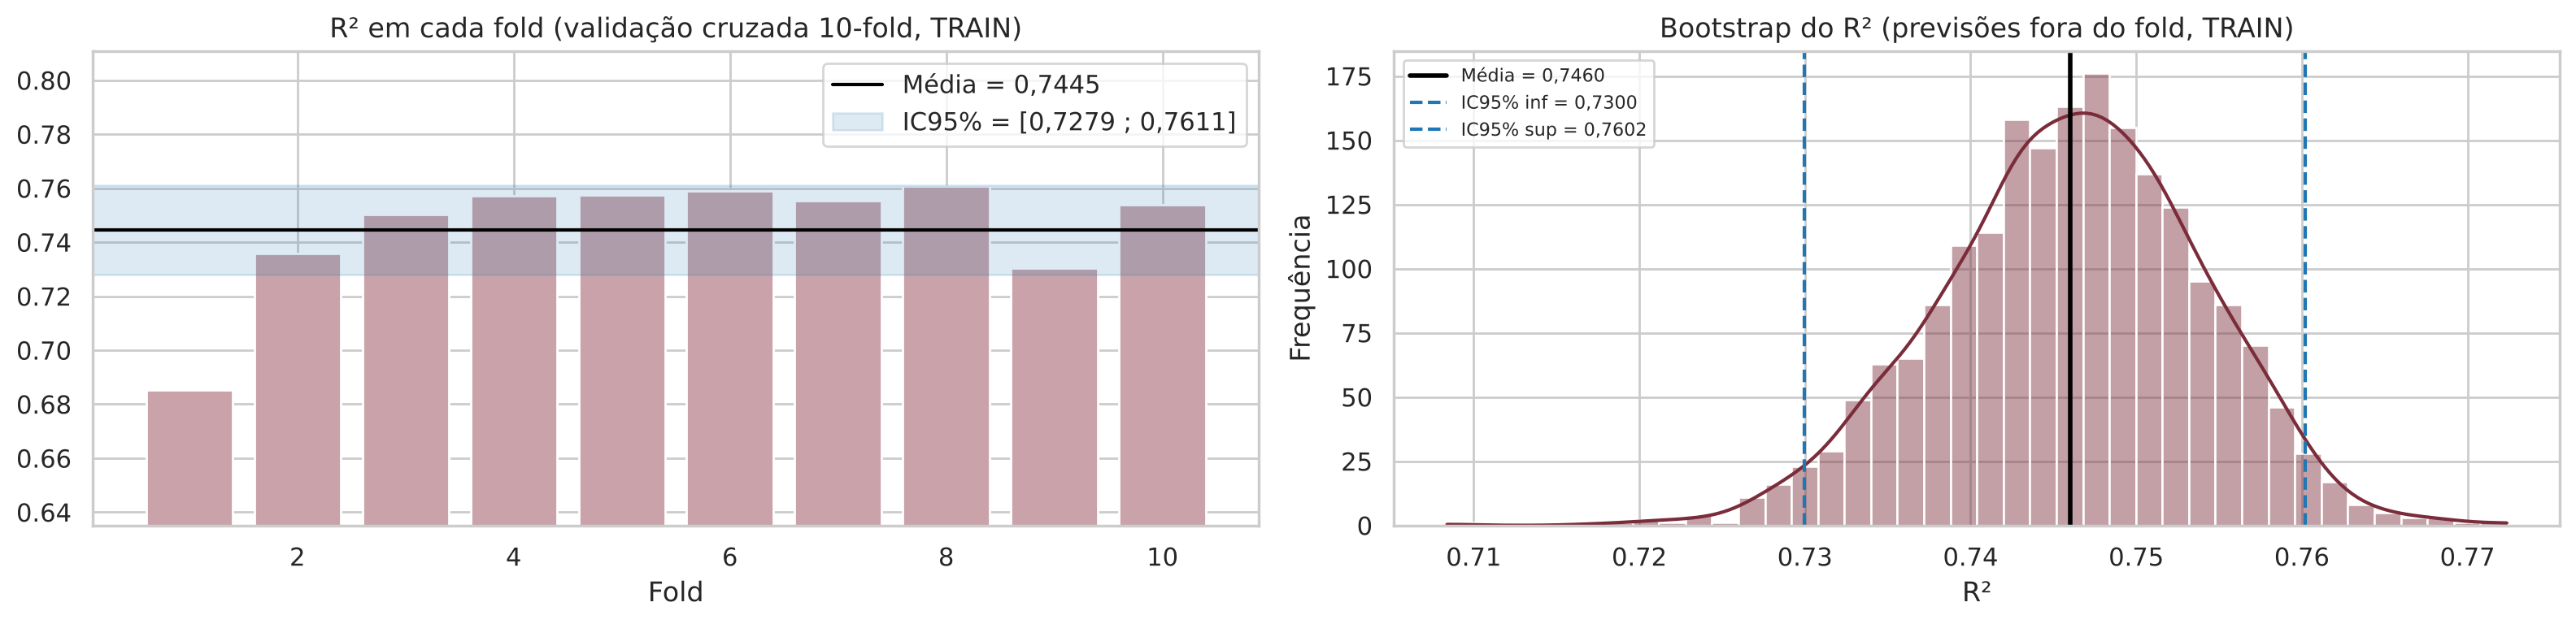

TRAIN | CV 10-fold: R² = 0,7445 (IC95% t: 0,7279 a 0,7611) | Bootstrap: R² = 0,7460 (IC95%: 0,7300 a 0,7602)


In [11]:
# Validação Cruzada e Análise Bootstrapping
cv10 = KFold(n_splits=10, shuffle=True, random_state=SEED)
cv_train = cross_val_score(make_pipeline(StandardScaler(), regressores[MELHOR_REG]), X_train, y_train, cv=cv10, scoring="r2")
m, lo, hi = ic_validacao_cruzada(cv_train)
oof = cross_val_predict(make_pipeline(StandardScaler(), regressores[MELHOR_REG]), X_train, y_train, cv=cv10)
boot_r2_train = bootstrap_metrica(y_train, oof, r2_score)

fig, axes = plt.subplots(1, 2, figsize=(16, 4))
axes[0].bar(range(1, 11), cv_train, color="#c9a3a9"); axes[0].axhline(m, color="black", label=f"Média = {brl(m, 4)}")
axes[0].axhspan(lo, hi, color="tab:blue", alpha=.15, label=f"IC95% = [{brl(lo, 4)} ; {brl(hi, 4)}]")
axes[0].set_ylim(min(cv_train) - .05, max(cv_train) + .05); axes[0].set_title("R² em cada fold (validação cruzada 10-fold, TRAIN)")
axes[0].set_xlabel("Fold"); axes[0].legend()
ic_reg_train = grafico_ic(boot_r2_train, "Bootstrap do R² (previsões fora do fold, TRAIN)", "R²", axes[1])
plt.tight_layout(); plt.show()
print(f"TRAIN | CV 10-fold: R² = {brl(m, 4)} (IC95% t: {brl(lo, 4)} a {brl(hi, 4)}) | "
      f"Bootstrap: R² = {brl(ic_reg_train['media'], 4)} (IC95%: {brl(ic_reg_train['ic_inf'], 4)} a {brl(ic_reg_train['ic_sup'], 4)})")

### A1.3.2: Intervalo de confiança: Validation

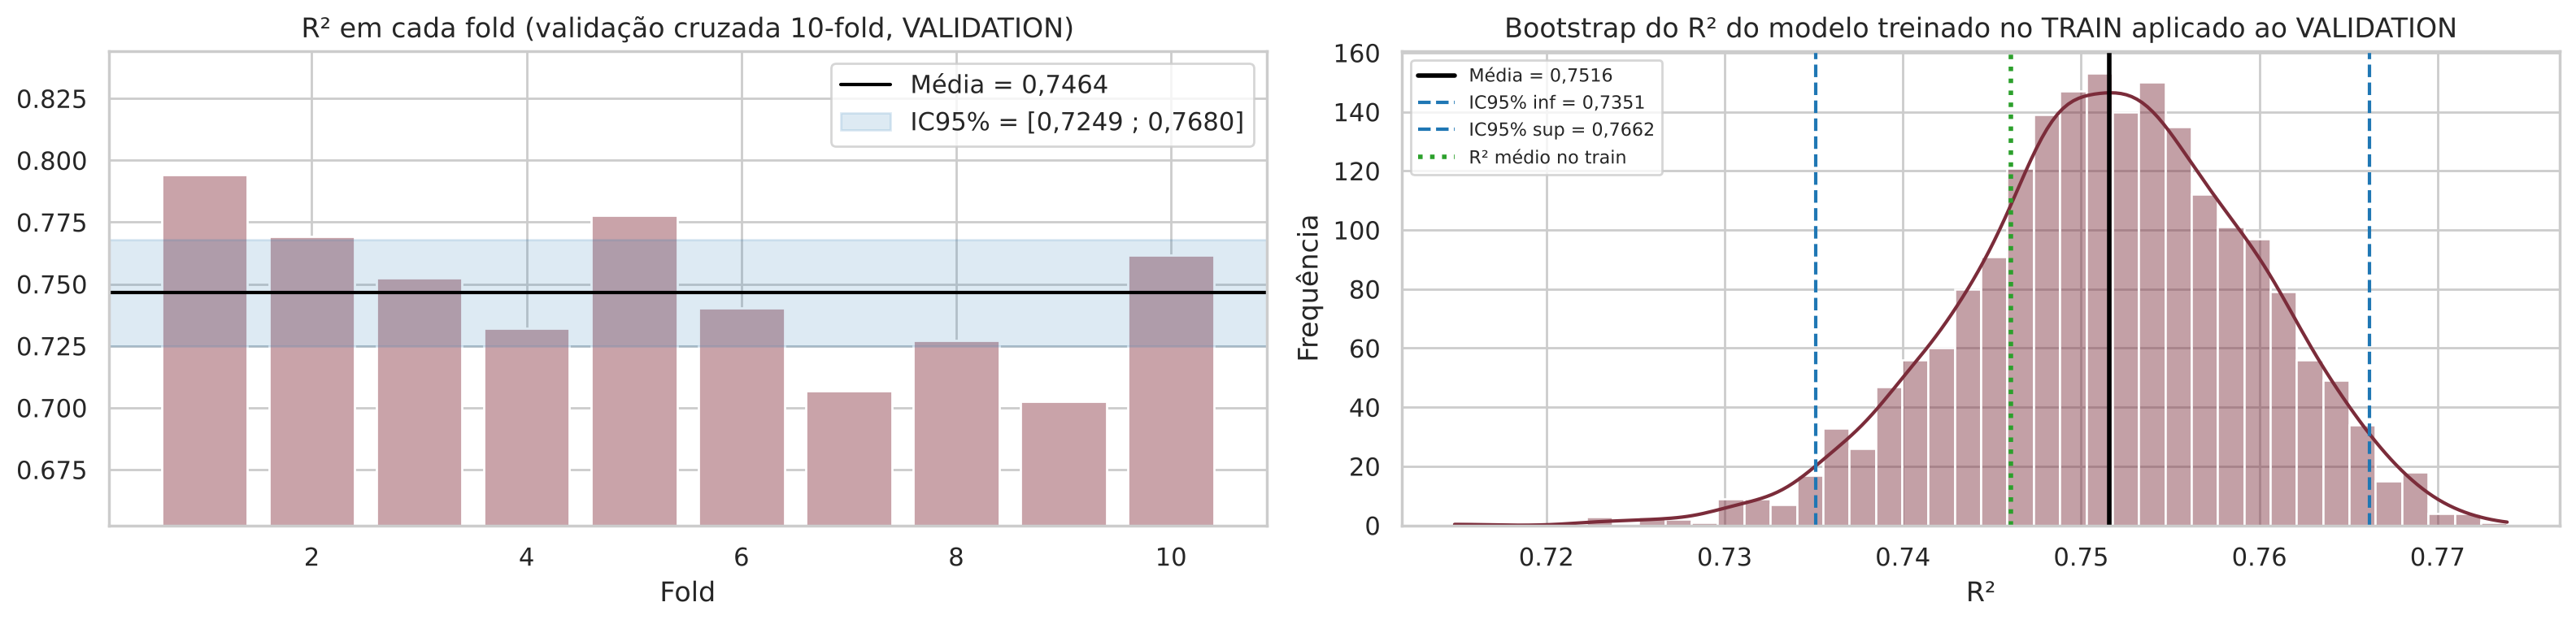

VALIDATION | CV 10-fold: R² = 0,7464 (IC95% t: 0,7249 a 0,7680) | Bootstrap: R² = 0,7516 (IC95%: 0,7351 a 0,7662)


In [12]:
# Validação Cruzada e Análise Bootstrapping
cv_val = cross_val_score(make_pipeline(StandardScaler(), regressores[MELHOR_REG]), X_val, y_val, cv=cv10, scoring="r2")
mv, lov, hiv = ic_validacao_cruzada(cv_val)
boot_r2_val = bootstrap_metrica(y_val, reg.predict(X_val), r2_score)

fig, axes = plt.subplots(1, 2, figsize=(16, 4))
axes[0].bar(range(1, 11), cv_val, color="#c9a3a9"); axes[0].axhline(mv, color="black", label=f"Média = {brl(mv, 4)}")
axes[0].axhspan(lov, hiv, color="tab:blue", alpha=.15, label=f"IC95% = [{brl(lov, 4)} ; {brl(hiv, 4)}]")
axes[0].set_ylim(min(cv_val) - .05, max(cv_val) + .05); axes[0].set_title("R² em cada fold (validação cruzada 10-fold, VALIDATION)")
axes[0].set_xlabel("Fold"); axes[0].legend()
ic_reg_val = grafico_ic(boot_r2_val, "Bootstrap do R² do modelo treinado no TRAIN aplicado ao VALIDATION", "R²", axes[1],
                        extra=[(ic_reg_train["media"], "R² médio no train")])
plt.tight_layout(); plt.show()
print(f"VALIDATION | CV 10-fold: R² = {brl(mv, 4)} (IC95% t: {brl(lov, 4)} a {brl(hiv, 4)}) | "
      f"Bootstrap: R² = {brl(ic_reg_val['media'], 4)} (IC95%: {brl(ic_reg_val['ic_inf'], 4)} a {brl(ic_reg_val['ic_sup'], 4)})")

##Atividade A1.4 (4º Passo): Medir a acurácia (score) dos Modelos de Regressão:

### A1.4.1: Exibir os Coeficientes de Determinação ($R^2$)

In [13]:
def metricas_reg(y, yhat):
    return {"R²": r2_score(y, yhat), "MAE (R$)": mean_absolute_error(y, yhat),
            "RMSE (R$)": np.sqrt(mean_squared_error(y, yhat)), "n": len(y)}

pred_reg = {k: reg.predict(Xr[k]) for k in Xr}
tab_r2 = pd.DataFrame({k: metricas_reg(yr[k], pred_reg[k]) for k in Xr}).T
tab_r2["n"] = tab_r2["n"].astype(int)
tab_r2

,R²,MAE (R$),RMSE (R$),n
train,0.7493,261.9396,410.6383,5300
validation,0.7520,260.5426,406.0583,5300
test,0.7539,262.2002,410.9238,5300
sample (população),0.7448,259.6130,403.7450,5300


In [14]:
# Train
print(f"R² TRAIN      = {brl(tab_r2.loc['train', 'R²'], 4)}")

R² TRAIN      = 0,7493


In [15]:
# Validation
print(f"R² VALIDATION = {brl(tab_r2.loc['validation', 'R²'], 4)}")

R² VALIDATION = 0,7520


In [16]:
# Teste
print(f"R² TEST       = {brl(tab_r2.loc['test', 'R²'], 4)}")
display(Markdown(f"""
* **Conjunto de Treinamento:** R² = **{brl(tab_r2.loc['train','R²'], 4)}**
* **Conjunto de Validação:** R² = **{brl(tab_r2.loc['validation','R²'], 4)}**
* **Conjunto de Teste:** R² = **{brl(tab_r2.loc['test','R²'], 4)}**

O R² é praticamente igual nos três conjuntos, então **não há overfitting**. O modelo explica cerca de {pct(tab_r2.loc['test','R²'], 0)} da variação do gasto, com erro médio absoluto de R$ {brl(tab_r2.loc['test','MAE (R$)'])}.
"""))

R² TEST       = 0,7539



* **Conjunto de Treinamento:** R² = **0,7493**
* **Conjunto de Validação:** R² = **0,7520**
* **Conjunto de Teste:** R² = **0,7539**

O R² é praticamente igual nos três conjuntos, então **não há overfitting**. O modelo explica cerca de 75% da variação do gasto, com erro médio absoluto de R$ 262,20.


### A1.4.2: Plotagem dos Conjuntos - REAL ($y$) x ESTIMADO ($\hat{y}$):

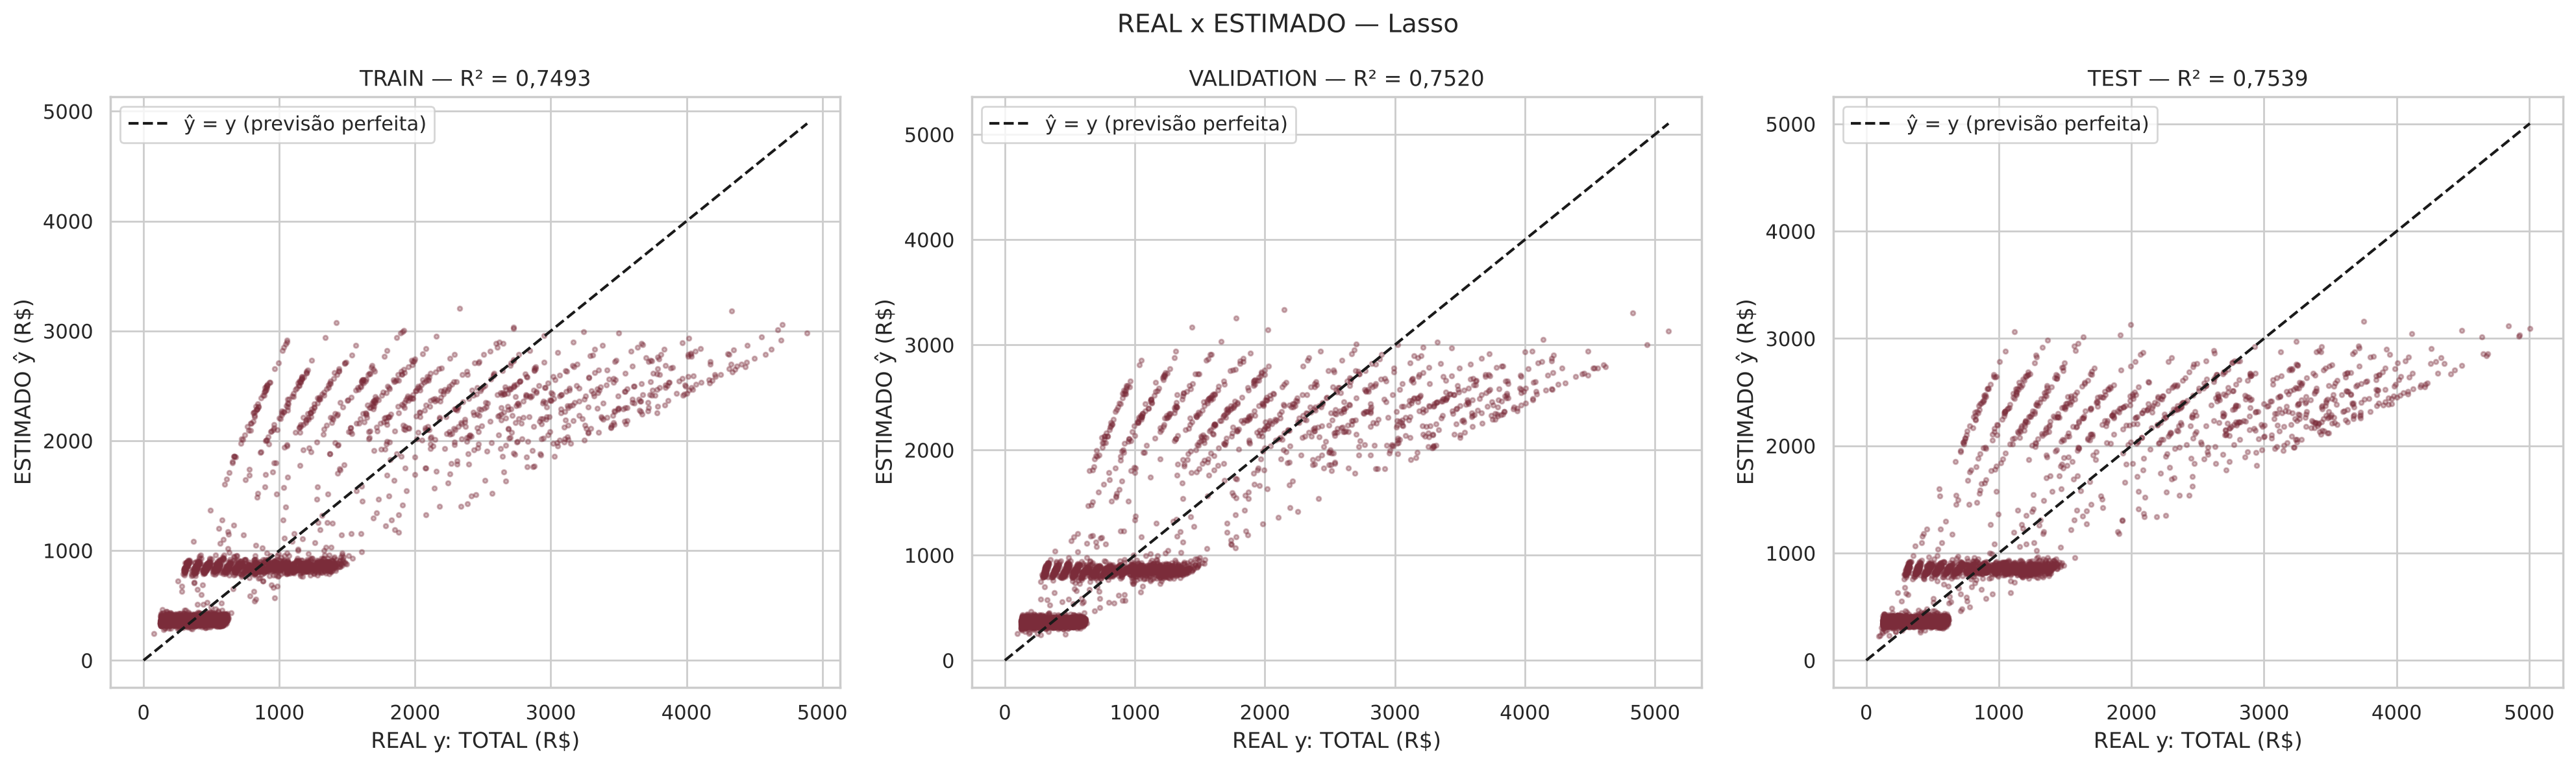

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, k in zip(axes, CONJUNTOS):
    ax.scatter(yr[k], pred_reg[k], s=6, alpha=.35, color="#7b2c3a")
    lim = [0, max(yr[k].max(), pred_reg[k].max())]
    ax.plot(lim, lim, "k--", lw=1.5, label="ŷ = y (previsão perfeita)")
    ax.set_title(f"{k.upper()} — R² = {brl(tab_r2.loc[k, 'R²'], 4)}")
    ax.set_xlabel("REAL y: TOTAL (R$)"); ax.set_ylabel("ESTIMADO ŷ (R$)"); ax.legend()
plt.suptitle(f"REAL x ESTIMADO — {MELHOR_REG}", fontsize=14); plt.tight_layout(); plt.show()

### A1.4.3: Análise dos Resíduos: $\epsilon = y_{real} - y_{estimado}$

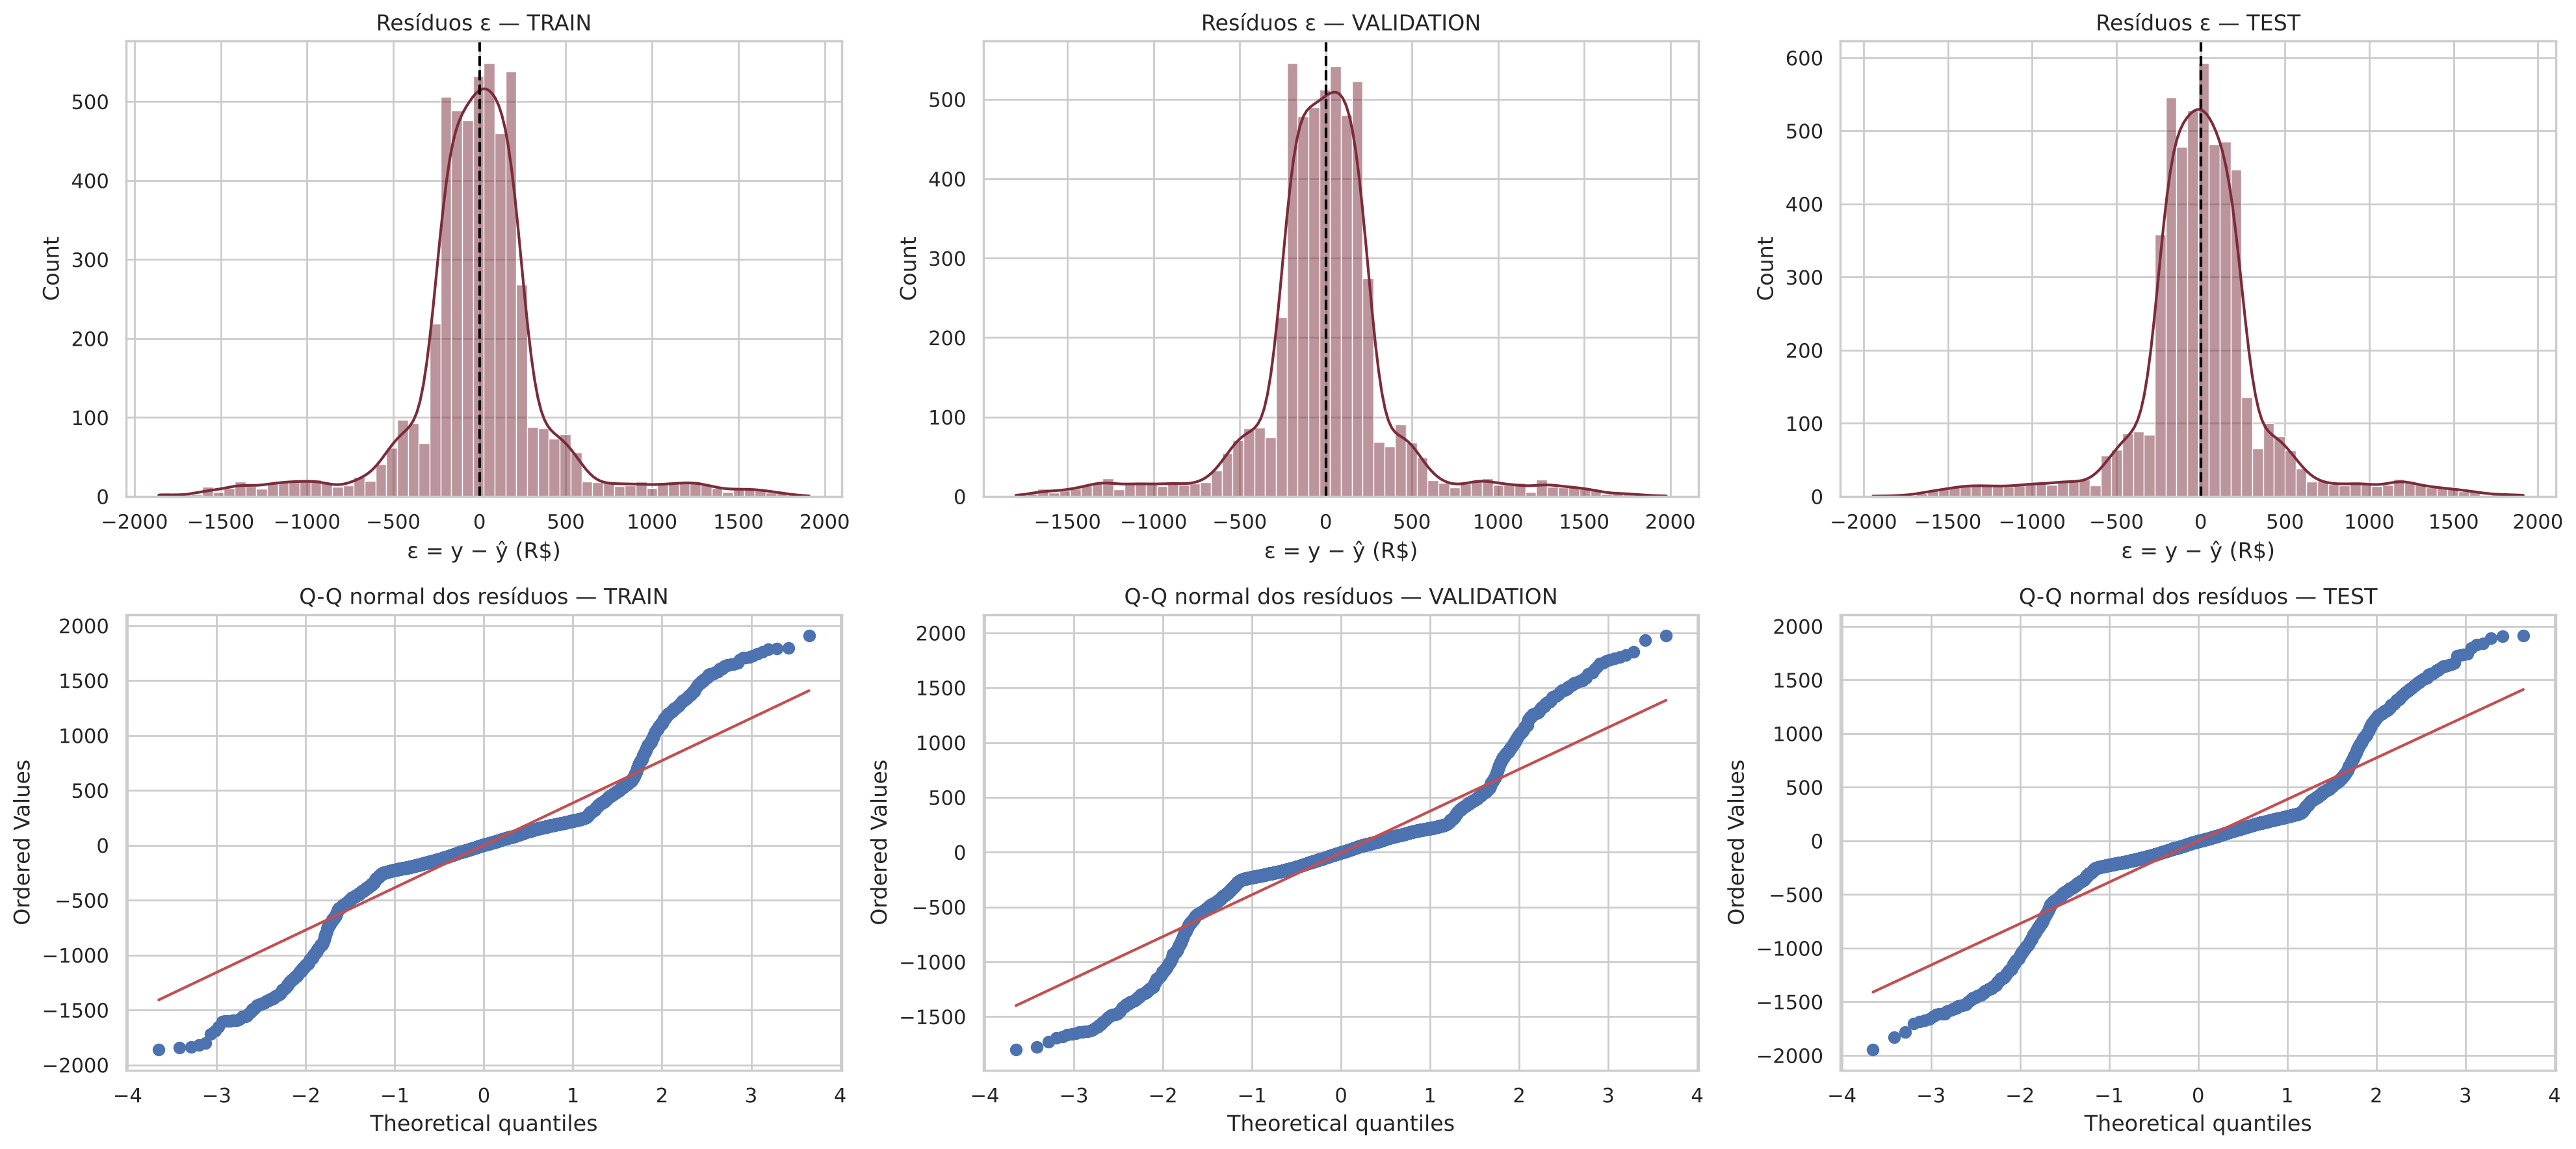

,Média ε,Desvio ε,Assimetria,Curtose,AD (normalidade)
Conjunto,,,,,
train,-0.0000,410.6383,0.0627,4.6932,191.9364
validation,-6.8799,406.0000,0.0570,4.7260,186.5882
test,0.5644,410.9234,0.1233,4.6347,191.2815


In [18]:
res = {k: yr[k] - pred_reg[k] for k in Xr}
fig, axes = plt.subplots(2, 3, figsize=(20, 9))
linhas = []
for j, k in enumerate(CONJUNTOS):
    sns.histplot(res[k], bins=60, kde=True, ax=axes[0, j], color="#7b2c3a")
    axes[0, j].axvline(0, color="black", ls="--"); axes[0, j].set_title(f"Resíduos ε — {k.upper()}")
    axes[0, j].set_xlabel("ε = y − ŷ (R$)")
    stats.probplot(res[k], dist="norm", plot=axes[1, j]); axes[1, j].set_title(f"Q-Q normal dos resíduos — {k.upper()}")
    linhas.append({"Conjunto": k, "Média ε": res[k].mean(), "Desvio ε": res[k].std(),
                   "Assimetria": stats.skew(res[k]), "Curtose": stats.kurtosis(res[k]),
                   "AD (normalidade)": stats.anderson(res[k], dist="norm").statistic})
plt.tight_layout(); plt.show()
tab_res = pd.DataFrame(linhas).set_index("Conjunto")
tab_res

In [19]:
display(Markdown(f"""
* **Média dos resíduos ≈ 0** em todos os conjuntos (train {brl(tab_res.loc['train','Média ε'])}, validation {brl(tab_res.loc['validation','Média ε'])}, test {brl(tab_res.loc['test','Média ε'])}). O modelo **não tem viés sistemático**.
* O desvio dos resíduos é de cerca de R$ {brl(tab_res['Desvio ε'].mean())}, parecido nos três conjuntos.
* Os resíduos **não são normais** (AD muito acima do valor crítico 0,752). O histograma tem caudas pesadas, e o Q-Q plot se afasta da reta nos extremos.
  Essas caudas vêm dos clientes de renda alta (PRIME), em que o gasto varia mais em reais (ver o JOINT abaixo).
"""))


* **Média dos resíduos ≈ 0** em todos os conjuntos (train -0,00, validation -6,88, test 0,56). O modelo **não tem viés sistemático**.
* O desvio dos resíduos é de cerca de R$ 409,19, parecido nos três conjuntos.
* Os resíduos **não são normais** (AD muito acima do valor crítico 0,752). O histograma tem caudas pesadas, e o Q-Q plot se afasta da reta nos extremos.
  Essas caudas vêm dos clientes de renda alta (PRIME), em que o gasto varia mais em reais (ver o JOINT abaixo).


### A1.4.4: JOINT: Resíduos ($\epsilon$) vs Valores Estimado ($\hat{y}$)

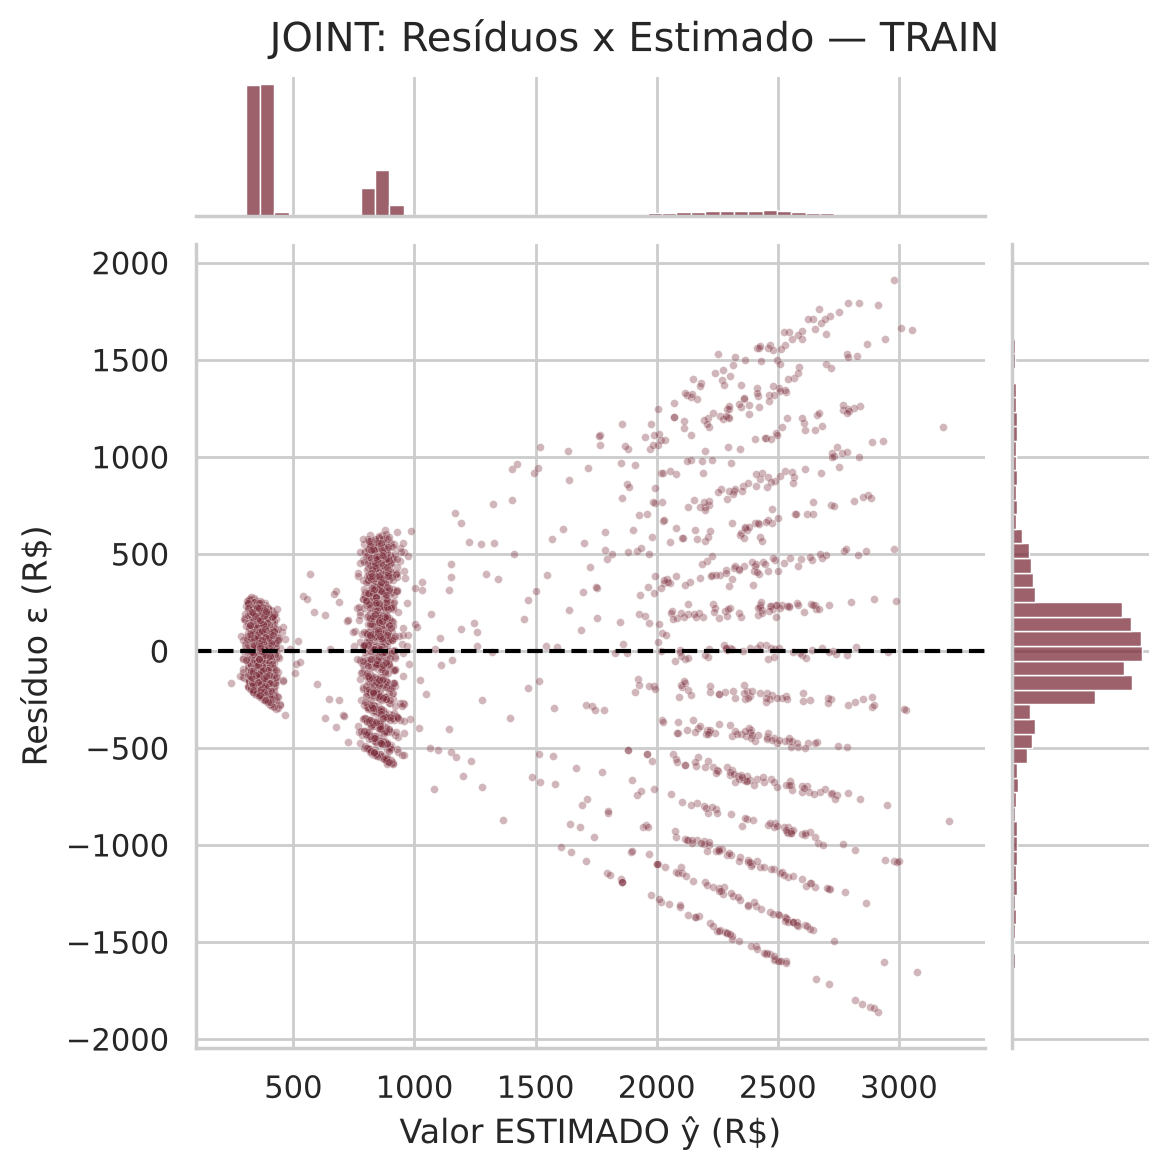

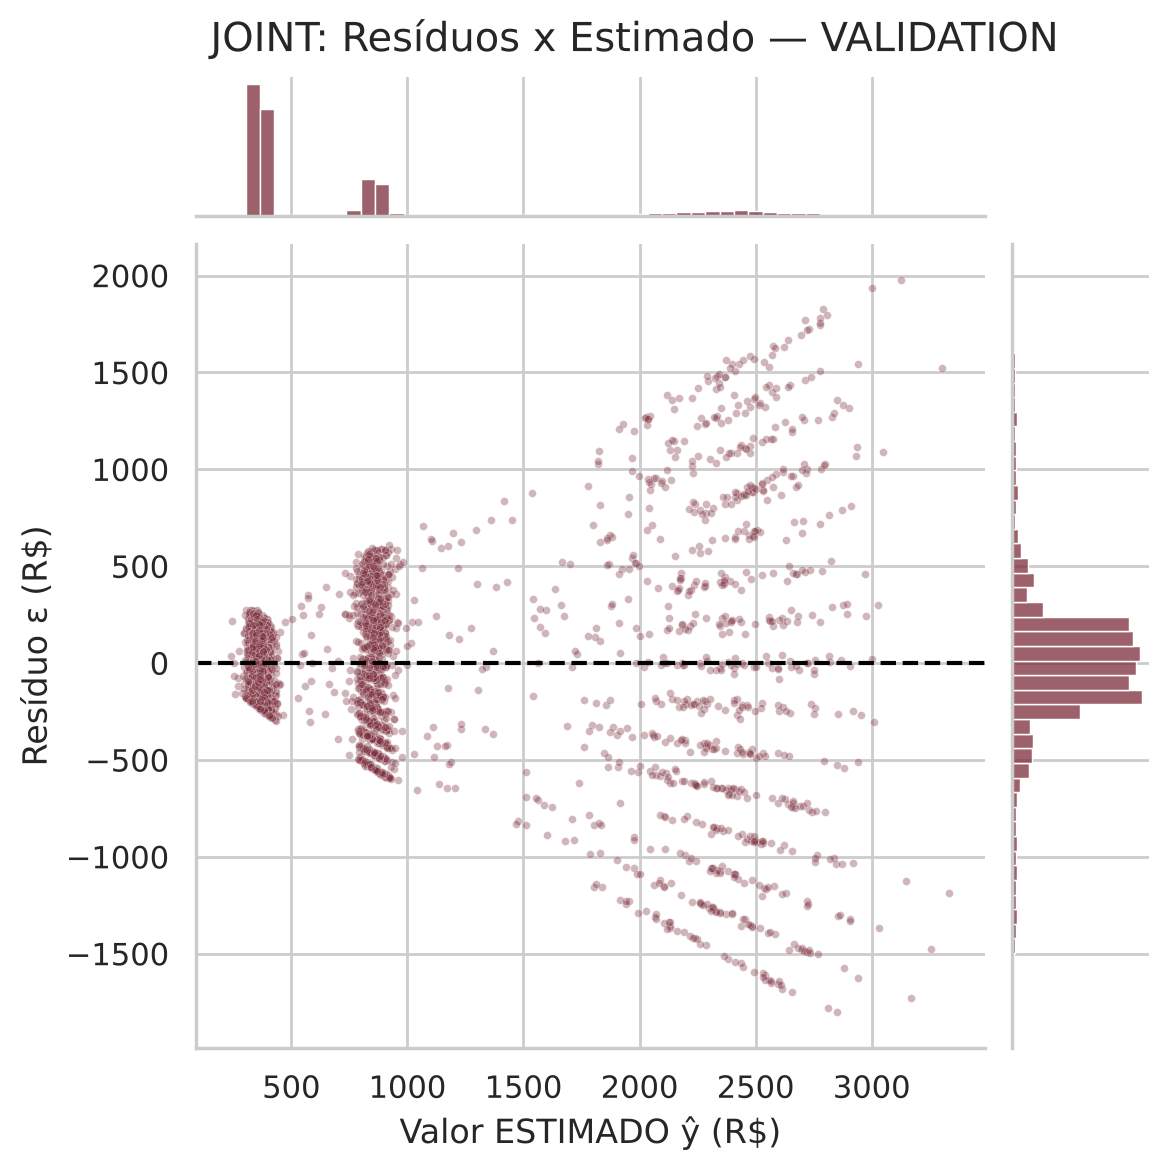

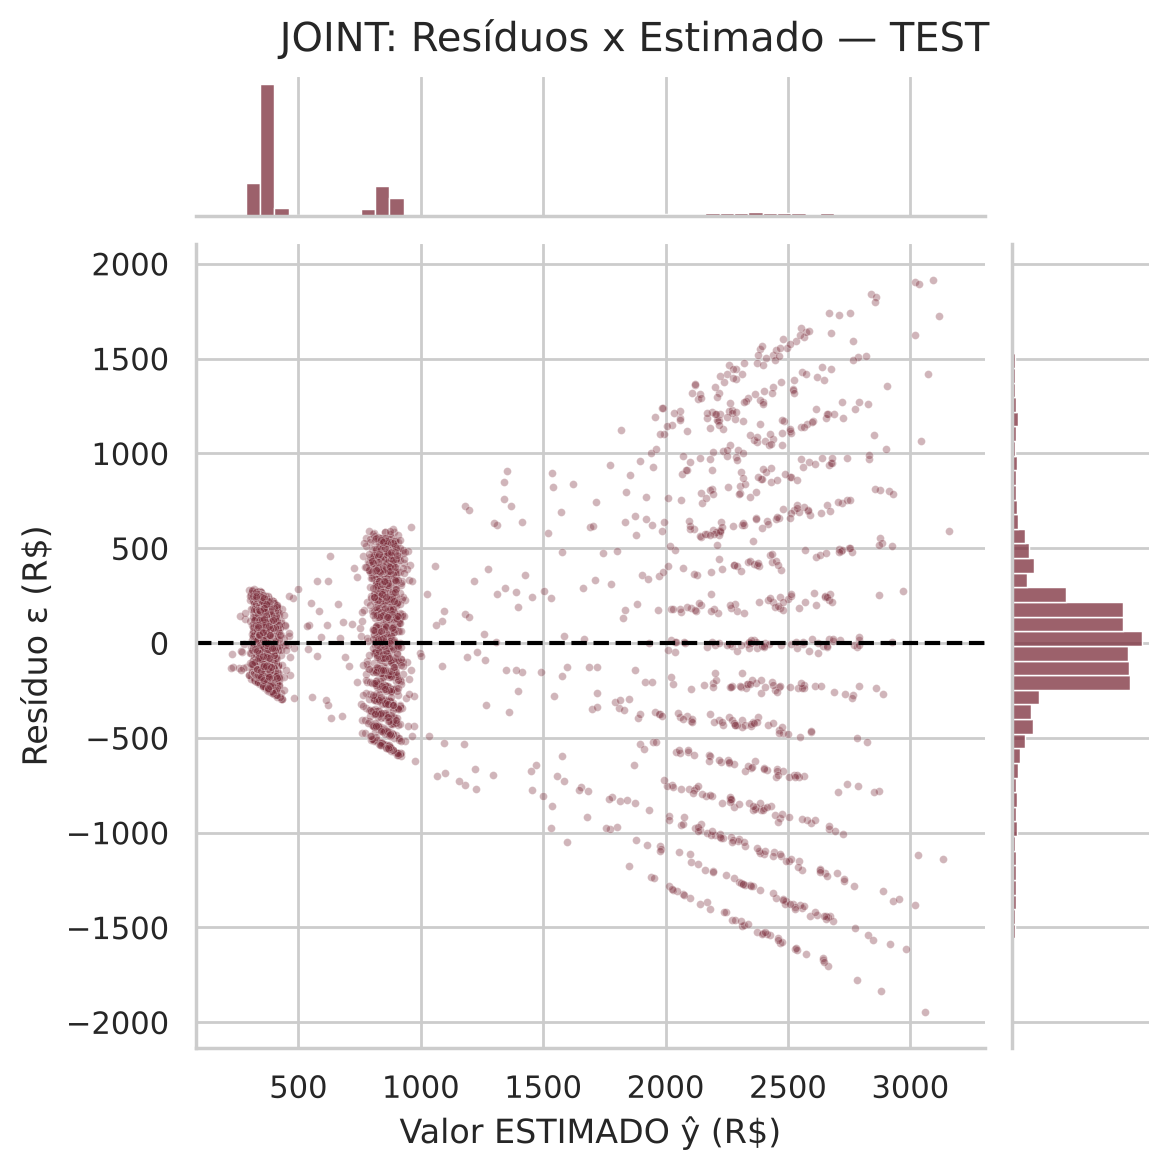

Correlação de Spearman entre ŷ e |ε|: {'train': '0,534', 'validation': '0,527', 'test': '0,519'}


In [20]:
for k in CONJUNTOS:
    g = sns.jointplot(x=pred_reg[k], y=res[k], kind="scatter", s=8, alpha=.35, color="#7b2c3a", height=5.5,
                      marginal_kws=dict(bins=50))
    g.ax_joint.axhline(0, color="black", ls="--")
    g.set_axis_labels("Valor ESTIMADO ŷ (R$)", "Resíduo ε (R$)")
    g.figure.suptitle(f"JOINT: Resíduos x Estimado — {k.upper()}", y=1.02)
    plt.show()

# Heterocedasticidade: correlação entre |ε| e ŷ
hetero = {k: stats.spearmanr(pred_reg[k], np.abs(res[k]))[0] for k in CONJUNTOS}
print("Correlação de Spearman entre ŷ e |ε|:", {k: brl(v, 3) for k, v in hetero.items()})

In [21]:
display(Markdown(f"""
* Os resíduos ficam **centrados em zero** em toda a faixa de ŷ, sem curvatura. A forma linear do modelo é adequada.
* A dispersão **aumenta com o valor estimado** (formato de funil). A correlação entre ŷ e |ε| é de cerca de {brl(np.mean(list(hetero.values())), 2)}.
  Isso é **heterocedasticidade**: o gasto varia proporcionalmente à renda, então clientes de renda alta têm erros maiores em reais.
* **Implicação prática:** as previsões são mais precisas para ESSENTIAL e VIP. Para o PRIME, a previsão pontual deve vir acompanhada de uma margem maior.
"""))


* Os resíduos ficam **centrados em zero** em toda a faixa de ŷ, sem curvatura. A forma linear do modelo é adequada.
* A dispersão **aumenta com o valor estimado** (formato de funil). A correlação entre ŷ e |ε| é de cerca de 0,53.
  Isso é **heterocedasticidade**: o gasto varia proporcionalmente à renda, então clientes de renda alta têm erros maiores em reais.
* **Implicação prática:** as previsões são mais precisas para ESSENTIAL e VIP. Para o PRIME, a previsão pontual deve vir acompanhada de uma margem maior.


##Atividade A1.5 (5º Passo): Testar o Modelo: Dados da População: amostra aleatória (Sample).

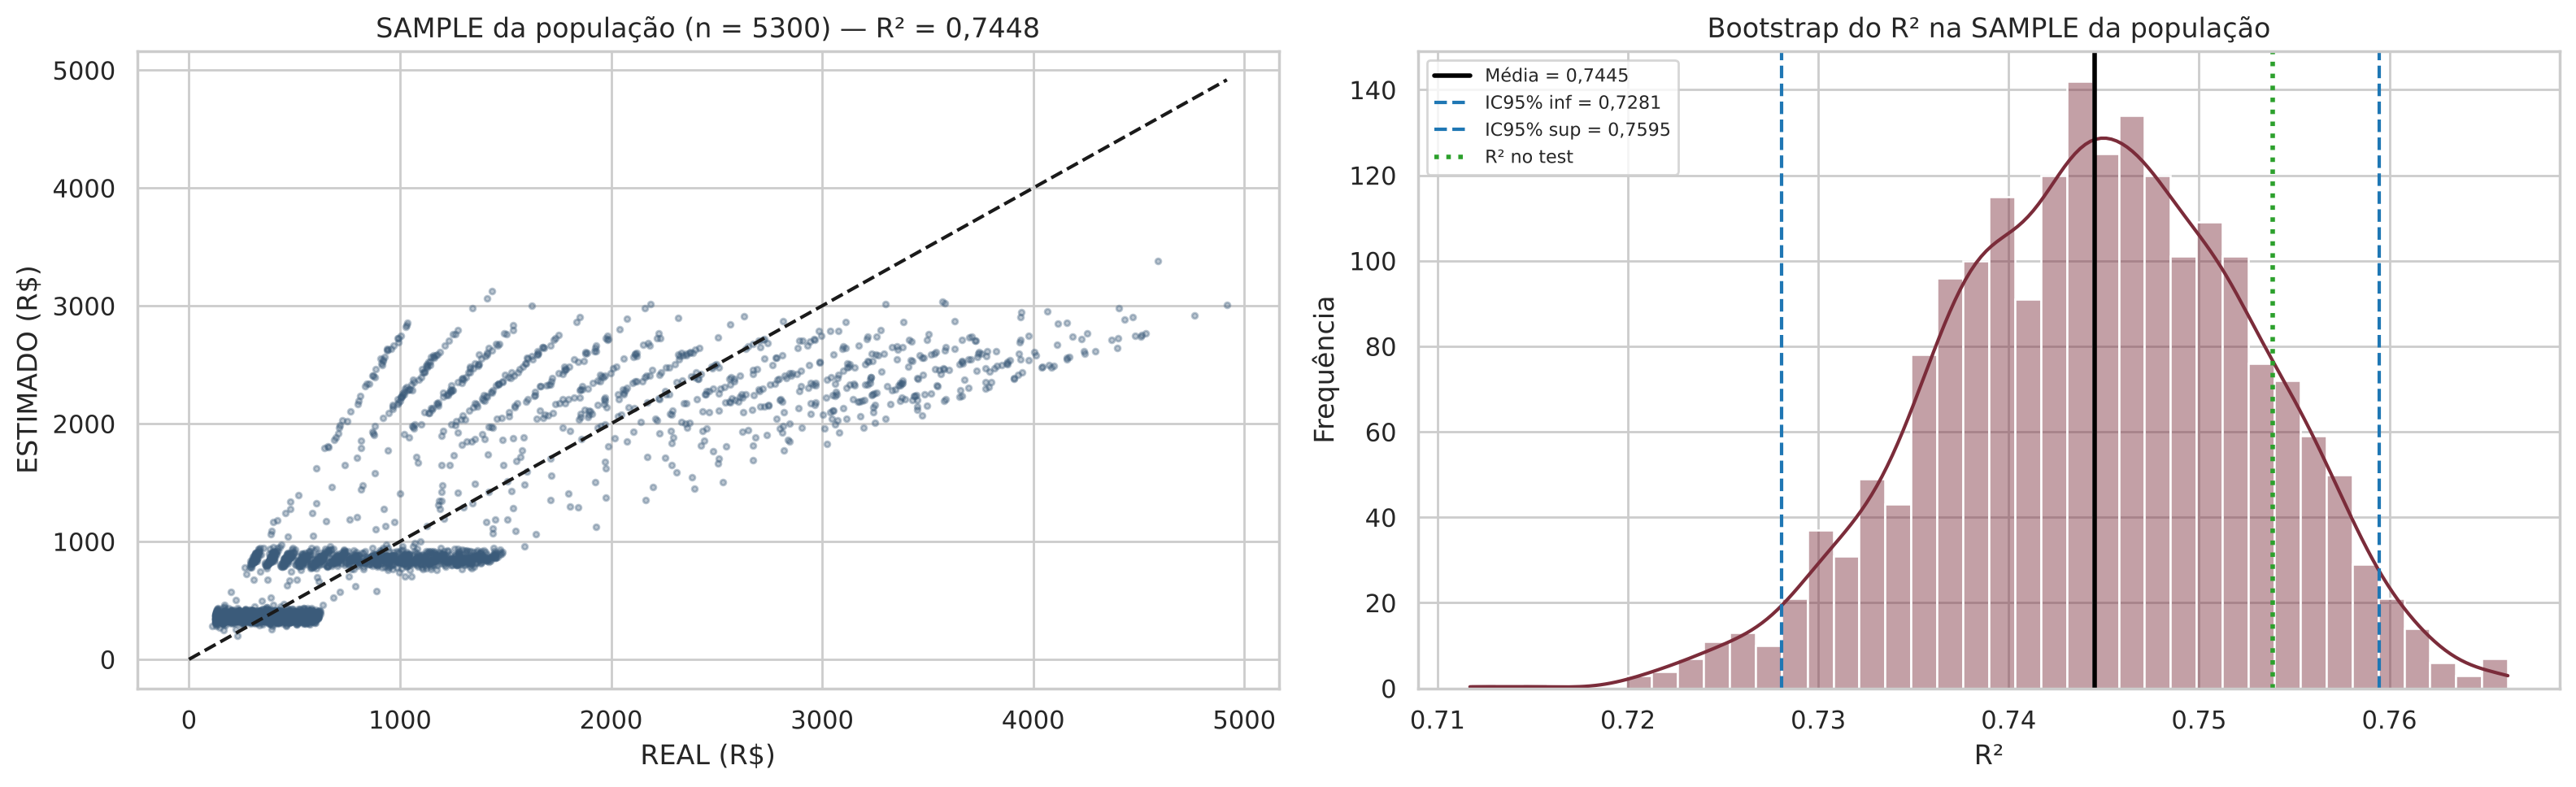

,Gasto real,Gasto previsto
Soma (R$),"3,940,965.0000","4,001,629.3578"
Média por nota (R$),743.5783,755.0244


In [22]:
y_s, p_s = yr["sample (população)"], pred_reg["sample (população)"]
m_s = metricas_reg(y_s, p_s)
boot_r2_s = bootstrap_metrica(y_s, p_s, r2_score)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].scatter(y_s, p_s, s=6, alpha=.35, color="#3b5b7a")
lim = [0, max(y_s.max(), p_s.max())]; axes[0].plot(lim, lim, "k--")
axes[0].set_title(f"SAMPLE da população (n = {len(y_s)}) — R² = {brl(m_s['R²'], 4)}")
axes[0].set_xlabel("REAL (R$)"); axes[0].set_ylabel("ESTIMADO (R$)")
ic_reg_s = grafico_ic(boot_r2_s, "Bootstrap do R² na SAMPLE da população", "R²", axes[1],
                      extra=[(tab_r2.loc["test", "R²"], "R² no test")])
plt.tight_layout(); plt.show()
pd.DataFrame({"Gasto real": [y_s.sum(), y_s.mean()], "Gasto previsto": [p_s.sum(), p_s.mean()]},
             index=["Soma (R$)", "Média por nota (R$)"])

## RELATÓRIO PARCIAL - MODELO DE REGRESSÃO

In [23]:
display(Markdown(f"""
**RELATÓRIO PARCIAL — MODELO DE REGRESSÃO** (para os gestores da UVVine)

*   ✅ **Modelo escolhido:** {MELHOR_REG}, entre 7 regressores comparados por validação cruzada no train e R² no validation. Modelos mais complexos não trouxeram ganho.
*   ✅ **Acurácia (R²):** train {brl(tab_r2.loc['train','R²'], 4)} · validation {brl(tab_r2.loc['validation','R²'], 4)} · test {brl(tab_r2.loc['test','R²'], 4)} · sample da população {brl(m_s['R²'], 4)}.
    IC95% bootstrap no validation: [{brl(ic_reg_val['ic_inf'], 4)} ; {brl(ic_reg_val['ic_sup'], 4)}]. O desempenho é **estável e sem overfitting**.
*   ✅ **Erro típico:** MAE de R$ {brl(tab_r2.loc['test','MAE (R$)'])} por nota no test. Na sample, o gasto total previsto (R$ {brl(p_s.sum())}) difere do real (R$ {brl(y_s.sum())}) em {pct(abs(p_s.sum() / y_s.sum() - 1))}.
    Ou seja, o modelo é **ótimo para projetar receita agregada**, e menos preciso para uma nota individual.
*   ✅ **O que explica o gasto:** praticamente só a **RENDA BRUTO**. Tipo de conta, satisfação, perfil demográfico e características químicas do vinho não acrescentam poder preditivo.
*   ✅ **Limitação:** resíduos heterocedásticos (erro cresce com o valor) e não normais. Os intervalos de previsão para clientes PRIME devem ser mais largos.
"""))


**RELATÓRIO PARCIAL — MODELO DE REGRESSÃO** (para os gestores da UVVine)

*   ✅ **Modelo escolhido:** Lasso, entre 7 regressores comparados por validação cruzada no train e R² no validation. Modelos mais complexos não trouxeram ganho.
*   ✅ **Acurácia (R²):** train 0,7493 · validation 0,7520 · test 0,7539 · sample da população 0,7448.
    IC95% bootstrap no validation: [0,7351 ; 0,7662]. O desempenho é **estável e sem overfitting**.
*   ✅ **Erro típico:** MAE de R$ 262,20 por nota no test. Na sample, o gasto total previsto (R$ 4.001.629,36) difere do real (R$ 3.940.965,00) em 1,54%.
    Ou seja, o modelo é **ótimo para projetar receita agregada**, e menos preciso para uma nota individual.
*   ✅ **O que explica o gasto:** praticamente só a **RENDA BRUTO**. Tipo de conta, satisfação, perfil demográfico e características químicas do vinho não acrescentam poder preditivo.
*   ✅ **Limitação:** resíduos heterocedásticos (erro cresce com o valor) e não normais. Os intervalos de previsão para clientes PRIME devem ser mais largos.


#Atividade A2: Modelo de Clusterização

**Pergunta de negócio:** *existem grupos naturais de clientes?*

Usamos **K-Means**, um método não supervisionado, sobre as variáveis financeiras, **RENDA BRUTO** e **TOTAL (R$)**. As duas são assimétricas à direita (Parte 1), por isso entram em **escala logarítmica** e são padronizadas.

As 13 variáveis químicas foram testadas e descartadas: não têm estrutura de grupos (ver a silhueta abaixo).

##Atividade A2.1 (1º Passo): Normalizar - Mapear - Discretizar

In [24]:
FEAT_CLU = ["RENDA BRUTO (R$)", "TOTAL (R$)"]

def preparar_cluster(p):
    """Mapear/transformar: log das variáveis financeiras (reduz assimetria e outliers)."""
    return np.log(p[FEAT_CLU].to_numpy(dtype=float))

# Justificativa da exclusão das químicas: silhueta do K-Means com k = 2..5 sobre as 13 químicas padronizadas
Zq = StandardScaler().fit_transform(prep["train"][QUIMICAS])
sil_quim = {k: silhouette_score(Zq, KMeans(k, n_init=10, random_state=SEED).fit_predict(Zq)) for k in range(2, 6)}
print("Silhueta usando apenas as químicas:", {k: brl(v, 3) for k, v in sil_quim.items()},
      "-> ≈ 0: não há grupos naturais nas químicas")

Silhueta usando apenas as químicas: {2: '0,054', 3: '0,048', 4: '0,047', 5: '0,047'} -> ≈ 0: não há grupos naturais nas químicas


##Atividade A2.2 (2º Passo) - ETL: Separar Entrada ($X$) da Saída ($y$)

In [25]:
# a partir daqui temos apenas: NDARRAY
# NDARRAY: train - validation - test
Xc = {k: preparar_cluster(prep[k]) for k in prep}
yc = {k: prep[k]["CONTA_COD"].to_numpy() for k in prep}   # y = TIPO DA CONTA: NÃO entra no treino, só na avaliação externa

X_trein_clu = np.vstack([Xc["train"], Xc["validation"]])  # treino do K-Means = train + validation
escala_clu = StandardScaler().fit(X_trein_clu)
Zc = {k: escala_clu.transform(v) for k, v in Xc.items()}
Z_trein = escala_clu.transform(X_trein_clu)
for k in Zc:
    print(f"{k:<20} X: {Zc[k].shape}  y (só avaliação): {yc[k].shape}")

train                X: (5300, 2)  y (só avaliação): (5300,)
validation           X: (5300, 2)  y (só avaliação): (5300,)
test                 X: (5300, 2)  y (só avaliação): (5300,)
sample (população)   X: (5300, 2)  y (só avaliação): (5300,)


##Atividade A2.3 (3º Passo): Aplicar o Método do Cotovelo

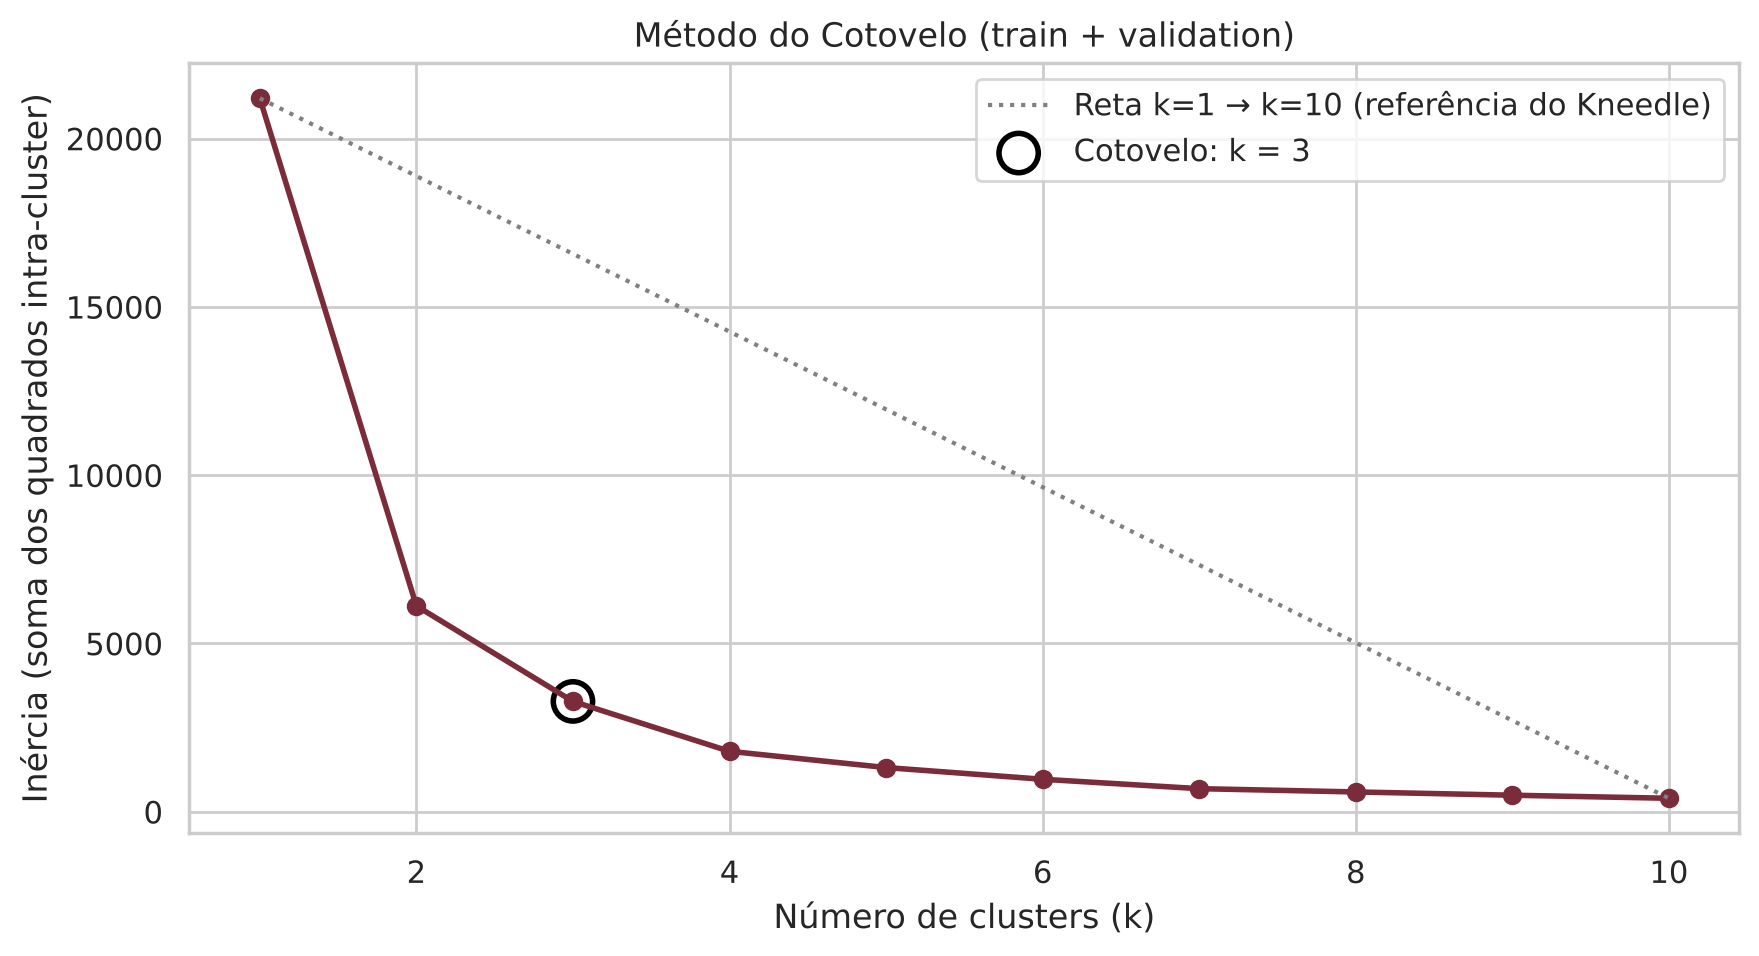

,Inércia,Redução p/ k+1 (%),Distância à reta (Kneedle)
k,,,
1,"21,200.0000",71.1448,0.0000
2,"6,117.3001",46.4003,"12,771.6199"
3,"3,278.8548",45.2276,"13,298.9850"
4,"1,795.9078",26.8845,"12,470.8520"
5,"1,313.0865",26.4880,"10,642.5932"
6,965.2765,28.9342,"8,679.3232"
7,685.9818,14.2160,"6,647.5378"
8,588.4624,16.4829,"4,433.9771"
9,491.4669,18.5542,"2,219.8925"


In [26]:
ks = range(1, 11)
inercia = [KMeans(k, n_init=10, random_state=SEED).fit(Z_trein).inertia_ for k in ks]
ganho = -np.diff(inercia)                               # redução da inércia ao passar de k para k+1
# Cotovelo (critério Kneedle): ponto da curva mais distante da reta que liga k=1 a k=10
ks_arr, in_arr = np.array(ks), np.array(inercia)
reta = in_arr[0] + (in_arr[-1] - in_arr[0]) * (ks_arr - ks_arr[0]) / (ks_arr[-1] - ks_arr[0])
distancia = reta - in_arr
K_COTOVELO = int(ks_arr[np.argmax(distancia)])

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(ks, inercia, "o-", color="#7b2c3a", lw=2)
ax.plot(ks, reta, ":", color="gray", label="Reta k=1 → k=10 (referência do Kneedle)")
ax.scatter([K_COTOVELO], [inercia[K_COTOVELO - 1]], s=200, facecolors="none", edgecolors="black", lw=2,
           label=f"Cotovelo: k = {K_COTOVELO}")
ax.set_title("Método do Cotovelo (train + validation)"); ax.set_xlabel("Número de clusters (k)")
ax.set_ylabel("Inércia (soma dos quadrados intra-cluster)"); ax.legend(); plt.show()
pd.DataFrame({"Inércia": inercia, "Redução p/ k+1 (%)": list(100 * ganho / np.array(inercia[:-1])) + [np.nan],
              "Distância à reta (Kneedle)": distancia}, index=pd.Index(ks, name="k"))

##Atividade A2.4 (4º Passo): Aplicar o Método da Silhueta

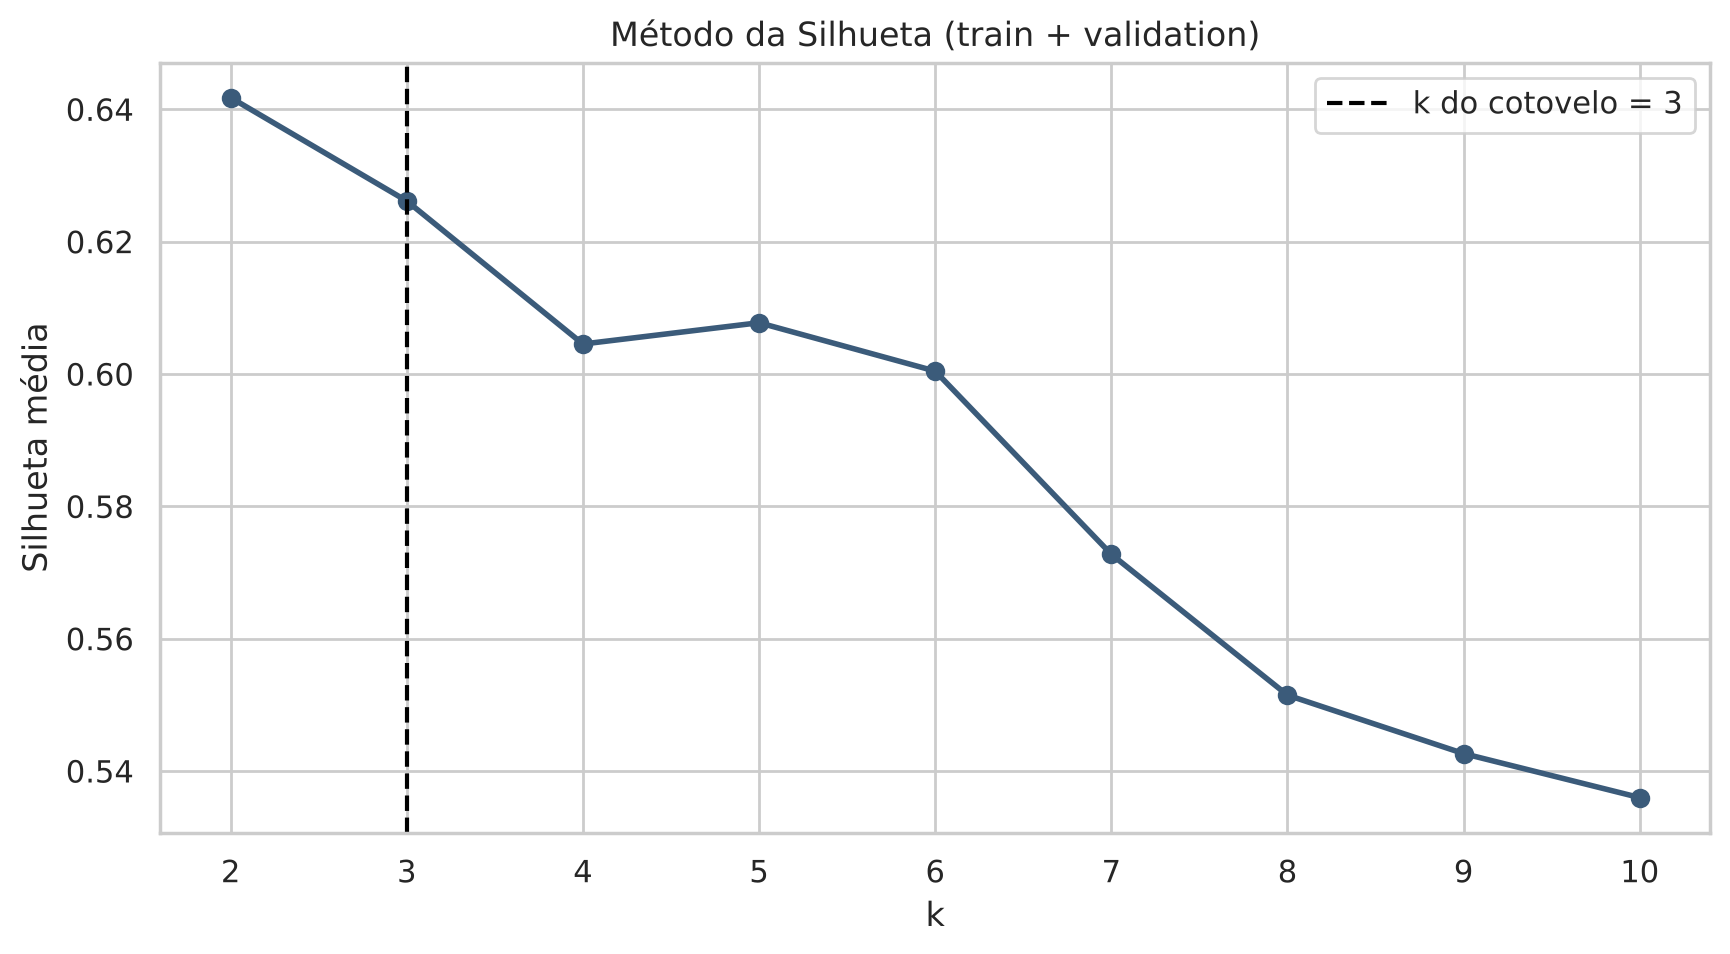


**Escolha de k = 3.**
* **Cotovelo (Kneedle):** k = 3 é o ponto da curva de inércia mais distante da reta de referência. A partir dele, cada cluster a mais traz ganho decrescente.
* **Silhueta:** em k = 3 ela vale **0,626** (acima de 0,5: estrutura forte).
O máximo é em k = 2 (0,642), uma diferença de apenas 0,016. Com valores tão próximos, prevalece o cotovelo, que separa mais um segmento sem perder qualidade de agrupamento.

In [27]:
sil = {k: silhouette_score(Z_trein, KMeans(k, n_init=10, random_state=SEED).fit_predict(Z_trein),
                           sample_size=6000, random_state=SEED) for k in range(2, 11)}
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(list(sil), list(sil.values()), "o-", color="#3b5b7a", lw=2)
ax.axvline(K_COTOVELO, color="black", ls="--", label=f"k do cotovelo = {K_COTOVELO}")
ax.set_title("Método da Silhueta (train + validation)"); ax.set_xlabel("k"); ax.set_ylabel("Silhueta média")
ax.legend(); plt.show()
K = K_COTOVELO
k_sil = max(sil, key=sil.get)
display(Markdown(f"""
**Escolha de k = {K}.**
* **Cotovelo (Kneedle):** k = {K_COTOVELO} é o ponto da curva de inércia mais distante da reta de referência. A partir dele, cada cluster a mais traz ganho decrescente.
* **Silhueta:** em k = {K} ela vale **{brl(sil[K], 3)}**{" (acima de 0,5: estrutura forte)" if sil[K] > .5 else ""}.
""" + (f"Ela também é a máxima entre k = 2 e 10." if k_sil == K else
       f"O máximo é em k = {k_sil} ({brl(sil[k_sil], 3)}), uma diferença de apenas {brl(sil[k_sil] - sil[K], 3)}. "
       f"Com valores tão próximos, prevalece o cotovelo, que separa mais um segmento sem perder qualidade de agrupamento.")))

##Atividade A2.5 (5º Passo): Criar o Modelo: **Clusters**

In [28]:
# NDARRAY - TRANINING: train e validation
kmeans = KMeans(n_clusters=K, n_init=20, random_state=SEED).fit(Z_trein)
# Renomeia os clusters em ordem crescente de renda (Cluster 1 = menor renda)
centros_reais = np.exp(escala_clu.inverse_transform(kmeans.cluster_centers_))
ordem = np.argsort(centros_reais[:, 0])
renome = {old: new + 1 for new, old in enumerate(ordem)}
def prever_cluster(Z):
    return np.vectorize(renome.get)(kmeans.predict(Z))
rot = {k: prever_cluster(Zc[k]) for k in ["train", "validation"]}
pd.DataFrame(centros_reais[ordem], columns=["Centro: RENDA (R$)", "Centro: TOTAL (R$)"],
             index=[f"Cluster {i}" for i in range(1, K + 1)])

,Centro: RENDA (R$),Centro: TOTAL (R$)
Cluster 1,"3,258.3601",329.1727
Cluster 2,"7,921.5762",788.4899
Cluster 3,"21,030.4500","2,178.1554"


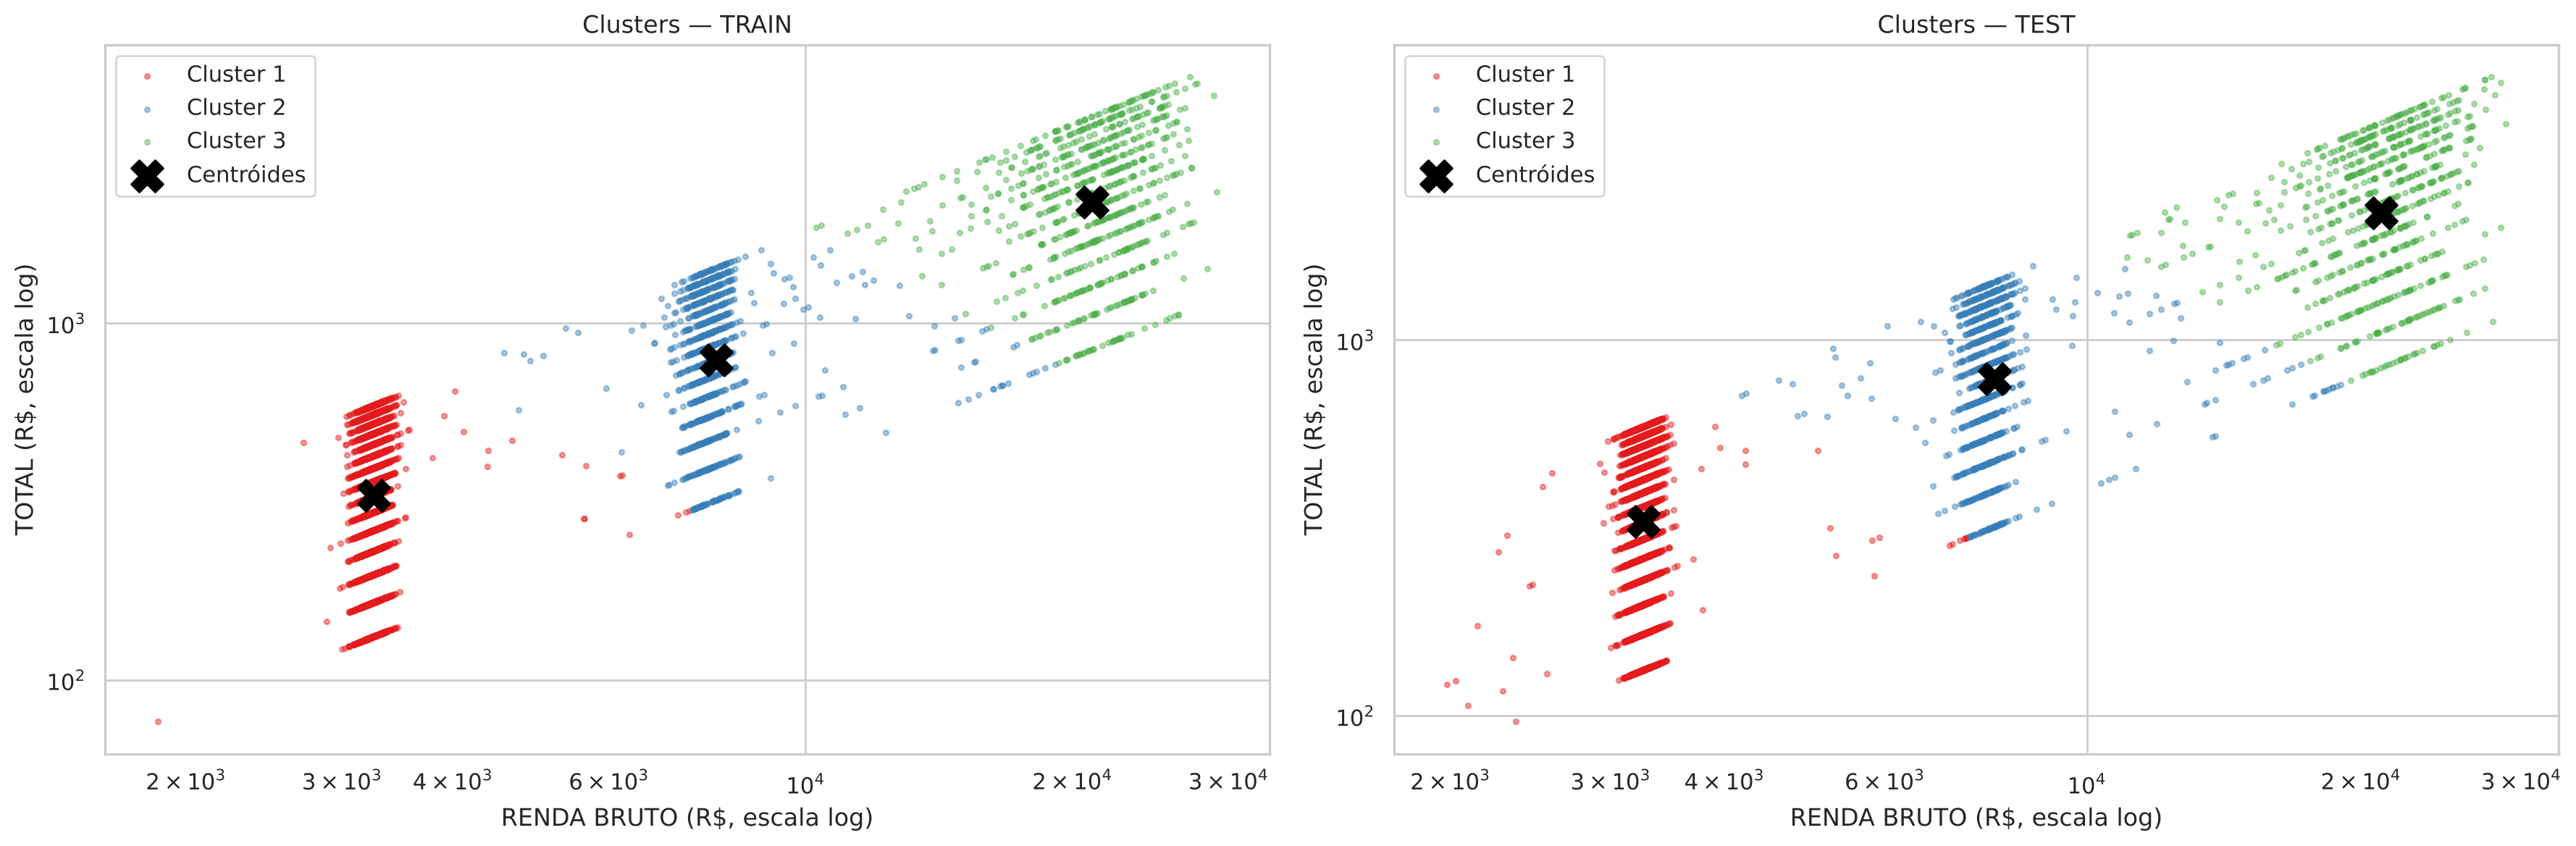

In [29]:
# NDARRAY - TESTE: test
rot["test"] = prever_cluster(Zc["test"])
rot["sample (população)"] = prever_cluster(Zc["sample (população)"])

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
pal = sns.color_palette("Set1", K)
for ax, k in zip(axes, ["train", "test"]):
    base = prep[k]
    for c in range(1, K + 1):
        msk = rot[k] == c
        ax.scatter(base.loc[msk, "RENDA BRUTO (R$)"], base.loc[msk, "TOTAL (R$)"], s=6, alpha=.4, color=pal[c - 1],
                   label=f"Cluster {c}")
    ax.scatter(centros_reais[ordem, 0], centros_reais[ordem, 1], marker="X", s=250, color="black", label="Centróides")
    ax.set_xscale("log"); ax.set_yscale("log"); ax.legend()
    ax.set_title(f"Clusters — {k.upper()}"); ax.set_xlabel("RENDA BRUTO (R$, escala log)"); ax.set_ylabel("TOTAL (R$, escala log)")
plt.tight_layout(); plt.show()

##Atividade A2.6 (6º Passo): Medir a acurácia (score) dos Modelos de Clusterização:

In [30]:
def perfil_clusters(k):
    b = bases[k].copy(); b["Cluster"] = rot[k]; b["Satisf"] = prep[k]["SATISFACAO (1-5)"]
    perf = b.groupby("Cluster").agg(n=("TOTAL (R$)", "size"), RENDA_media=("RENDA BRUTO (R$)", "mean"),
                                    TOTAL_medio=("TOTAL (R$)", "mean"), TOTAL_soma=("TOTAL (R$)", "sum"),
                                    Satisf_4ou5=("Satisf", lambda s: (s >= 4).mean() * 100))
    perf["% clientes"] = perf["n"] / perf["n"].sum() * 100
    perf["% receita"] = perf["TOTAL_soma"] / perf["TOTAL_soma"].sum() * 100
    conta = pd.crosstab(b["Cluster"], b["TIPO DA CONTA"], normalize="index").reindex(columns=ORDEM_CONTAS) * 100
    return pd.concat([perf.drop(columns="TOTAL_soma"), conta.add_prefix("% ")], axis=1)

def score_clusters(k):
    return {"Silhueta": silhouette_score(Zc[k], rot[k]),
            "ARI vs TIPO DA CONTA": adjusted_rand_score(yc[k], rot[k])}

def proporcao(k, ax):
    p = pd.Series(rot[k]).value_counts(normalize=True).sort_index() * 100
    ax.bar([f"Cluster {i}" for i in p.index], p.values, color=pal)
    for i, v in enumerate(p.values):
        ax.text(i, v + 1, f"{brl(v, 1)}%", ha="center")
    ax.set_ylim(0, 100); ax.set_title(f"Proporção dos clusters — {k.upper()}"); ax.set_ylabel("%")
    return p

scores_clu, props = {}, {}

####Atividade A2.6.1: Medir a Proporção dos clusters: Conjunto TRAIN

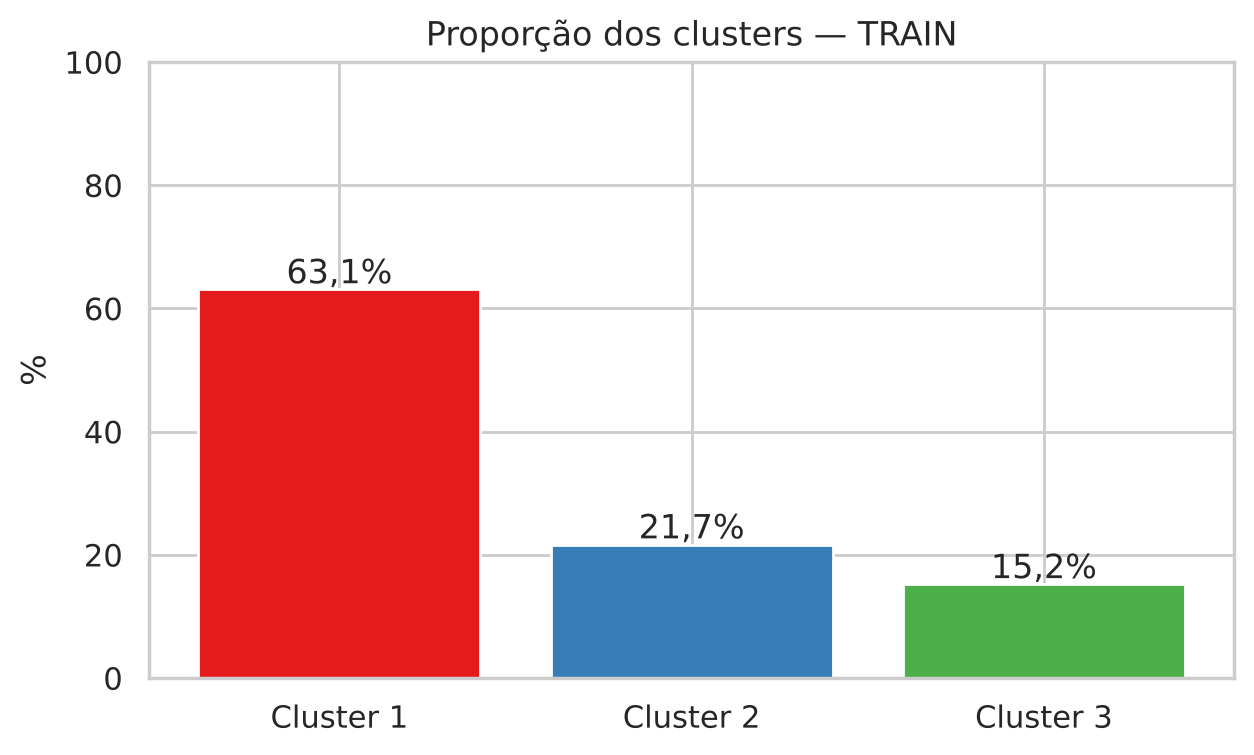

{'Silhueta': 0.6302986183858538, 'ARI vs TIPO DA CONTA': 0.9266462261246241}


,n,RENDA_media,TOTAL_medio,Satisf_4ou5,% clientes,% receita,% ESSENTIAL,% VIP,% PRIME
Cluster,,,,,,,,,
1,3344,"3,262.5910",362.0917,80.4127,63.0943,29.3679,99.3720,0.3589,0.2691
2,1149,"8,013.5206",865.1978,80.1567,21.6792,24.1114,2.5239,93.6466,3.8294
3,807,"21,195.7680","2,376.7612",81.4126,15.2264,46.5207,4.7088,3.9653,91.3259


In [31]:
fig, ax = plt.subplots(figsize=(7, 4)); props["train"] = proporcao("train", ax); plt.show()
scores_clu["train"] = score_clusters("train")
print(scores_clu["train"]); perfil_clusters("train")

####Atividade A2.6.2: Medir a Proporção dos clusters: Conjunto VALIDATION

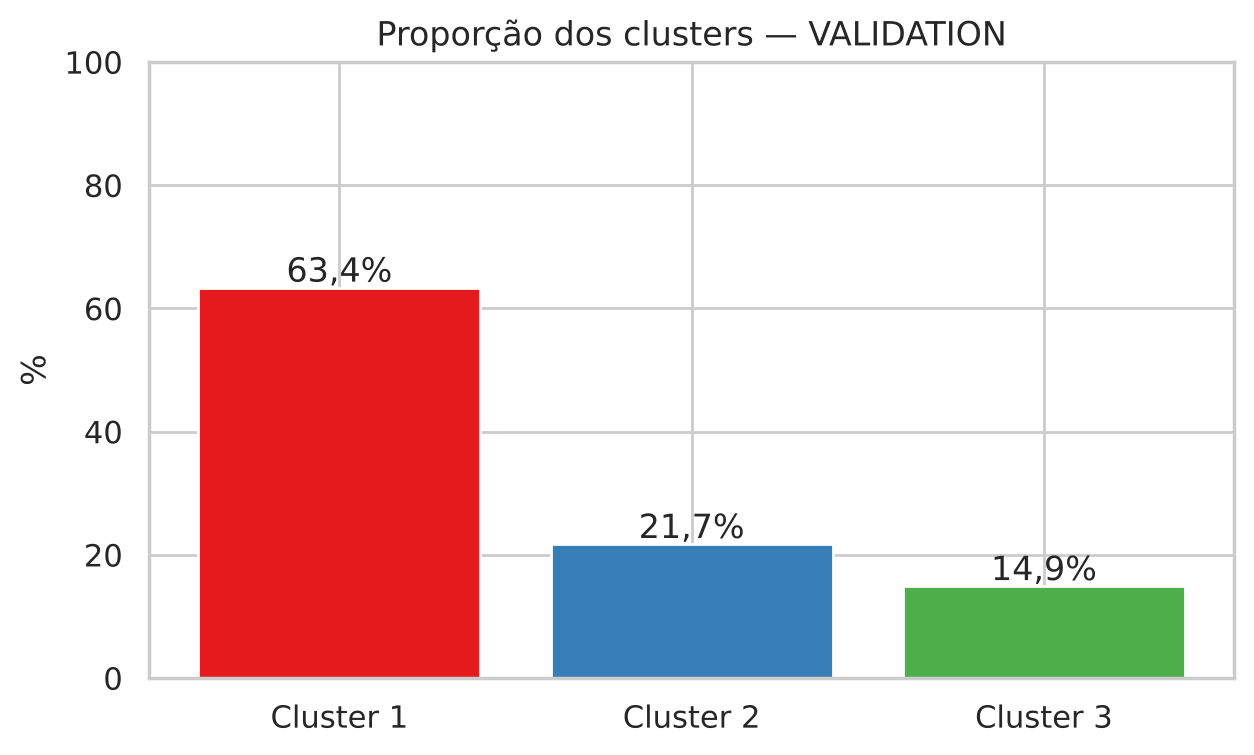

{'Silhueta': 0.62307522384924, 'ARI vs TIPO DA CONTA': 0.9254909029618712}


,n,RENDA_media,TOTAL_medio,Satisf_4ou5,% clientes,% receita,% ESSENTIAL,% VIP,% PRIME
Cluster,,,,,,,,,
1,3358,"3,264.5846",358.9971,78.7373,63.3585,29.6419,99.1662,0.5658,0.2680
2,1152,"8,012.2148",852.6170,78.6458,21.7358,24.1513,2.7778,92.9688,4.2535
3,790,"21,314.6951","2,378.7289",81.3924,14.9057,46.2068,3.5443,3.7975,92.6582


In [32]:
fig, ax = plt.subplots(figsize=(7, 4)); props["validation"] = proporcao("validation", ax); plt.show()
scores_clu["validation"] = score_clusters("validation")
print(scores_clu["validation"]); perfil_clusters("validation")

####Atividade A2.6.3: Medir a Proporção dos clusters: Conjunto TEST

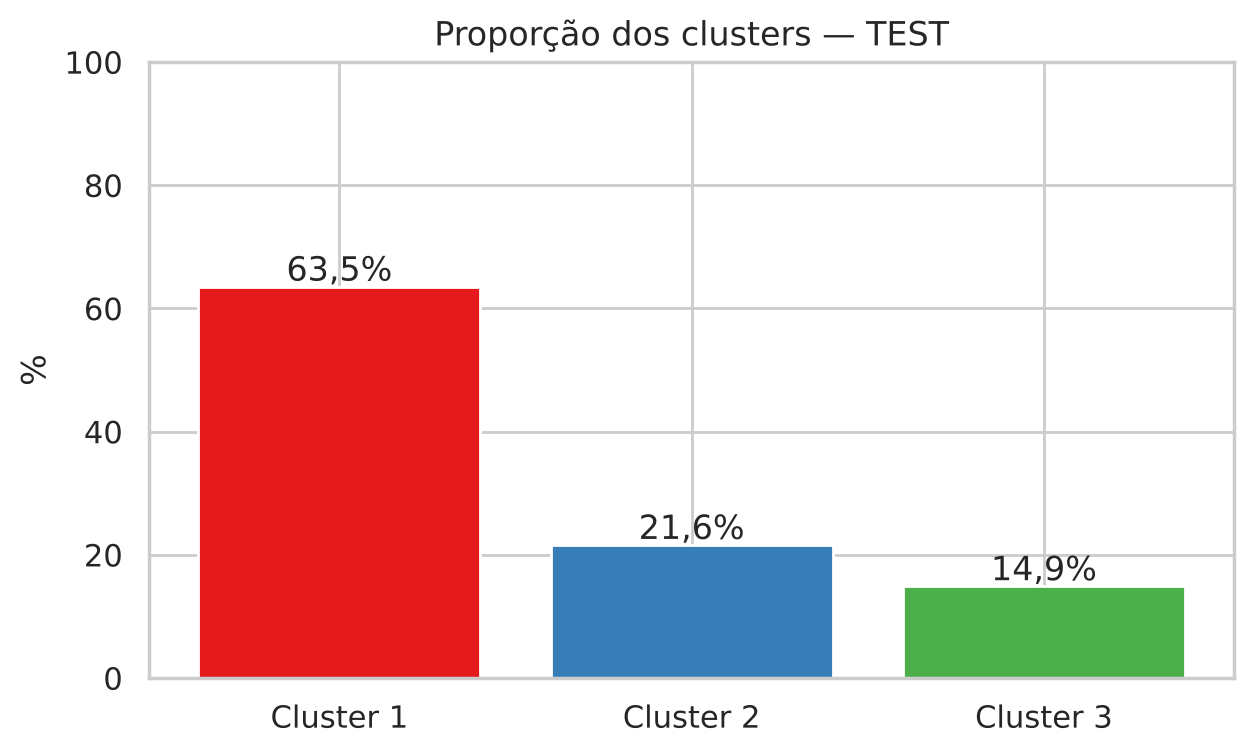

{'Silhueta': 0.6252580656622593, 'ARI vs TIPO DA CONTA': 0.9286903712072695}


,n,RENDA_media,TOTAL_medio,Satisf_4ou5,% clientes,% receita,% ESSENTIAL,% VIP,% PRIME
Cluster,,,,,,,,,
1,3367,"3,263.6627",356.4714,79.8337,63.5283,29.3824,99.1090,0.5346,0.3564
2,1144,"8,019.2627",857.6247,79.9825,21.5849,24.0183,2.3601,93.5315,4.1084
3,789,"21,121.6429","2,412.5837",80.3549,14.8868,46.5993,3.2953,4.0558,92.6489


In [33]:
fig, ax = plt.subplots(figsize=(7, 4)); props["test"] = proporcao("test", ax); plt.show()
scores_clu["test"] = score_clusters("test")
print(scores_clu["test"]); perfil_clusters("test")

##Atividade A2.7 (7º Passo): Testar o Modelo: Dados da População: amostra aleatória (Sample).

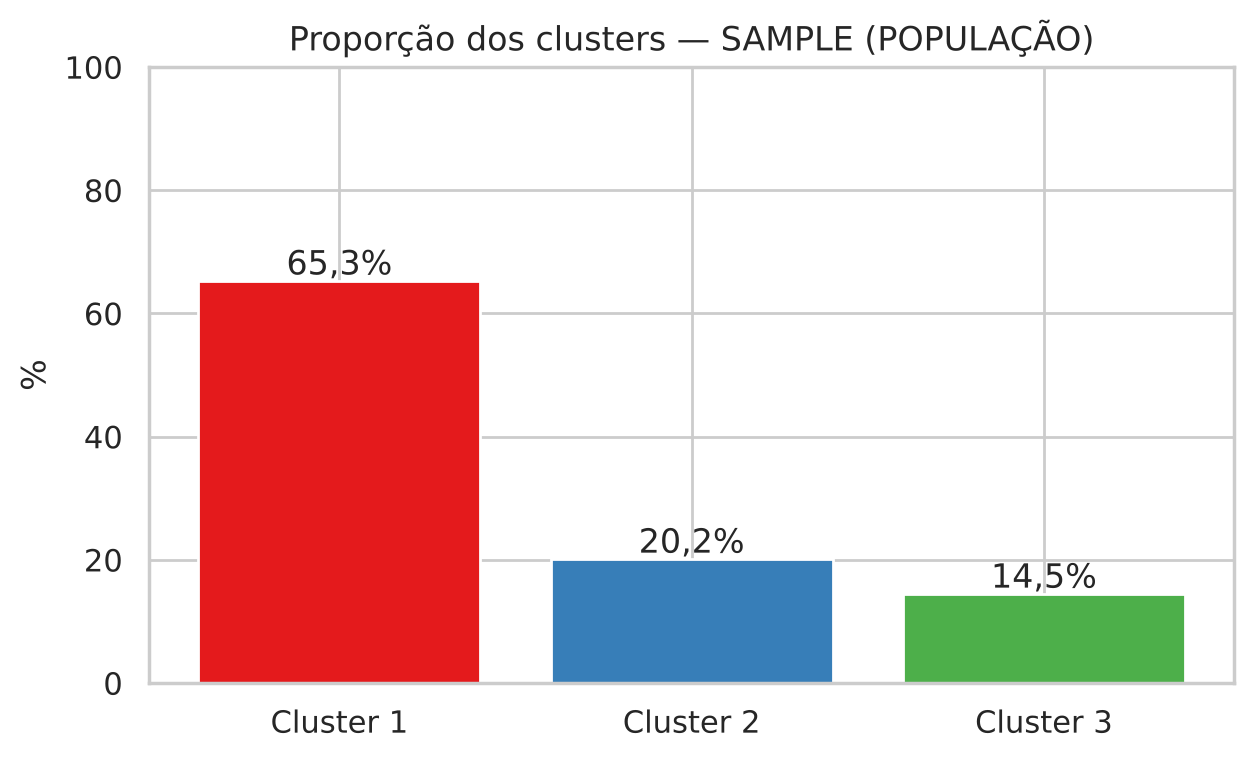

,n,RENDA_media,TOTAL_medio,Satisf_4ou5,% clientes,% receita,% ESSENTIAL,% VIP,% PRIME
Cluster,,,,,,,,,
1,3463,"3,260.1041",356.9415,79.6708,65.3396,31.3651,99.1048,0.6353,0.2599
2,1069,"8,024.4528",844.2284,80.5426,20.1698,22.9000,2.8064,93.6389,3.5547
3,768,"21,145.0098","2,346.8702",80.7292,14.4906,45.7349,2.9948,4.0365,92.9688


Qui-quadrado train × validation × test: χ² = 0,366, gl = 4, p-valor = 0,9852
Qui-quadrado (train+validation+test) × sample: χ² = 7,416, gl = 2, p-valor = 0,0245


,% Cluster 1,% Cluster 2,% Cluster 3,Silhueta,ARI vs TIPO DA CONTA
train,63.0943,21.6792,15.2264,0.6303,0.9266
validation,63.3585,21.7358,14.9057,0.6231,0.9255
test,63.5283,21.5849,14.8868,0.6253,0.9287
sample (população),65.3396,20.1698,14.4906,0.6224,0.9309


In [34]:
fig, ax = plt.subplots(figsize=(7, 4)); props["sample (população)"] = proporcao("sample (população)", ax); plt.show()
scores_clu["sample (população)"] = score_clusters("sample (população)")
perf_s = perfil_clusters("sample (população)")
display(perf_s)

tab_clu = pd.concat([pd.DataFrame(props).T.add_prefix("% Cluster "), pd.DataFrame(scores_clu).T], axis=1)
# Teste qui-quadrado de homogeneidade: as proporções dos clusters são iguais nos 4 conjuntos?
cont3 = np.array([pd.Series(rot[k]).value_counts().sort_index().values for k in CONJUNTOS])
chi2, p_chi, gl, _ = stats.chi2_contingency(cont3)
cont_s = np.vstack([cont3.sum(axis=0), pd.Series(rot["sample (população)"]).value_counts().sort_index().values])
chi2_s, p_chi_s, gl_s, _ = stats.chi2_contingency(cont_s)
print(f"Qui-quadrado train × validation × test: χ² = {brl(chi2, 3)}, gl = {gl}, p-valor = {brl(p_chi, 4)}")
print(f"Qui-quadrado (train+validation+test) × sample: χ² = {brl(chi2_s, 3)}, gl = {gl_s}, p-valor = {brl(p_chi_s, 4)}")
tab_clu

## RELATÓRIO PARCIAL - MODELO DE CLUSTERIZAÇÃO

In [35]:
pt = perfil_clusters("test")
display(Markdown(f"""
**RELATÓRIO PARCIAL — MODELO DE CLUSTERIZAÇÃO** (para os gestores da UVVine)

*   ✅ **Modelo:** K-Means com **k = {K}**, escolhido pelo método do cotovelo e confirmado pela silhueta ({brl(sil[K], 3)}).
    Variáveis: log da renda e log do gasto. As 13 químicas não formam grupos (silhueta ≈ {brl(np.mean(list(sil_quim.values())), 2)}) e foram descartadas.
*   ✅ **Segmentos encontrados (test):**
""" + "\n".join(f"    * **Cluster {c}:** {brl(pt.loc[c,'% clientes'],1)}% dos clientes e {brl(pt.loc[c,'% receita'],1)}% da receita. Renda média de R$ {brl(pt.loc[c,'RENDA_media'])}, gasto médio de R$ {brl(pt.loc[c,'TOTAL_medio'])}. "
                f"Composição: {brl(pt.loc[c,'% ESSENTIAL'],0)}% ESSENTIAL / {brl(pt.loc[c,'% VIP'],0)}% VIP / {brl(pt.loc[c,'% PRIME'],0)}% PRIME."
                for c in pt.index) + f"""
*   ✅ **Estabilidade:** as proporções dos clusters {"não diferem" if p_chi >= .05 else "diferem"} entre train, validation e test (qui-quadrado p = {brl(p_chi, 4)}), e a silhueta fica em torno de {brl(tab_clu['Silhueta'].mean(), 3)} em todos os conjuntos.
    Na sample, a proporção do Cluster 1 é {brl(props['sample (população)'].iloc[0], 1)}% (p = {brl(p_chi_s, 4)} contra os demais). Isso reflete a composição da própria sample, que saiu com mais ESSENTIAL por acaso, e não instabilidade do modelo.
    A segmentação **generaliza** para dados novos.
*   ✅ **Concordância com o negócio:** sem nunca ver o tipo de conta, o K-Means recupera os planos com ARI = {brl(tab_clu['ARI vs TIPO DA CONTA'].mean(), 3)} (1 = concordância perfeita).
    {"Os segmentos naturais de renda e gasto **coincidem com ESSENTIAL, VIP e PRIME**." if (K == 3 and tab_clu['ARI vs TIPO DA CONTA'].mean() > .8) else "Os segmentos naturais só em parte coincidem com os planos."} Clientes cujo cluster não bate com o plano são candidatos naturais a **upgrade ou downgrade de plano**.
*   ✅ **Satisfação:** o índice de satisfeitos (nota 4 ou 5) é parecido entre os clusters ({", ".join(brl(v,1) + "%" for v in pt['Satisf_4ou5'])}). A satisfação **não depende do segmento financeiro**.
"""))


**RELATÓRIO PARCIAL — MODELO DE CLUSTERIZAÇÃO** (para os gestores da UVVine)

*   ✅ **Modelo:** K-Means com **k = 3**, escolhido pelo método do cotovelo e confirmado pela silhueta (0,626).
    Variáveis: log da renda e log do gasto. As 13 químicas não formam grupos (silhueta ≈ 0,05) e foram descartadas.
*   ✅ **Segmentos encontrados (test):**
    * **Cluster 1:** 63,5% dos clientes e 29,4% da receita. Renda média de R$ 3.263,66, gasto médio de R$ 356,47. Composição: 99% ESSENTIAL / 1% VIP / 0% PRIME.
    * **Cluster 2:** 21,6% dos clientes e 24,0% da receita. Renda média de R$ 8.019,26, gasto médio de R$ 857,62. Composição: 2% ESSENTIAL / 94% VIP / 4% PRIME.
    * **Cluster 3:** 14,9% dos clientes e 46,6% da receita. Renda média de R$ 21.121,64, gasto médio de R$ 2.412,58. Composição: 3% ESSENTIAL / 4% VIP / 93% PRIME.
*   ✅ **Estabilidade:** as proporções dos clusters não diferem entre train, validation e test (qui-quadrado p = 0,9852), e a silhueta fica em torno de 0,625 em todos os conjuntos.
    Na sample, a proporção do Cluster 1 é 65,3% (p = 0,0245 contra os demais). Isso reflete a composição da própria sample, que saiu com mais ESSENTIAL por acaso, e não instabilidade do modelo.
    A segmentação **generaliza** para dados novos.
*   ✅ **Concordância com o negócio:** sem nunca ver o tipo de conta, o K-Means recupera os planos com ARI = 0,928 (1 = concordância perfeita).
    Os segmentos naturais de renda e gasto **coincidem com ESSENTIAL, VIP e PRIME**. Clientes cujo cluster não bate com o plano são candidatos naturais a **upgrade ou downgrade de plano**.
*   ✅ **Satisfação:** o índice de satisfeitos (nota 4 ou 5) é parecido entre os clusters (79,8%, 80,0%, 80,4%). A satisfação **não depende do segmento financeiro**.


#Atividade A3: Modelo de Classificação

**Pergunta de negócio:** *qual é o plano (ESSENTIAL, VIP ou PRIME) adequado ao perfil de um cliente?*

Um classificador desse tipo serve para **recomendar o plano a novos clientes** e para identificar clientes num plano inadequado ao seu perfil.

* **Alvo:** TIPO DA CONTA (3 classes).
* **Entradas:** renda, gasto total, dependentes, satisfação, região, sexo e estado civil.
* As químicas ficam de fora: são independentes do perfil do cliente (Parte 1 e A2), e 13 dimensões de ruído prejudicariam modelos baseados em distância (KNN, SVM, Gaussian Process).

##Atividade A3.1 (1º Passo): Normalizar - Mapear - Discretizar

In [36]:
FEATURES_CLF = (["RENDA BRUTO (R$)", "TOTAL (R$)", "DEPENDENTES", "SATISFACAO (1-5)"] +
                [c for c in prep["train"].columns if c.split("=")[0] in ("REGIÃO", "SEXO", "ESTADO CIVIL")])
print(len(FEATURES_CLF), "variáveis:", FEATURES_CLF)
pd.DataFrame({k: prep[k]["CONTA_COD"].map(dict(enumerate(ORDEM_CONTAS))).value_counts(normalize=True).reindex(ORDEM_CONTAS) * 100
              for k in prep}).round(2)

11 variáveis: ['RENDA BRUTO (R$)', 'TOTAL (R$)', 'DEPENDENTES', 'SATISFACAO (1-5)', 'REGIÃO=SUL', 'REGIÃO=CENTRO-OESTE', 'REGIÃO=NORDESTE', 'REGIÃO=NORTE', 'SEXO=FEMININO', 'ESTADO CIVIL=SOLTEIRO', 'ESTADO CIVIL=DESQUITADO(A) / VIÚVO(A)']


,train,validation,test,sample (população)
CONTA_COD,,,,
ESSENTIAL,63.9600,63.9600,63.9600,65.7500
VIP,21.1300,21.1300,21.1300,19.8900
PRIME,14.9100,14.9100,14.9100,14.3600


##Atividade A3.2 (2º Passo) - ETL: Separar Entrada ($X$) da Saída ($y$)

In [37]:
# a partir daqui temos apenas: NDARRAY
# NDARRAY: train - validation - test
Xk = {k: prep[k][FEATURES_CLF].to_numpy(dtype=float) for k in prep}
yk = {k: prep[k]["CONTA_COD"].to_numpy() for k in prep}
for k in Xk:
    print(f"{k:<20} X: {Xk[k].shape}  y: {yk[k].shape}  classes: {np.bincount(yk[k])}")

train                X: (5300, 11)  y: (5300,)  classes: [3390 1120  790]
validation           X: (5300, 11)  y: (5300,)  classes: [3390 1120  790]
test                 X: (5300, 11)  y: (5300,)  classes: [3390 1120  790]
sample (população)   X: (5300, 11)  y: (5300,)  classes: [3485 1054  761]


##Atividade A3.3 (3º Passo): Escolher / Criar o Modelo: **Classifiers**

Escolher enter os seguintes - **Classifiers**:

1.   Nearest Neighbors
2.   Linear SVM
2.   RBF SVM
2.   Gaussian Process
2.   Decision Tree
2.   Random Forest
2.   Neural Net
2.   AdaBoost
2.   Naive Bayes
2.   QDA

**Qual obteve o maior SCORE ?**

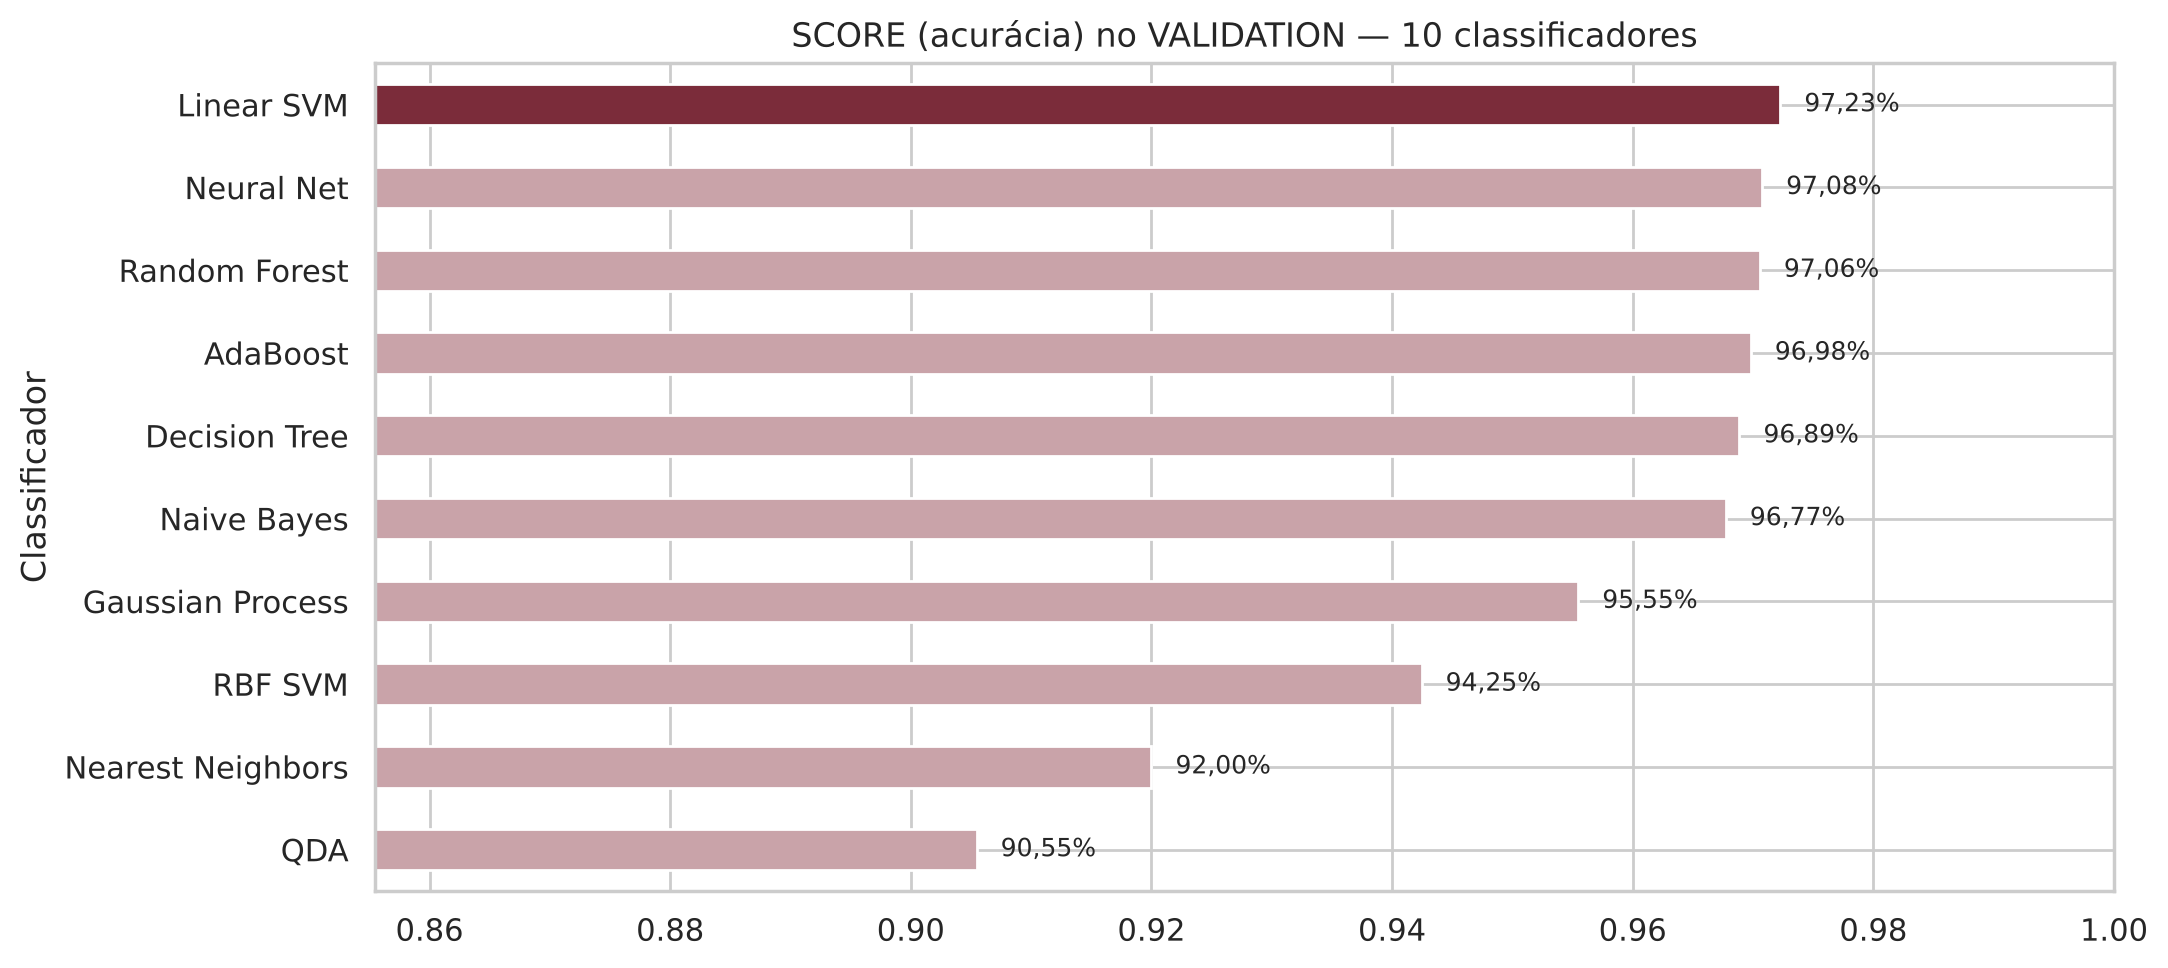

Maior SCORE no validation: Linear SVM


,n treino,Acurácia train,Acurácia validation,F1-macro validation,Tempo (s)
Classificador,,,,,
Linear SVM,5300,0.9719,0.9723,0.9589,0.2152
Neural Net,5300,0.9726,0.9708,0.9561,1.1137
Random Forest,5300,0.9734,0.9706,0.9550,0.2280
AdaBoost,5300,0.9730,0.9698,0.9546,0.1697
Decision Tree,5300,0.9777,0.9689,0.9525,0.0095
Naive Bayes,5300,0.9668,0.9677,0.9543,0.0026
Gaussian Process,1000,0.9760,0.9555,0.9365,16.5604
RBF SVM,5300,0.9830,0.9425,0.9185,0.3548
Nearest Neighbors,5300,0.9296,0.9200,0.8959,0.0085


In [38]:
classificadores = {
    "Nearest Neighbors": KNeighborsClassifier(15),
    "Linear SVM": SVC(kernel="linear", C=0.025, random_state=SEED),
    "RBF SVM": SVC(gamma=2, C=1, random_state=SEED),
    "Gaussian Process": GaussianProcessClassifier(1.0 * RBF(1.0), random_state=SEED),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=SEED),
    "Random Forest": RandomForestClassifier(max_depth=5, n_estimators=100, random_state=SEED, n_jobs=-1),
    "Neural Net": MLPClassifier(alpha=1, max_iter=1000, random_state=SEED),
    "AdaBoost": AdaBoostClassifier(random_state=SEED),
    "Naive Bayes": GaussianNB(),
    "QDA": QuadraticDiscriminantAnalysis(reg_param=0.1),
}
# O Gaussian Process tem custo O(n³): é treinado com 1.000 linhas estratificadas do train (os demais usam o train inteiro)
X_gp, _, y_gp, _ = train_test_split(Xk["train"], yk["train"], train_size=1000, stratify=yk["train"], random_state=SEED)

linhas, modelos_clf = [], {}
for nome, clf in classificadores.items():
    pipe = make_pipeline(StandardScaler(), clf)
    Xt, ytr = (X_gp, y_gp) if nome == "Gaussian Process" else (Xk["train"], yk["train"])
    t0 = time.time(); pipe.fit(Xt, ytr); dt = time.time() - t0
    pv = pipe.predict(Xk["validation"])
    modelos_clf[nome] = pipe
    linhas.append({"Classificador": nome, "n treino": len(ytr), "Acurácia train": pipe.score(Xt, ytr),
                   "Acurácia validation": accuracy_score(yk["validation"], pv),
                   "F1-macro validation": f1_score(yk["validation"], pv, average="macro"), "Tempo (s)": dt})
tab_clf = pd.DataFrame(linhas).set_index("Classificador").sort_values("Acurácia validation", ascending=False)
MELHOR_CLF = tab_clf.index[0]
clf = modelos_clf[MELHOR_CLF]

fig, ax = plt.subplots(figsize=(11, 5))
tab_clf["Acurácia validation"][::-1].plot.barh(ax=ax, color=["#7b2c3a" if i == MELHOR_CLF else "#c9a3a9" for i in tab_clf.index[::-1]])
ax.set_xlim(tab_clf["Acurácia validation"].min() - .05, 1)
for i, v in enumerate(tab_clf["Acurácia validation"][::-1]):
    ax.text(v + .002, i, pct(v), va="center", fontsize=9)
ax.set_title("SCORE (acurácia) no VALIDATION — 10 classificadores"); plt.tight_layout(); plt.show()
print("Maior SCORE no validation:", MELHOR_CLF)
tab_clf

In [39]:
display(Markdown(f"""
**Qual obteve o maior SCORE?** O **{MELHOR_CLF}**, com acurácia de **{pct(tab_clf.loc[MELHOR_CLF,'Acurácia validation'])}** e F1-macro de {brl(tab_clf.loc[MELHOR_CLF,'F1-macro validation'], 4)} no validation.

* Vários modelos ficam muito próximos do topo (entre {pct(tab_clf['Acurácia validation'].iloc[4])} e {pct(tab_clf['Acurácia validation'].iloc[0])} nos cinco primeiros), porque o plano é bem determinado pela renda.
* Os piores são o {tab_clf.index[-1]} ({pct(tab_clf['Acurácia validation'].iloc[-1])}) e o {tab_clf.index[-2]} ({pct(tab_clf['Acurácia validation'].iloc[-2])}).
* A acurácia de train e de validation é próxima no modelo escolhido, então não há sinal de overfitting.
* Referência mínima: chutar sempre "ESSENTIAL" acertaria {pct((yk['validation'] == 0).mean())}.
"""))


**Qual obteve o maior SCORE?** O **Linear SVM**, com acurácia de **97,23%** e F1-macro de 0,9589 no validation.

* Vários modelos ficam muito próximos do topo (entre 96,89% e 97,23% nos cinco primeiros), porque o plano é bem determinado pela renda.
* Os piores são o QDA (90,55%) e o Nearest Neighbors (92,00%).
* A acurácia de train e de validation é próxima no modelo escolhido, então não há sinal de overfitting.
* Referência mínima: chutar sempre "ESSENTIAL" acertaria 63,96%.


### A3.3.1: Intervalo de confiança: Train

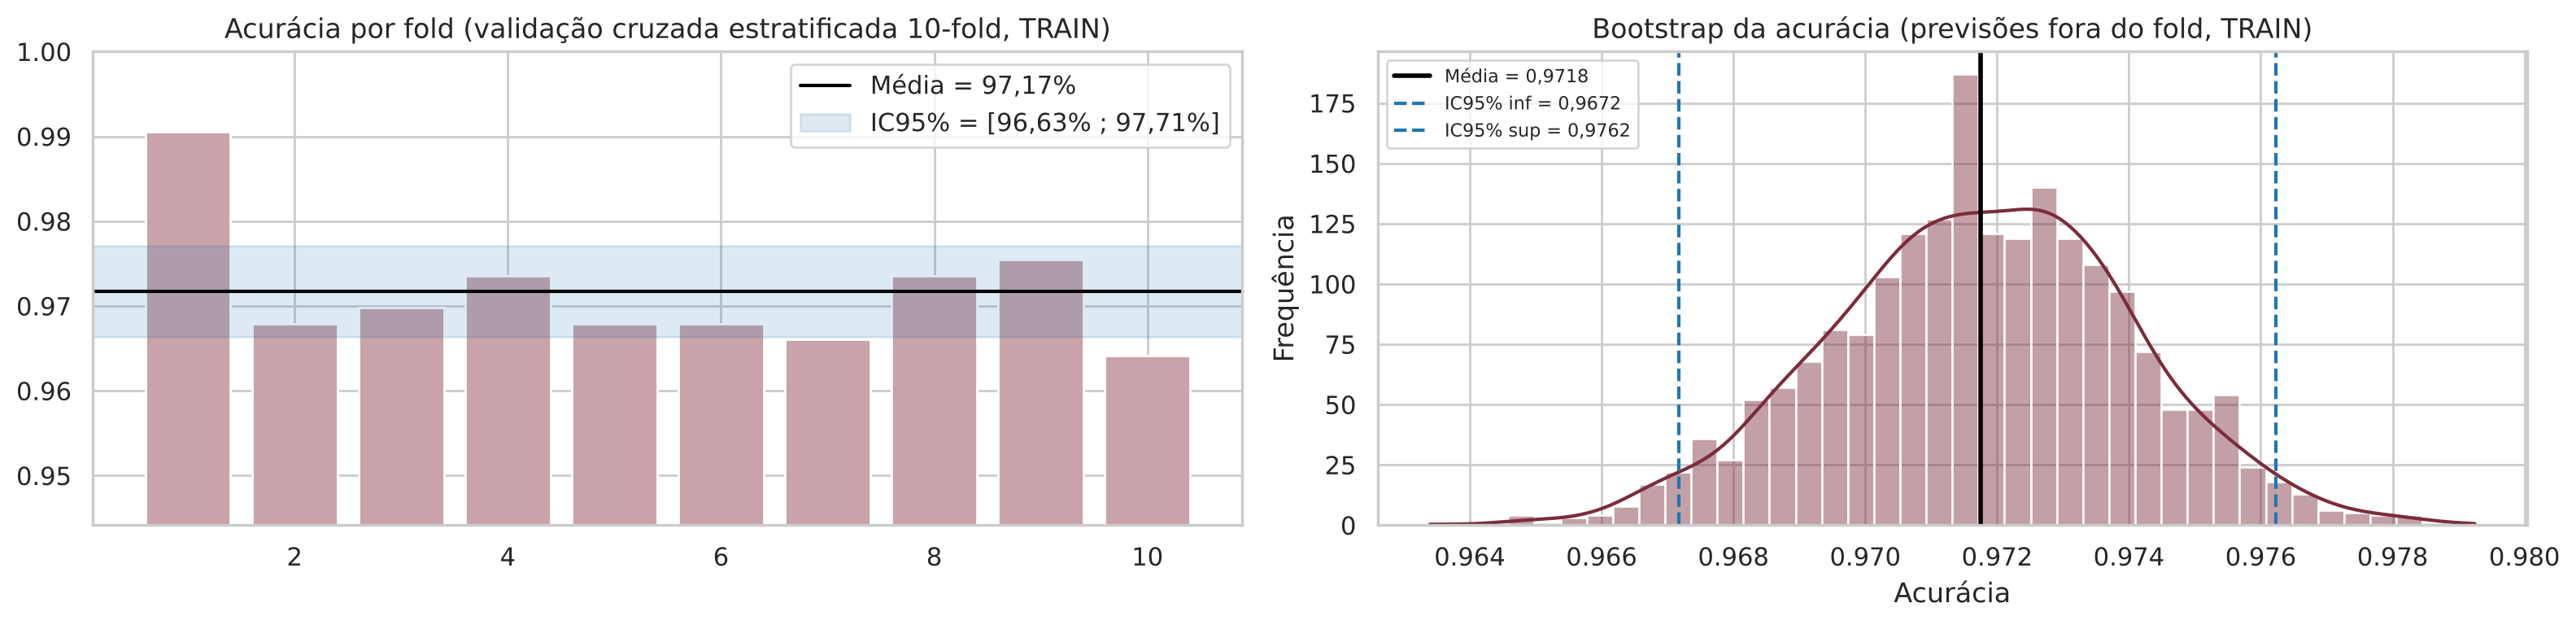

TRAIN | CV: 97,17% (IC95% 96,63% a 97,71%) | Bootstrap: IC95% 96,72% a 97,62%


In [40]:
skf10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
cv_clf_train = cross_val_score(make_pipeline(StandardScaler(), classificadores[MELHOR_CLF]), Xk["train"], yk["train"],
                               cv=skf10, scoring="accuracy")
mc, loc_, hic = ic_validacao_cruzada(cv_clf_train)
oof_c = cross_val_predict(make_pipeline(StandardScaler(), classificadores[MELHOR_CLF]), Xk["train"], yk["train"], cv=skf10)
boot_acc_train = bootstrap_metrica(yk["train"], oof_c, accuracy_score)

fig, axes = plt.subplots(1, 2, figsize=(16, 4))
axes[0].bar(range(1, 11), cv_clf_train, color="#c9a3a9"); axes[0].axhline(mc, color="black", label=f"Média = {pct(mc)}")
axes[0].axhspan(loc_, hic, color="tab:blue", alpha=.15, label=f"IC95% = [{pct(loc_)} ; {pct(hic)}]")
axes[0].set_ylim(min(cv_clf_train) - .02, 1); axes[0].set_title("Acurácia por fold (validação cruzada estratificada 10-fold, TRAIN)")
axes[0].legend()
ic_clf_train = grafico_ic(boot_acc_train, "Bootstrap da acurácia (previsões fora do fold, TRAIN)", "Acurácia", axes[1])
plt.tight_layout(); plt.show()
print(f"TRAIN | CV: {pct(mc)} (IC95% {pct(loc_)} a {pct(hic)}) | Bootstrap: IC95% {pct(ic_clf_train['ic_inf'])} a {pct(ic_clf_train['ic_sup'])}")

### A3.3.2: Intervalo de confiança: Validation

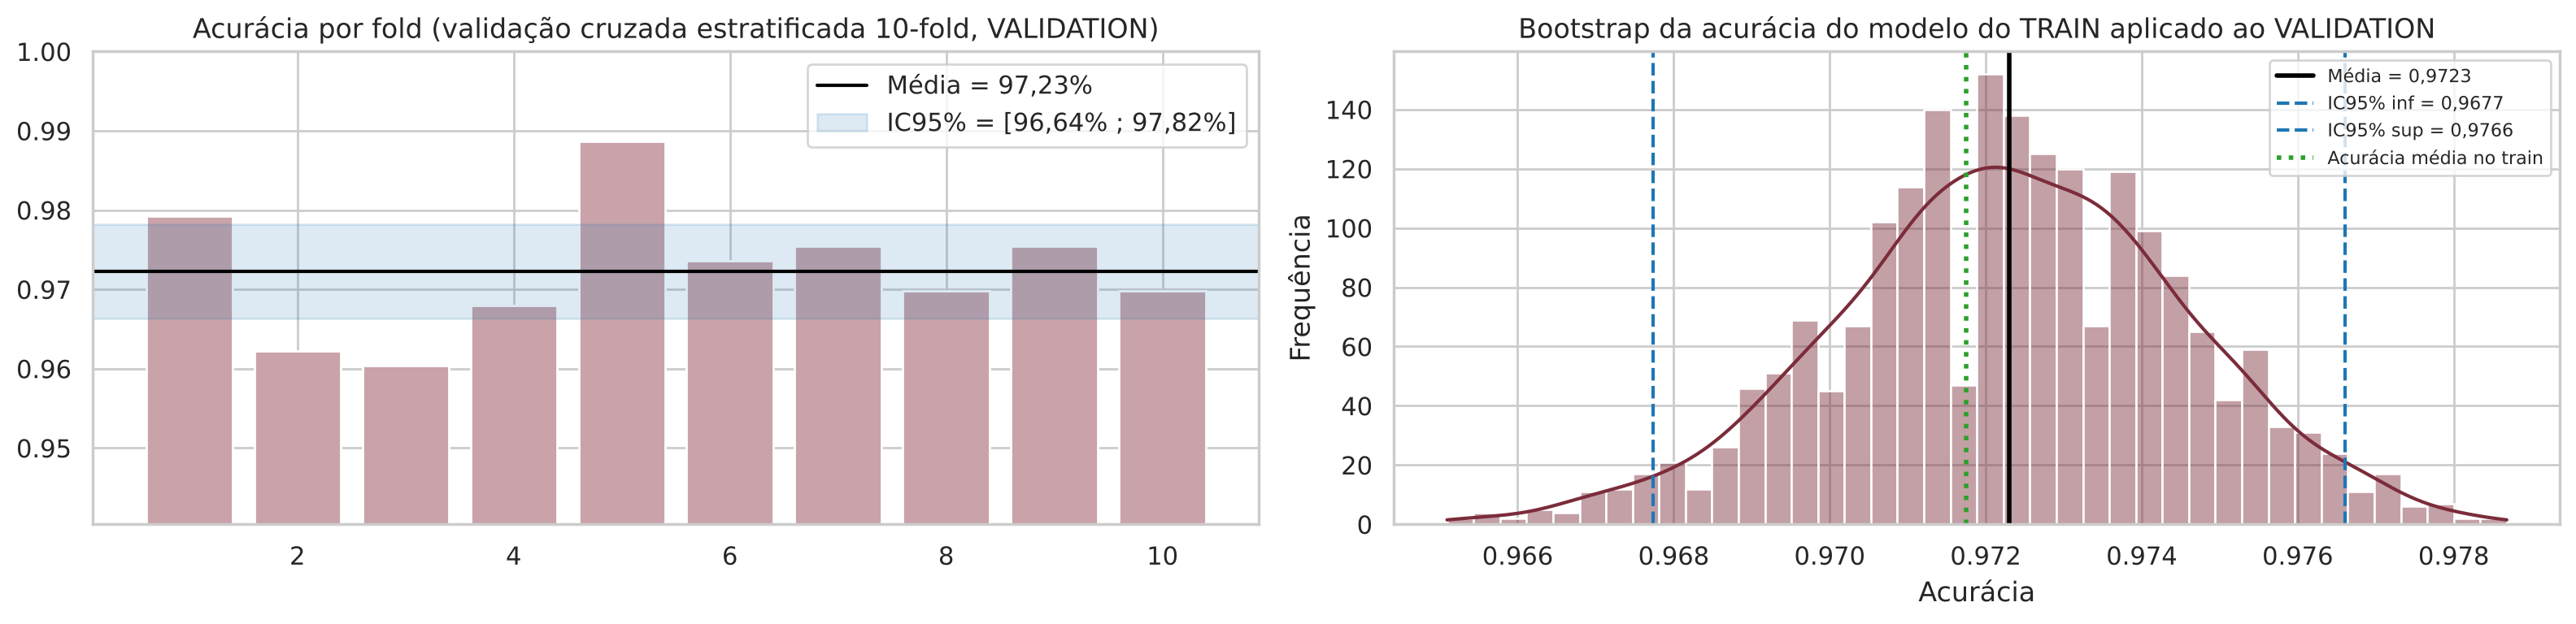

VALIDATION | CV: 97,23% (IC95% 96,64% a 97,82%) | Bootstrap: IC95% 96,77% a 97,66%


In [41]:
cv_clf_val = cross_val_score(make_pipeline(StandardScaler(), classificadores[MELHOR_CLF]), Xk["validation"], yk["validation"],
                             cv=skf10, scoring="accuracy")
mcv, locv, hicv = ic_validacao_cruzada(cv_clf_val)
boot_acc_val = bootstrap_metrica(yk["validation"], clf.predict(Xk["validation"]), accuracy_score)

fig, axes = plt.subplots(1, 2, figsize=(16, 4))
axes[0].bar(range(1, 11), cv_clf_val, color="#c9a3a9"); axes[0].axhline(mcv, color="black", label=f"Média = {pct(mcv)}")
axes[0].axhspan(locv, hicv, color="tab:blue", alpha=.15, label=f"IC95% = [{pct(locv)} ; {pct(hicv)}]")
axes[0].set_ylim(min(cv_clf_val) - .02, 1); axes[0].set_title("Acurácia por fold (validação cruzada estratificada 10-fold, VALIDATION)")
axes[0].legend()
ic_clf_val = grafico_ic(boot_acc_val, "Bootstrap da acurácia do modelo do TRAIN aplicado ao VALIDATION", "Acurácia", axes[1],
                        extra=[(ic_clf_train["media"], "Acurácia média no train")])
plt.tight_layout(); plt.show()
print(f"VALIDATION | CV: {pct(mcv)} (IC95% {pct(locv)} a {pct(hicv)}) | Bootstrap: IC95% {pct(ic_clf_val['ic_inf'])} a {pct(ic_clf_val['ic_sup'])}")

##Atividade A3.4 (4º Passo): Medir a acurácia (score) dos Modelos de Classificação:

In [42]:
def matriz_confusao(k):
    """Matriz de confusão (contagens e % por linha) + relatório de classificação."""
    yp = clf.predict(Xk[k])
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    ConfusionMatrixDisplay(confusion_matrix(yk[k], yp), display_labels=ORDEM_CONTAS).plot(ax=axes[0], cmap="Reds", colorbar=False)
    ConfusionMatrixDisplay(confusion_matrix(yk[k], yp, normalize="true") * 100, display_labels=ORDEM_CONTAS).plot(
        ax=axes[1], cmap="Reds", colorbar=False, values_format=".1f")
    axes[0].set_title(f"{k.upper()} — contagens"); axes[1].set_title(f"{k.upper()} — % por classe real (recall)")
    for ax in axes:
        ax.set_xlabel("Previsto"); ax.set_ylabel("Real"); ax.grid(False)
    plt.suptitle(f"Matriz de confusão — {MELHOR_CLF} — acurácia = {pct(accuracy_score(yk[k], yp))}", fontsize=13)
    plt.tight_layout(); plt.show()
    print(classification_report(yk[k], yp, target_names=ORDEM_CONTAS, digits=4))
    return {"Acurácia": accuracy_score(yk[k], yp), "F1-macro": f1_score(yk[k], yp, average="macro"), "n": len(yp)}

score_clf = {}

####Atividade A3.4.1: Medir a acurácia (score) - Matriz de Confusão: Conjunto TRAIN

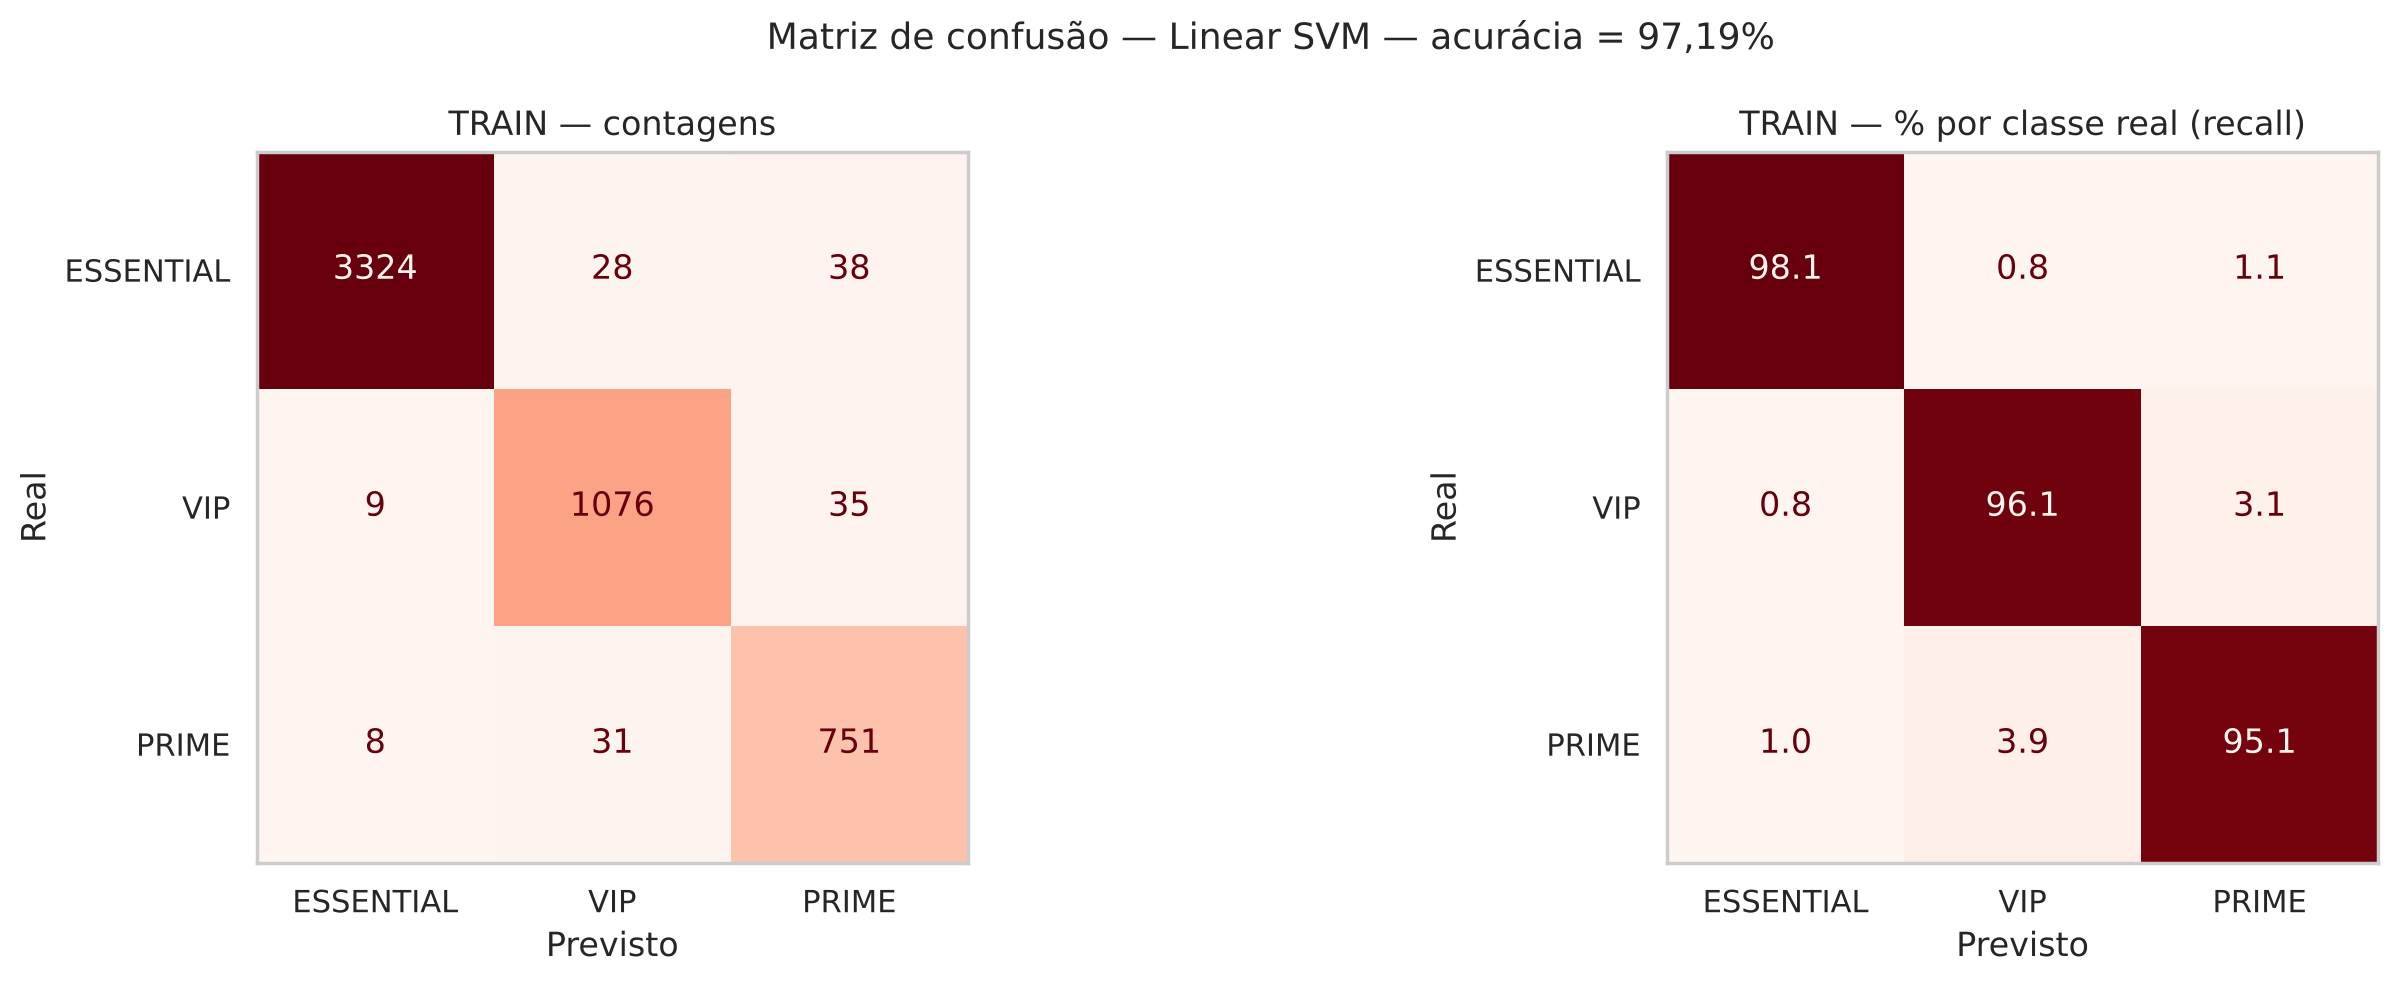

              precision    recall  f1-score   support

   ESSENTIAL     0.9949    0.9805    0.9877      3390
         VIP     0.9480    0.9607    0.9543      1120
       PRIME     0.9114    0.9506    0.9306       790

    accuracy                         0.9719      5300
   macro avg     0.9514    0.9640    0.9575      5300
weighted avg     0.9726    0.9719    0.9721      5300



In [43]:
score_clf["train"] = matriz_confusao("train")

####Atividade A3.4.2: Medir a acurácia (score) - Matriz de Confusão: Conjunto VALIDATION

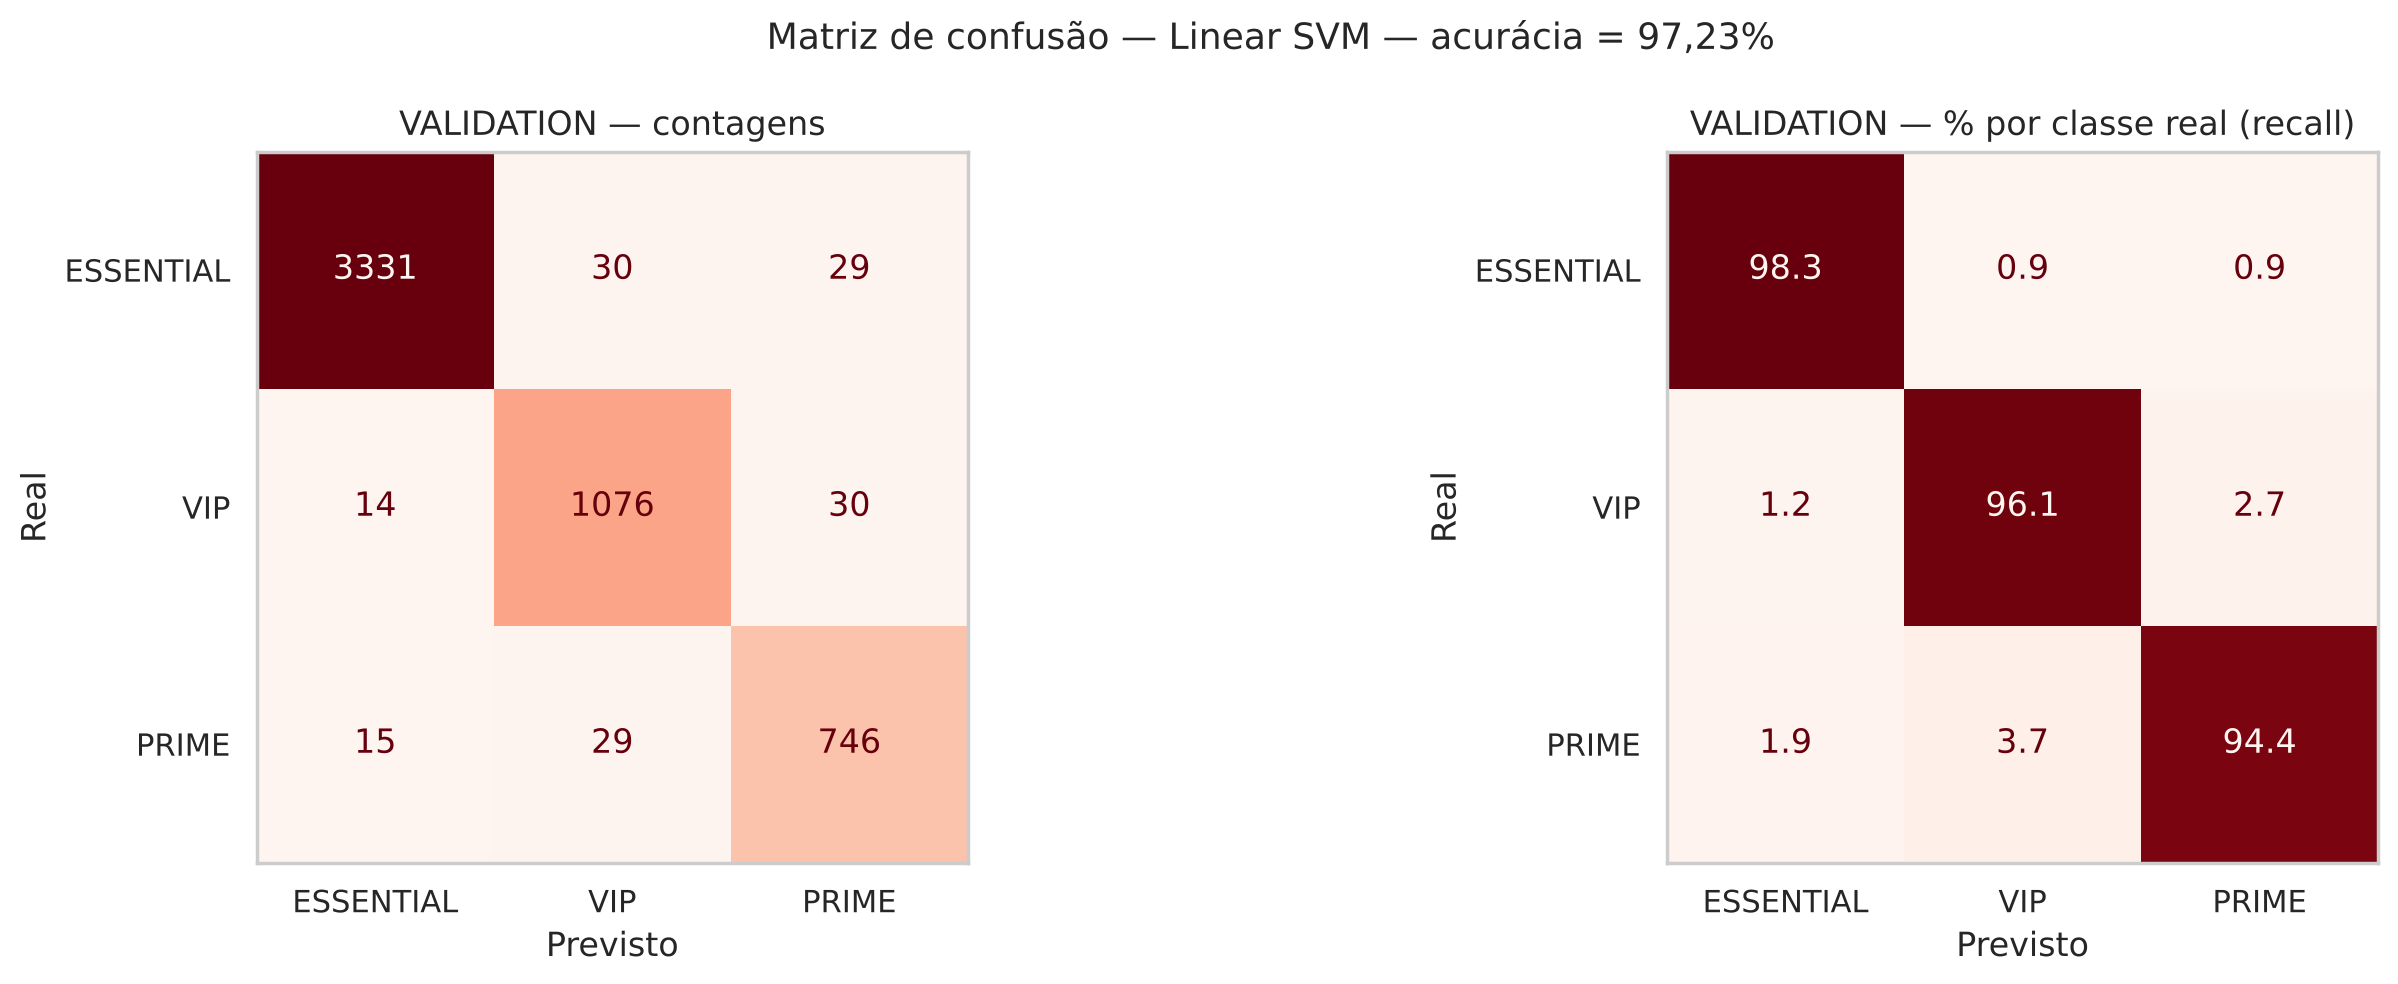

              precision    recall  f1-score   support

   ESSENTIAL     0.9914    0.9826    0.9870      3390
         VIP     0.9480    0.9607    0.9543      1120
       PRIME     0.9267    0.9443    0.9354       790

    accuracy                         0.9723      5300
   macro avg     0.9554    0.9625    0.9589      5300
weighted avg     0.9726    0.9723    0.9724      5300



In [44]:
score_clf["validation"] = matriz_confusao("validation")

####Atividade A3.4.3: Medir a acurácia (score) - Matriz de Confusão: Conjunto TEST

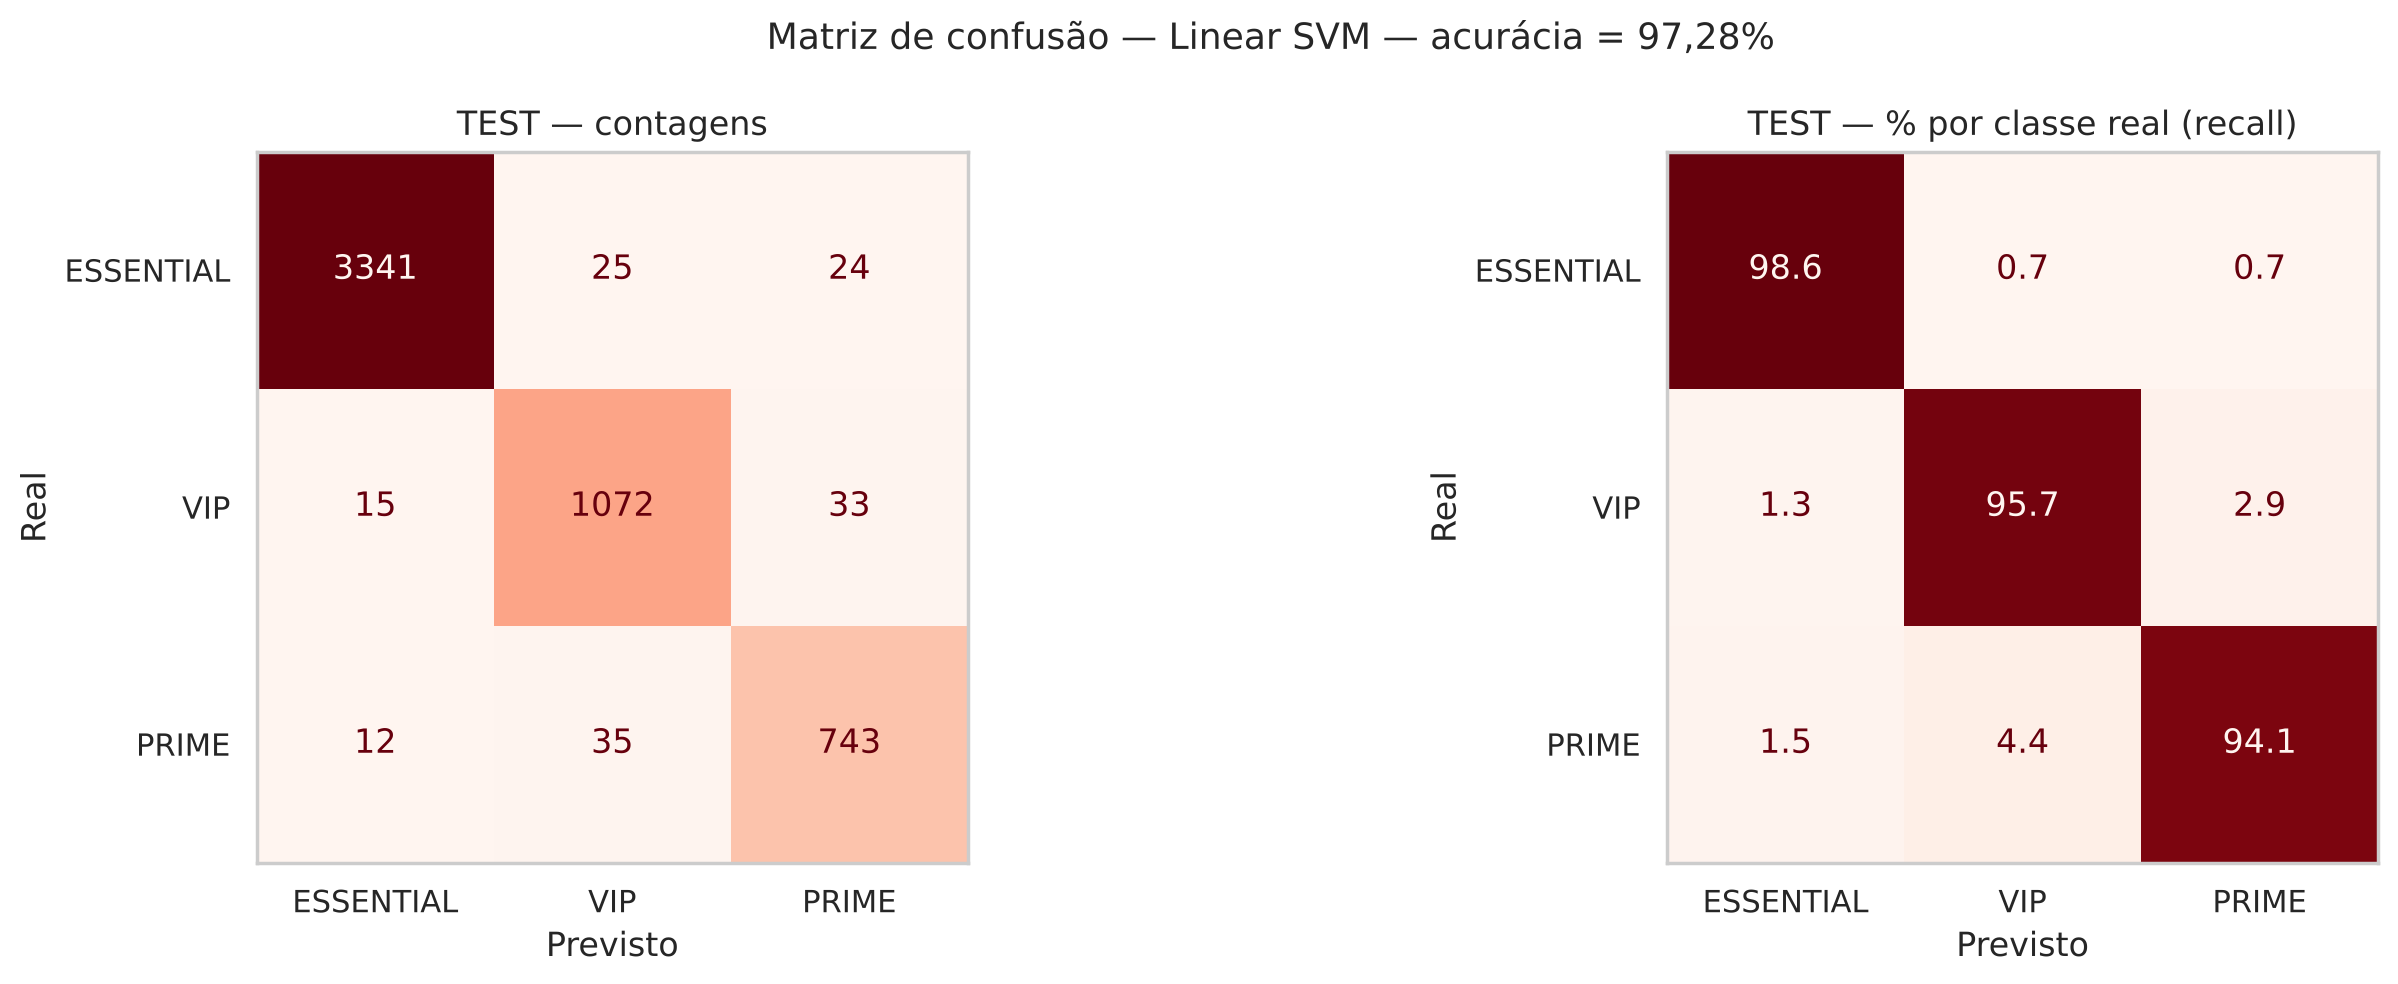

              precision    recall  f1-score   support

   ESSENTIAL     0.9920    0.9855    0.9888      3390
         VIP     0.9470    0.9571    0.9520      1120
       PRIME     0.9287    0.9405    0.9346       790

    accuracy                         0.9728      5300
   macro avg     0.9559    0.9611    0.9585      5300
weighted avg     0.9731    0.9728    0.9729      5300



In [45]:
score_clf["test"] = matriz_confusao("test")

##Atividade A3.5 (5º Passo): Testar o Modelo: Dados da População: amostra aleatória (Sample).

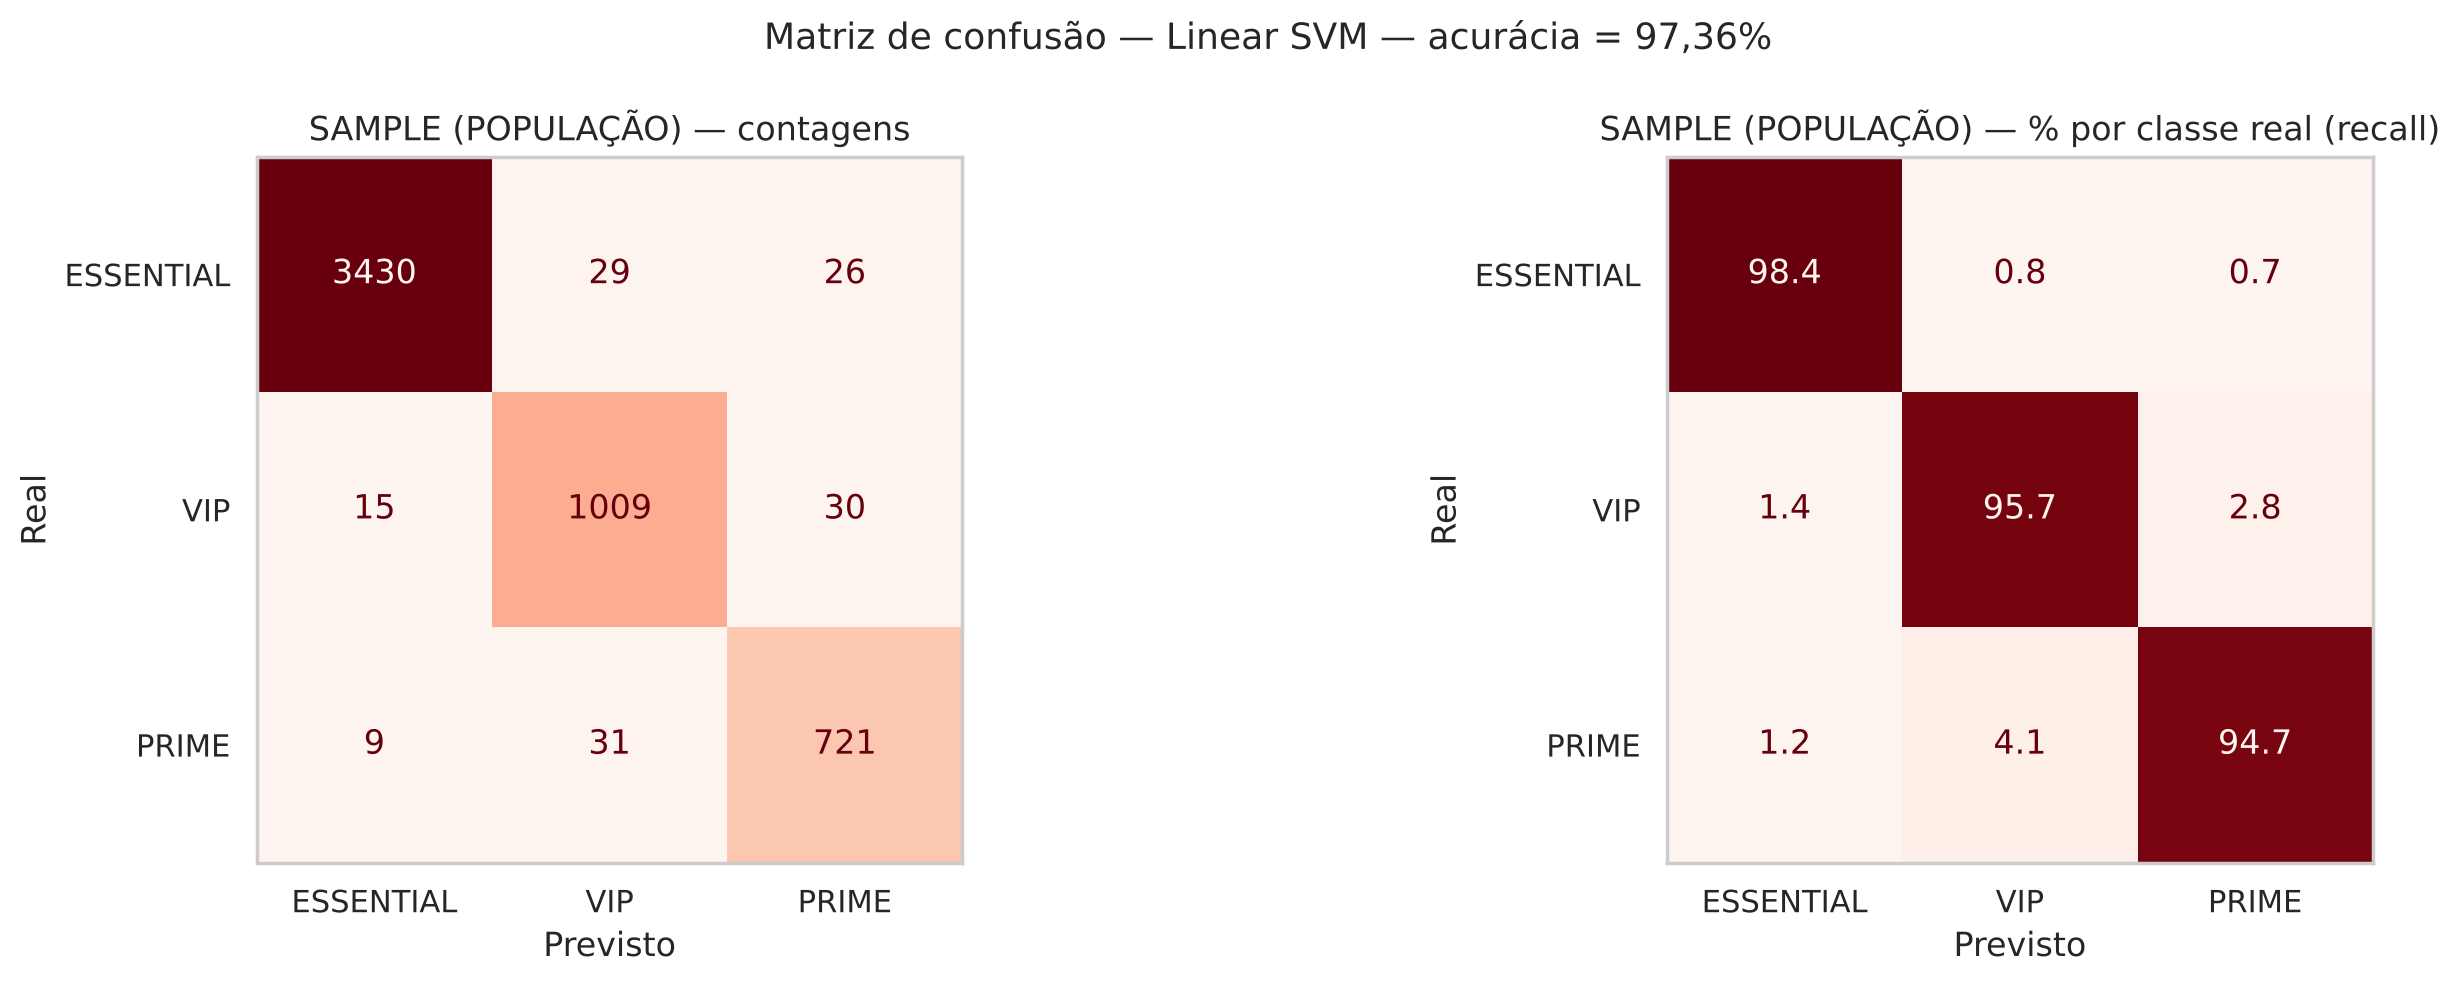

              precision    recall  f1-score   support

   ESSENTIAL     0.9931    0.9842    0.9886      3485
         VIP     0.9439    0.9573    0.9505      1054
       PRIME     0.9279    0.9474    0.9376       761

    accuracy                         0.9736      5300
   macro avg     0.9550    0.9630    0.9589      5300
weighted avg     0.9739    0.9736    0.9737      5300

Erros na sample: 140 de 5300


n  Renda mediana (R$)
TIPO DA CONTA Previsto                         
ESSENTIAL     PRIME      26         16,815.0750
              VIP        29          9,766.0700
PRIME         ESSENTIAL   9          2,939.9000
              VIP        31          9,569.9800
VIP           ESSENTIAL  15          2,890.8200
              PRIME      30         17,104.3600

,Acurácia,F1-macro,n
train,0.9719,0.9575,5300
validation,0.9723,0.9589,5300
test,0.9728,0.9585,5300
sample (população),0.9736,0.9589,5300


In [46]:
score_clf["sample (população)"] = matriz_confusao("sample (população)")
tab_score_clf = pd.DataFrame(score_clf).T
tab_score_clf["n"] = tab_score_clf["n"].astype(int)

# Quem o modelo erra? Clientes cujo plano não corresponde à renda
b = bases["sample (população)"].copy(); b["Previsto"] = [ORDEM_CONTAS[i] for i in clf.predict(Xk["sample (população)"])]
erros = b[b["Previsto"] != b["TIPO DA CONTA"]]
print(f"Erros na sample: {len(erros)} de {len(b)}")
display(erros.groupby(["TIPO DA CONTA", "Previsto"])["RENDA BRUTO (R$)"].agg(["size", "median"]).rename(
    columns={"size": "n", "median": "Renda mediana (R$)"}))
tab_score_clf

## RELATÓRIO PARCIAL - MODELO DE CLASSIFICAÇÃO

In [47]:
display(Markdown(f"""
**RELATÓRIO PARCIAL — MODELO DE CLASSIFICAÇÃO** (para os gestores da UVVine)

*   ✅ **Modelo escolhido:** {MELHOR_CLF}, com o maior SCORE entre os 10 classificadores do enunciado ({pct(tab_clf.loc[MELHOR_CLF,'Acurácia validation'])} no validation).
*   ✅ **Acurácia:** train {pct(tab_score_clf.loc['train','Acurácia'])} · validation {pct(tab_score_clf.loc['validation','Acurácia'])} · test {pct(tab_score_clf.loc['test','Acurácia'])} · sample da população {pct(tab_score_clf.loc['sample (população)','Acurácia'])}.
    IC95% bootstrap no validation: [{pct(ic_clf_val['ic_inf'])} ; {pct(ic_clf_val['ic_sup'])}]. O desempenho é estável em dados nunca vistos.
*   ✅ **Onde erra:** os erros (~{pct(1 - tab_score_clf.loc['test','Acurácia'], 1)}) concentram-se em clientes cuja **renda não corresponde ao plano contratado**. Por exemplo, clientes ESSENTIAL com renda típica de VIP ou PRIME, ou clientes PRIME com renda típica de VIP (ver a tabela de erros na sample).
    Esses casos não são falhas do modelo: são **oportunidades comerciais**, porque indicam clientes num plano acima ou abaixo do seu perfil.
*   ✅ **Uso recomendado:** sugerir automaticamente o plano adequado para cada novo cliente (~5.000 notas por dia) e gerar uma lista mensal de clientes para ações de upgrade ou retenção.
"""))


**RELATÓRIO PARCIAL — MODELO DE CLASSIFICAÇÃO** (para os gestores da UVVine)

*   ✅ **Modelo escolhido:** Linear SVM, com o maior SCORE entre os 10 classificadores do enunciado (97,23% no validation).
*   ✅ **Acurácia:** train 97,19% · validation 97,23% · test 97,28% · sample da população 97,36%.
    IC95% bootstrap no validation: [96,77% ; 97,66%]. O desempenho é estável em dados nunca vistos.
*   ✅ **Onde erra:** os erros (~2,7%) concentram-se em clientes cuja **renda não corresponde ao plano contratado**. Por exemplo, clientes ESSENTIAL com renda típica de VIP ou PRIME, ou clientes PRIME com renda típica de VIP (ver a tabela de erros na sample).
    Esses casos não são falhas do modelo: são **oportunidades comerciais**, porque indicam clientes num plano acima ou abaixo do seu perfil.
*   ✅ **Uso recomendado:** sugerir automaticamente o plano adequado para cada novo cliente (~5.000 notas por dia) e gerar uma lista mensal de clientes para ações de upgrade ou retenção.


# RELATÓRIO FINAL - VISÃO HOLÍSTICA SOBRE O PROJETO

Fazer aqui o **RELATÓRIO FINAL** com todas as conclusões e resultados que serão apresentados aos gestores da **EMPRESA:**.

In [48]:
display(Markdown(f"""
## Relatório final — visão holística do Projeto UVVine

### 1. Base estatística (Parte 1 → Parte 2)
*   ✅ A Parte 1 determinou o **tamanho ideal n = {N_IDEAL}** (estabilização do erro-padrão estratificado e otimização de Neyman sobre TOTAL). Com esse n, a margem de erro da média de gasto é de ~1,7%.
*   ✅ **train, validation e test** têm exatamente esse tamanho, são estratificados por tipo de conta e não têm nenhuma nota em comum. A **sample** de {brl(len(sample), 0)} notas da população testou cada modelo em dados inéditos.
*   ✅ Os três modelos tiveram desempenho praticamente igual em train, validation, test e sample. Isso confirma, na prática, que os conjuntos da Parte 1 são **amostras de qualidade** da população de {brl(len(populacao), 0)} notas.

### 2. Resultados dos modelos
| Modelo | Algoritmo | Métrica | Train | Validation | Test | Sample |
|---|---|---|---|---|---|---|
| Regressão (gasto) | {MELHOR_REG} | R² | {brl(tab_r2.loc['train','R²'],3)} | {brl(tab_r2.loc['validation','R²'],3)} | {brl(tab_r2.loc['test','R²'],3)} | {brl(m_s['R²'],3)} |
| Clusterização (segmentos) | K-Means (k={K}) | Silhueta / ARI | {brl(tab_clu.loc['train','Silhueta'],3)} / {brl(tab_clu.loc['train','ARI vs TIPO DA CONTA'],3)} | {brl(tab_clu.loc['validation','Silhueta'],3)} / {brl(tab_clu.loc['validation','ARI vs TIPO DA CONTA'],3)} | {brl(tab_clu.loc['test','Silhueta'],3)} / {brl(tab_clu.loc['test','ARI vs TIPO DA CONTA'],3)} | {brl(tab_clu.loc['sample (população)','Silhueta'],3)} / {brl(tab_clu.loc['sample (população)','ARI vs TIPO DA CONTA'],3)} |
| Classificação (plano) | {MELHOR_CLF} | Acurácia | {pct(tab_score_clf.loc['train','Acurácia'])} | {pct(tab_score_clf.loc['validation','Acurácia'])} | {pct(tab_score_clf.loc['test','Acurácia'])} | {pct(tab_score_clf.loc['sample (população)','Acurácia'])} |

### 3. Principais insights para a gestão
*   ✅ **A renda é o motor do negócio.** Ela explica cerca de {pct(tab_r2.loc['test','R²'], 0)} do gasto por nota, define os segmentos naturais de clientes e determina o plano com cerca de {pct(tab_score_clf.loc['test','Acurácia'], 0)} de acerto.
*   ✅ **Os planos ESSENTIAL, VIP e PRIME refletem segmentos reais** de renda e consumo. O K-Means, sem conhecer os rótulos, encontrou {K} segmentos com ARI = {brl(tab_clu['ARI vs TIPO DA CONTA'].mean(), 2)} em relação aos planos.
*   ✅ **Os clientes "fora do perfil"** (os erros do classificador e os clusters divergentes do plano) formam uma lista acionável para **upgrade, downgrade ou retenção**.
*   ✅ **A satisfação (~80% satisfeitos) não depende do segmento financeiro, e as características químicas do vinho não influenciam o gasto.** Melhorar a satisfação passa por atendimento e entrega, e não por mudanças no portfólio para um segmento específico.
*   ✅ **Projeção de receita:** o modelo de regressão estima o faturamento de um lote de notas com erro agregado de {pct(abs(p_s.sum() / y_s.sum() - 1))} na sample. É útil para planejar as ~5.000 notas diárias.

### 4. Limitações e próximos passos
*   ⚠️ O erro da regressão cresce com o valor da compra (heterocedasticidade). Um modelo do gasto relativo à renda, ou intervalos de previsão por segmento, melhoraria a precisão para o PRIME.
*   ⚠️ Os dados são simulados: as químicas têm valores negativos e não se correlacionam entre si. Com dados reais de vinho, vale reavaliar recomendação de rótulos por perfil.
*   🚀 **Próximos passos:** colocar o classificador e o regressor num pipeline diário sobre as notas novas, monitorar o desempenho mensalmente com novas amostras do tamanho ideal e cruzar com um painel de satisfação.
"""))


## Relatório final — visão holística do Projeto UVVine

### 1. Base estatística (Parte 1 → Parte 2)
*   ✅ A Parte 1 determinou o **tamanho ideal n = 5300** (estabilização do erro-padrão estratificado e otimização de Neyman sobre TOTAL). Com esse n, a margem de erro da média de gasto é de ~1,7%.
*   ✅ **train, validation e test** têm exatamente esse tamanho, são estratificados por tipo de conta e não têm nenhuma nota em comum. A **sample** de 5.300 notas da população testou cada modelo em dados inéditos.
*   ✅ Os três modelos tiveram desempenho praticamente igual em train, validation, test e sample. Isso confirma, na prática, que os conjuntos da Parte 1 são **amostras de qualidade** da população de 1.120.000 notas.

### 2. Resultados dos modelos
| Modelo | Algoritmo | Métrica | Train | Validation | Test | Sample |
|---|---|---|---|---|---|---|
| Regressão (gasto) | Lasso | R² | 0,749 | 0,752 | 0,754 | 0,745 |
| Clusterização (segmentos) | K-Means (k=3) | Silhueta / ARI | 0,630 / 0,927 | 0,623 / 0,925 | 0,625 / 0,929 | 0,622 / 0,931 |
| Classificação (plano) | Linear SVM | Acurácia | 97,19% | 97,23% | 97,28% | 97,36% |

### 3. Principais insights para a gestão
*   ✅ **A renda é o motor do negócio.** Ela explica cerca de 75% do gasto por nota, define os segmentos naturais de clientes e determina o plano com cerca de 97% de acerto.
*   ✅ **Os planos ESSENTIAL, VIP e PRIME refletem segmentos reais** de renda e consumo. O K-Means, sem conhecer os rótulos, encontrou 3 segmentos com ARI = 0,93 em relação aos planos.
*   ✅ **Os clientes "fora do perfil"** (os erros do classificador e os clusters divergentes do plano) formam uma lista acionável para **upgrade, downgrade ou retenção**.
*   ✅ **A satisfação (~80% satisfeitos) não depende do segmento financeiro, e as características químicas do vinho não influenciam o gasto.** Melhorar a satisfação passa por atendimento e entrega, e não por mudanças no portfólio para um segmento específico.
*   ✅ **Projeção de receita:** o modelo de regressão estima o faturamento de um lote de notas com erro agregado de 1,54% na sample. É útil para planejar as ~5.000 notas diárias.

### 4. Limitações e próximos passos
*   ⚠️ O erro da regressão cresce com o valor da compra (heterocedasticidade). Um modelo do gasto relativo à renda, ou intervalos de previsão por segmento, melhoraria a precisão para o PRIME.
*   ⚠️ Os dados são simulados: as químicas têm valores negativos e não se correlacionam entre si. Com dados reais de vinho, vale reavaliar recomendação de rótulos por perfil.
*   🚀 **Próximos passos:** colocar o classificador e o regressor num pipeline diário sobre as notas novas, monitorar o desempenho mensalmente com novas amostras do tamanho ideal e cruzar com um painel de satisfação.


# EXPORTAR PARA HTML / PDF

In [49]:
# EXPORTAR PARA HTML (pronto para imprimir em PDF sem cortes)
# 1) Salve o notebook (Arquivo > Fazer download > .ipynb) e envie para a aba "Arquivos" do Colab (/content)
# 2) Ajuste o nome abaixo, se for diferente, e execute esta célula
import os, subprocess
NOTEBOOK = "/content/TCC_Parte2.ipynb"
HTML = NOTEBOOK.replace(".ipynb", ".html")
PRINT_CSS = """
<style>
@page { size: A4; margin: 12mm 10mm; }
body { max-width: 190mm; margin: 0 auto !important; padding: 0 !important; }
.jp-Notebook, .jp-Cell, .jp-OutputArea, .jp-InputArea, .jp-OutputArea-child, .jp-OutputArea-output { max-width: 100% !important; overflow: visible !important; }
.jp-InputPrompt, .jp-OutputPrompt { display: none !important; }
.jp-InputArea-editor, .jp-OutputArea-output, .jp-RenderedHTMLCommon { margin-left: 0 !important; width: 100% !important; }
pre, code, .jp-RenderedText pre, .highlight pre { white-space: pre-wrap !important; word-break: break-word !important; overflow-wrap: anywhere !important; font-size: 8.5px !important; line-height: 1.3 !important; }
.jp-RenderedMarkdown { font-size: 12px !important; line-height: 1.5 !important; }
.jp-RenderedHTMLCommon table { font-size: 8px !important; table-layout: auto !important; width: auto !important; max-width: 100% !important; margin: 4px 0 !important; }
.jp-RenderedHTMLCommon th, .jp-RenderedHTMLCommon td { padding: 2px 4px !important; white-space: normal !important; word-break: break-word !important; }
.jp-RenderedMarkdown table { font-size: 10.5px !important; }
img { max-width: 100% !important; height: auto !important; page-break-inside: avoid; break-inside: avoid; }
.jp-OutputArea-output, tr, .jp-RenderedImage { page-break-inside: avoid; break-inside: avoid; }
h1, h2, h3, h4 { page-break-after: avoid; break-after: avoid; }
@media print { .jp-Cell { page-break-inside: auto; } }
</style>
"""

if os.path.exists(NOTEBOOK):
    subprocess.run(["jupyter", "nbconvert", "--to", "html", NOTEBOOK, "--output", HTML], check=True)
    with open(HTML, encoding="utf-8") as f:
        html = f.read().replace("</head>", PRINT_CSS + "</head>", 1)
    with open(HTML, "w", encoding="utf-8") as f:
        f.write(html)
    print("HTML gerado:", HTML, "-> abra no navegador e use Ctrl+P > Salvar como PDF (A4)")
    try:
        from google.colab import files
        files.download(HTML)
    except ImportError:
        pass
else:
    print("Arquivo não encontrado:", NOTEBOOK, "-> envie o .ipynb para /content e execute de novo.")


Arquivo não encontrado: /content/TCC_Parte2.ipynb -> envie o .ipynb para /content e execute de novo.
